## Step 1: Set up Jupyter Notebook & Load the Dataset

In [1]:
# Step 1: Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
# Configure the display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

In [3]:
# Set the visualisation theme
sns.set_theme(style="whitegrid")

In [4]:
# Display a confirmation message
print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully!
Pandas version: 3.0.3
NumPy version: 2.4.6


In [5]:
# Step 1.3: Define the dataset path

from pathlib import Path

file_path = Path("Retail_Analysis/online_retail_II.xlsx")

# Check whether the dataset exists
if not file_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {file_path.resolve()}\n"
        "Please place online_retail_II.xlsx in the same folder as your notebook."
    )

# Display dataset information
print("Dataset found successfully!")
print("File location:", file_path.resolve())
print(f"File size: {file_path.stat().st_size / (1024 ** 2):.2f} MB")

Dataset found successfully!
File location: C:\Users\ADITYA\Retail_Analysis\online_retail_II.xlsx
File size: 43.51 MB


In [6]:
# Step 1.4: Inspect the Excel workbook

import pandas as pd

# Open the Excel workbook
excel_file = pd.ExcelFile(file_path)

# Display the available worksheets
print("Workbook loaded successfully!")
print("\nAvailable worksheets:")

for sheet in excel_file.sheet_names:
    print("-", sheet)

# Display the total number of worksheets
print("\nTotal worksheets:", len(excel_file.sheet_names))

Workbook loaded successfully!

Available worksheets:
- Year 2009-2010
- Year 2010-2011

Total worksheets: 2


In [7]:
# Step 1.5: Load each worksheet and inspect its structure

# Create an empty dictionary to store the worksheets
sheet_data = {}

# Load and inspect each worksheet
for sheet in excel_file.sheet_names:

    # Read the current worksheet
    df = pd.read_excel(excel_file, sheet_name=sheet)

    # Store the DataFrame in the dictionary
    sheet_data[sheet] = df

    # Display worksheet information
    print("\n" + "=" * 70)
    print(f"WORKSHEET: {sheet}")
    print("=" * 70)

    # Display dataset dimensions
    print("\nNumber of rows:", df.shape[0])
    print("Number of columns:", df.shape[1])

    # Display column names
    print("\nColumn names:")
    print(df.columns.tolist())

    # Display data types
    print("\nData types:")
    print(df.dtypes)

    # Display the first five rows
    print("\nFirst five rows:")
    display(df.head())

print("\n" + "=" * 70)
print("Both worksheets have been loaded successfully!")
print("=" * 70)


WORKSHEET: Year 2009-2010

Number of rows: 525461
Number of columns: 8

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

First five rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



WORKSHEET: Year 2010-2011

Number of rows: 541910
Number of columns: 8

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

First five rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Both worksheets have been loaded successfully!


In [8]:
# Step 1.6: Validate the schema of both worksheets

# Get the names of the loaded worksheets
sheet_names = list(sheet_data.keys())

# Check whether both worksheets have been loaded
if len(sheet_names) < 2:
    print("Warning: Fewer than two worksheets are loaded.")

else:
    # Select the first and second worksheets
    first_sheet = sheet_data[sheet_names[0]]
    second_sheet = sheet_data[sheet_names[1]]

    # Compare column names and their order
    same_columns = first_sheet.columns.equals(second_sheet.columns)

    print("Worksheet 1:", sheet_names[0])
    print("Worksheet 2:", sheet_names[1])

    print("\nDo both worksheets have identical column names and order?")
    print(same_columns)

    # Display the columns for comparison
    print("\nColumns in the first worksheet:")
    print(first_sheet.columns.tolist())

    print("\nColumns in the second worksheet:")
    print(second_sheet.columns.tolist())

    # Display the result
    if same_columns:
        print("\nValidation successful: Both worksheets have the same schema.")
    else:
        print("\nValidation failed: The worksheet schemas differ.")

Worksheet 1: Year 2009-2010
Worksheet 2: Year 2010-2011

Do both worksheets have identical column names and order?
True

Columns in the first worksheet:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Columns in the second worksheet:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Validation successful: Both worksheets have the same schema.


## Step 2: Data Quality Audit — Retail Revenue & Customer Intelligence

In [9]:
# ============================================================
# STEP 2.1: MISSING VALUE AUDIT
# ============================================================

# Store missing-value summaries for both worksheets
missing_summaries = {}

for sheet_name, df in sheet_data.items():

    # Count missing values in each column
    missing_count = df.isna().sum()

    # Calculate the percentage of missing values
    missing_percentage = (missing_count / len(df)) * 100

    # Create a summary table
    missing_summary = pd.DataFrame({
        "Missing Values": missing_count,
        "Missing Percentage (%)": missing_percentage.round(2)
    })

    # Sort columns by missing-value count
    missing_summary = missing_summary.sort_values(
        by="Missing Values",
        ascending=False
    )

    # Store the summary
    missing_summaries[sheet_name] = missing_summary

    # Display results
    print("\n" + "=" * 65)
    print(f"MISSING VALUE AUDIT: {sheet_name}")
    print("=" * 65)

    display(missing_summary)

    # Display the number of rows with at least one missing value
    rows_with_missing = df.isna().any(axis=1).sum()

    print(
        f"Rows containing at least one missing value: "
        f"{rows_with_missing:,} "
        f"({rows_with_missing / len(df) * 100:.2f}%)"
    )

print("\nMissing-value audit completed for both worksheets.")


MISSING VALUE AUDIT: Year 2009-2010


,Missing Values,Missing Percentage (%)
Customer ID,107927,20.54
Description,2928,0.56
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


Rows containing at least one missing value: 107,927 (20.54%)

MISSING VALUE AUDIT: Year 2010-2011


,Missing Values,Missing Percentage (%)
Customer ID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


Rows containing at least one missing value: 135,080 (24.93%)

Missing-value audit completed for both worksheets.


In [10]:
# ============================================================
# STEP 2.2: DUPLICATE RECORD AUDIT
# ============================================================

duplicate_summaries = {}

for sheet_name, df in sheet_data.items():

    # Identify exact duplicate rows
    duplicate_mask = df.duplicated(keep="first")

    # Count duplicate rows
    duplicate_count = duplicate_mask.sum()

    # Calculate the percentage of duplicate rows
    duplicate_percentage = (duplicate_count / len(df)) * 100

    # Store the results
    duplicate_summaries[sheet_name] = {
        "Total Rows": len(df),
        "Duplicate Rows": int(duplicate_count),
        "Duplicate Percentage (%)": round(duplicate_percentage, 2)
    }

    # Display the results
    print("\n" + "=" * 65)
    print(f"DUPLICATE AUDIT: {sheet_name}")
    print("=" * 65)

    print(f"Total rows: {len(df):,}")
    print(f"Duplicate rows: {duplicate_count:,}")
    print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

    # Display examples for investigation
    if duplicate_count > 0:
        print("\nFirst five duplicate rows:")
        display(df.loc[duplicate_mask].head())

# Create a summary table for both worksheets
duplicate_summary_df = pd.DataFrame.from_dict(
    duplicate_summaries,
    orient="index"
)

print("\n" + "=" * 65)
print("OVERALL DUPLICATE SUMMARY")
print("=" * 65)

display(duplicate_summary_df)


DUPLICATE AUDIT: Year 2009-2010
Total rows: 525,461
Duplicate rows: 6,865
Duplicate percentage: 1.31%

First five duplicate rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom



DUPLICATE AUDIT: Year 2010-2011
Total rows: 541,910
Duplicate rows: 5,268
Duplicate percentage: 0.97%

First five duplicate rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom



OVERALL DUPLICATE SUMMARY


,Total Rows,Duplicate Rows,Duplicate Percentage (%)
Year 2009-2010,525461,6865,1.31
Year 2010-2011,541910,5268,0.97


In [11]:
# ============================================================
# STEP 2.3: INVESTIGATE DATE OVERLAP
# ============================================================

# Retrieve both worksheets
df_2009_2010 = sheet_data["Year 2009-2010"]
df_2010_2011 = sheet_data["Year 2010-2011"]

# Inspect the date ranges
print("=" * 70)
print("DATE RANGE ANALYSIS")
print("=" * 70)

print("\nYear 2009-2010 worksheet")
print("Earliest date:", df_2009_2010["InvoiceDate"].min())
print("Latest date:  ", df_2009_2010["InvoiceDate"].max())
print("Total rows:   ", f"{len(df_2009_2010):,}")

print("\nYear 2010-2011 worksheet")
print("Earliest date:", df_2010_2011["InvoiceDate"].min())
print("Latest date:  ", df_2010_2011["InvoiceDate"].max())
print("Total rows:   ", f"{len(df_2010_2011):,}")

# Identify the shared calendar-date range
start_overlap = max(
    df_2009_2010["InvoiceDate"].min().normalize(),
    df_2010_2011["InvoiceDate"].min().normalize()
)

end_overlap = min(
    df_2009_2010["InvoiceDate"].max().normalize(),
    df_2010_2011["InvoiceDate"].max().normalize()
)

print("\n" + "=" * 70)
print("POTENTIAL DATE OVERLAP")
print("=" * 70)

if start_overlap <= end_overlap:
    print("Potential overlap starts:", start_overlap.date())
    print("Potential overlap ends:  ", end_overlap.date())
else:
    print("No overlapping calendar dates identified.")

DATE RANGE ANALYSIS

Year 2009-2010 worksheet
Earliest date: 2009-12-01 07:45:00
Latest date:   2010-12-09 20:01:00
Total rows:    525,461

Year 2010-2011 worksheet
Earliest date: 2010-12-01 08:26:00
Latest date:   2011-12-09 12:50:00
Total rows:    541,910

POTENTIAL DATE OVERLAP
Potential overlap starts: 2010-12-01
Potential overlap ends:   2010-12-09


In [12]:
# ============================================================
# STEP 2.3.1: COUNT RECORDS IN THE POTENTIAL OVERLAP
# ============================================================

if start_overlap <= end_overlap:

    # Build a mask for records within the overlapping dates
    mask_2009_2010 = (
        df_2009_2010["InvoiceDate"].dt.normalize()
        .between(start_overlap, end_overlap)
    )

    mask_2010_2011 = (
        df_2010_2011["InvoiceDate"].dt.normalize()
        .between(start_overlap, end_overlap)
    )

    # Count overlapping-period records in each worksheet
    overlap_records_2009_2010 = df_2009_2010.loc[mask_2009_2010]
    overlap_records_2010_2011 = df_2010_2011.loc[mask_2010_2011]

    print("=" * 70)
    print("RECORDS WITHIN THE POTENTIAL OVERLAP")
    print("=" * 70)

    print(
        "\nRecords in Year 2009-2010 within the shared date range:",
        f"{len(overlap_records_2009_2010):,}"
    )

    print(
        "Records in Year 2010-2011 within the shared date range:",
        f"{len(overlap_records_2010_2011):,}"
    )

    print("\nFirst five records from the first worksheet:")
    display(overlap_records_2009_2010.head())

    print("\nFirst five records from the second worksheet:")
    display(overlap_records_2010_2011.head())

else:
    print("No shared date range exists, so an overlap count is unnecessary.")

RECORDS WITHIN THE POTENTIAL OVERLAP

Records in Year 2009-2010 within the shared date range: 22,523
Records in Year 2010-2011 within the shared date range: 22,523

First five records from the first worksheet:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
502938,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
502939,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
502940,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
502941,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
502942,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



First five records from the second worksheet:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [13]:
# ============================================================
# STEP 2.3.2: VERIFY EXACT OVERLAP BETWEEN WORKSHEETS
# ============================================================

# Reset indexes so that row positions do not affect comparison
overlap_first = overlap_records_2009_2010.reset_index(drop=True)
overlap_second = overlap_records_2010_2011.reset_index(drop=True)

# Check whether both overlapping datasets have the same dimensions
print("=" * 70)
print("OVERLAPPING DATA COMPARISON")
print("=" * 70)

print("\nFirst worksheet overlap shape:", overlap_first.shape)
print("Second worksheet overlap shape:", overlap_second.shape)

# Check whether all rows match in the same order
same_order = overlap_first.equals(overlap_second)

print("\nAre all rows identical in the same order?")
print(same_order)

# Create row hashes using all columns, excluding the index
hashes_first = pd.util.hash_pandas_object(
    overlap_first,
    index=False
)

hashes_second = pd.util.hash_pandas_object(
    overlap_second,
    index=False
)

# Compare the frequency of each row, regardless of row order
row_counts_first = hashes_first.value_counts().sort_index()
row_counts_second = hashes_second.value_counts().sort_index()

same_rows_and_frequencies = row_counts_first.equals(row_counts_second)

print("\nDo both worksheets contain the same rows with the same frequencies?")
print(same_rows_and_frequencies)

# Summarise the findings
print("\n" + "=" * 70)
print("OVERLAP VERIFICATION SUMMARY")
print("=" * 70)

if same_order:
    print("Result: All overlapping rows match in the same order.")
elif same_rows_and_frequencies:
    print("Result: The overlapping rows match, but their order differs.")
else:
    print("Result: The overlapping records differ; further investigation is needed.")

print("\nNo records have been deleted or modified.")

OVERLAPPING DATA COMPARISON

First worksheet overlap shape: (22523, 8)
Second worksheet overlap shape: (22523, 8)

Are all rows identical in the same order?
False

Do both worksheets contain the same rows with the same frequencies?
True

OVERLAP VERIFICATION SUMMARY
Result: The overlapping rows match, but their order differs.

No records have been deleted or modified.


In [14]:
# ============================================================
# STEP 2.4: QUANTITY VALUE AUDIT
# ============================================================

for sheet_name, df in sheet_data.items():

    print("\n" + "=" * 70)
    print(f"QUANTITY AUDIT: {sheet_name}")
    print("=" * 70)

    # Basic descriptive statistics
    print("\nQuantity descriptive statistics:")
    display(df["Quantity"].describe())

    # Count negative, zero, and positive quantities
    negative_count = (df["Quantity"] < 0).sum()
    zero_count = (df["Quantity"] == 0).sum()
    positive_count = (df["Quantity"] > 0).sum()

    # Calculate percentages
    total_rows = len(df)

    print("\nQuantity categories:")
    print(
        f"Negative quantities: {negative_count:,} "
        f"({negative_count / total_rows * 100:.2f}%)"
    )
    print(
        f"Zero quantities: {zero_count:,} "
        f"({zero_count / total_rows * 100:.2f}%)"
    )
    print(
        f"Positive quantities: {positive_count:,} "
        f"({positive_count / total_rows * 100:.2f}%)"
    )

    # Display examples of negative quantities
    print("\nFirst five records with negative quantities:")
    display(df.loc[df["Quantity"] < 0].head())

    # Display examples of zero quantities
    print("\nFirst five records with zero quantities:")
    display(df.loc[df["Quantity"] == 0].head())


QUANTITY AUDIT: Year 2009-2010

Quantity descriptive statistics:


count    525461.000000
mean         10.337667
std         107.424110
min       -9600.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       19152.000000
Name: Quantity, dtype: float64


Quantity categories:
Negative quantities: 12,326 (2.35%)
Zero quantities: 0 (0.00%)
Positive quantities: 513,135 (97.65%)

First five records with negative quantities:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia



First five records with zero quantities:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country


... (2 outputs left out)


Quantity categories:
Negative quantities: 10,624 (1.96%)
Zero quantities: 0 (0.00%)
Positive quantities: 531,286 (98.04%)

First five records with negative quantities:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom



First five records with zero quantities:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country


In [15]:
# ============================================================
# STEP 2.5: PRICE VALUE AUDIT
# ============================================================

for sheet_name, df in sheet_data.items():

    print("\n" + "=" * 70)
    print(f"PRICE AUDIT: {sheet_name}")
    print("=" * 70)

    # Descriptive statistics
    print("\nPrice descriptive statistics:")
    display(df["Price"].describe())

    # Count price categories
    negative_prices = (df["Price"] < 0).sum()
    zero_prices = (df["Price"] == 0).sum()
    positive_prices = (df["Price"] > 0).sum()

    total_rows = len(df)

    print("\nPrice categories:")

    print(
        f"Negative prices: {negative_prices:,} "
        f"({negative_prices / total_rows * 100:.2f}%)"
    )

    print(
        f"Zero prices: {zero_prices:,} "
        f"({zero_prices / total_rows * 100:.2f}%)"
    )

    print(
        f"Positive prices: {positive_prices:,} "
        f"({positive_prices / total_rows * 100:.2f}%)"
    )

    # Display examples of negative prices
    print("\nFirst five records with negative prices:")
    display(df.loc[df["Price"] < 0].head())

    # Display examples of zero prices
    print("\nFirst five records with zero prices:")
    display(df.loc[df["Price"] == 0].head())

    # Display records with the highest prices
    print("\nFive records with the highest prices:")
    display(df.nlargest(5, "Price"))


PRICE AUDIT: Year 2009-2010

Price descriptive statistics:


count    525461.000000
mean          4.688834
std         146.126914
min      -53594.360000
25%           1.250000
50%           2.100000
75%           4.210000
max       25111.090000
Name: Price, dtype: float64


Price categories:
Negative prices: 3 (0.00%)
Zero prices: 3,687 (0.70%)
Positive prices: 521,771 (99.30%)

First five records with negative prices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom



First five records with zero prices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom


... (6 outputs left out)


First five records with zero prices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1510,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1985,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1986,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
2022,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom



Five records with the highest prices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom
524602,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom
43702,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,NaN,United Kingdom
43703,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,NaN,United Kingdom
15016,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,13541.33,NaN,United Kingdom


In [16]:
# STEP 2.6: INVOICE CANCELLATION AUDIT

for sheet_name, df in sheet_data.items():

    print("\n" + "=" * 70)
    print(f"INVOICE CANCELLATION AUDIT: {sheet_name}")
    print("=" * 70)

    # Identify cancellation invoices
    cancellation_mask = (
        df["Invoice"]
        .astype("string")
        .str.startswith("C", na=False)
    )

    cancellation_records = df.loc[cancellation_mask]

    # Identify records with negative quantities
    negative_quantity_mask = df["Quantity"] < 0

    # Summary counts
    total_records = len(df)
    cancellation_count = int(cancellation_mask.sum())
    negative_quantity_count = int(negative_quantity_mask.sum())

    print(f"\nTotal records: {total_records:,}")

    print(
        f"Cancellation invoice records: "
        f"{cancellation_count:,} "
        f"({cancellation_count / total_records * 100:.2f}%)"
    )

    print(
        f"Records with negative quantities: "
        f"{negative_quantity_count:,} "
        f"({negative_quantity_count / total_records * 100:.2f}%)"
    )

    print(
        f"Cancellation records with negative quantities: "
        f"{(cancellation_mask & negative_quantity_mask).sum():,}"
    )

    print(
        f"Cancellation records with positive quantities: "
        f"{(cancellation_mask & (df['Quantity'] > 0)).sum():,}"
    )

    print(
        f"Cancellation records with zero quantities: "
        f"{(cancellation_mask & (df['Quantity'] == 0)).sum():,}"
    )

    # Inspect cancellation records
    print("\nFirst 10 cancellation records:")

    display(
        cancellation_records[
            [
                "Invoice",
                "StockCode",
                "Description",
                "Quantity",
                "InvoiceDate",
                "Price",
                "Customer ID",
                "Country"
            ]
        ].head(10)
    )

    # Inspect negative quantities on non-cancellation invoices
    print("\nFirst 10 negative-quantity records with non-C invoices:")

    display(
        df.loc[
            (~cancellation_mask) & negative_quantity_mask,
            [
                "Invoice",
                "StockCode",
                "Description",
                "Quantity",
                "InvoiceDate",
                "Price",
                "Customer ID",
                "Country"
            ]
        ].head(10)
    )


INVOICE CANCELLATION AUDIT: Year 2009-2010

Total records: 525,461
Cancellation invoice records: 10,206 (1.94%)
Records with negative quantities: 12,326 (2.35%)
Cancellation records with negative quantities: 10,205
Cancellation records with positive quantities: 1
Cancellation records with zero quantities: 0

First 10 cancellation records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom



First 10 negative-quantity records with non-C invoices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom



INVOICE CANCELLATION AUDIT: Year 2010-2011

Total records: 541,910
Cancellation invoice records: 9,288 (1.71%)
Records with negative quantities: 10,624 (1.96%)
Cancellation records with negative quantities: 9,288
Cancellation records with positive quantities: 0
Cancellation records with zero quantities: 0

First 10 cancellation records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
937,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom



First 10 negative-quantity records with non-C invoices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [17]:
# STEP 2.7: UNUSUAL TRANSACTION DESCRIPTION AUDIT

unusual_keywords = [
    "ADJUST BAD DEBT",
    "AMAZON FEE",
    "BANK CHARGES",
    "DISCOUNT",
    "MANUAL",
    "POSTAGE",
    "CARRIAGE",
    "DAMAGE",
    "DAMAGES",
    "LOST",
    "MISSING",
    "SHORT",
    "SAMPLES",
    "DOTCOM POSTAGE",
    "CRUK"
]

for sheet_name, df in sheet_data.items():

    print("\n" + "=" * 80)
    print(f"UNUSUAL TRANSACTION AUDIT: {sheet_name}")
    print("=" * 80)

    # Standardize descriptions for searching only.
    # This does not modify the original dataset.
    description_text = (
        df["Description"]
        .astype("string")
        .str.upper()
    )

    for keyword in unusual_keywords:

        mask = description_text.str.contains(
            keyword,
            regex=False,
            na=False
        )

        count = int(mask.sum())

        if count > 0:
            print(f"\nKeyword: {keyword} | Records: {count:,}")

            display(
                df.loc[
                    mask,
                    [
                        "Invoice",
                        "StockCode",
                        "Description",
                        "Quantity",
                        "InvoiceDate",
                        "Price",
                        "Customer ID",
                        "Country"
                    ]
                ].head(3)
            )


UNUSUAL TRANSACTION AUDIT: Year 2009-2010

Keyword: ADJUST BAD DEBT | Records: 3


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom



Keyword: AMAZON FEE | Records: 9


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
440688,C531400,AMAZONFEE,AMAZON FEE,-1,2010-11-08 10:08:00,6706.71,NaN,United Kingdom
440698,531411,AMAZONFEE,AMAZON FEE,1,2010-11-08 10:11:00,6706.71,NaN,United Kingdom
517452,C537600,AMAZONFEE,AMAZON FEE,-1,2010-12-07 12:41:00,1.00,NaN,United Kingdom



Keyword: BANK CHARGES | Records: 65


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
18410,C490943,BANK CHARGES,Bank Charges,-1,2009-12-08 14:08:00,15.00,16703.0,United Kingdom
18466,490948,BANK CHARGES,Bank Charges,1,2009-12-08 14:29:00,15.00,16805.0,United Kingdom
33435,C492206,BANK CHARGES,Bank Charges,-1,2009-12-15 16:32:00,848.43,NaN,United Kingdom


... (46 outputs left out)


Keyword: DOTCOM POSTAGE | Records: 709


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1815,536544,DOT,DOTCOM POSTAGE,1,2010-12-01 14:32:00,569.77,NaN,United Kingdom
3041,536592,DOT,DOTCOM POSTAGE,1,2010-12-01 17:06:00,607.49,NaN,United Kingdom
5450,536862,DOT,DOTCOM POSTAGE,1,2010-12-03 11:13:00,254.43,NaN,United Kingdom



Keyword: CRUK | Records: 16


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
317508,C564763,CRUK,CRUK Commission,-1,2011-08-30 10:49:00,1.60,14096.0,United Kingdom
324003,C565382,CRUK,CRUK Commission,-1,2011-09-02 15:45:00,13.01,14096.0,United Kingdom
333745,C566216,CRUK,CRUK Commission,-1,2011-09-09 15:17:00,15.96,14096.0,United Kingdom


In [18]:
# STEP 2.8: WORKSHEET OVERLAP SUMMARY

df_2009 = sheet_data["Year 2009-2010"]
df_2010 = sheet_data["Year 2010-2011"]

# Define the overlapping date window
overlap_start = pd.Timestamp("2010-12-01")
overlap_end = pd.Timestamp("2010-12-09 23:59:59")

# Identify overlapping-period records
overlap_2009 = df_2009.loc[
    df_2009["InvoiceDate"].between(overlap_start, overlap_end)
].copy()

overlap_2010 = df_2010.loc[
    df_2010["InvoiceDate"].between(overlap_start, overlap_end)
].copy()

# Calculate the combined row count before removing overlap
combined_rows_before = len(df_2009) + len(df_2010)

# Calculate the expected row count if one copy of the overlap is excluded
combined_rows_after = combined_rows_before - len(overlap_2009)

print("=" * 70)
print("WORKSHEET OVERLAP SUMMARY")
print("=" * 70)

print(f"Rows in Year 2009-2010: {len(df_2009):,}")
print(f"Rows in Year 2010-2011: {len(df_2010):,}")

print(f"\nOverlap start: {overlap_start}")
print(f"Overlap end: {overlap_end}")

print(f"\nOverlapping rows in first worksheet: {len(overlap_2009):,}")
print(f"Overlapping rows in second worksheet: {len(overlap_2010):,}")

print(f"\nCombined rows before overlap handling: {combined_rows_before:,}")
print(f"Expected rows after excluding one overlap copy: {combined_rows_after:,}")

print("\nDate ranges:")

print(
    "First worksheet:",
    df_2009["InvoiceDate"].min(),
    "to",
    df_2009["InvoiceDate"].max()
)

print(
    "Second worksheet:",
    df_2010["InvoiceDate"].min(),
    "to",
    df_2010["InvoiceDate"].max()
)

WORKSHEET OVERLAP SUMMARY
Rows in Year 2009-2010: 525,461
Rows in Year 2010-2011: 541,910

Overlap start: 2010-12-01 00:00:00
Overlap end: 2010-12-09 23:59:59

Overlapping rows in first worksheet: 22,523
Overlapping rows in second worksheet: 22,523

Combined rows before overlap handling: 1,067,371
Expected rows after excluding one overlap copy: 1,044,848

Date ranges:
First worksheet: 2009-12-01 07:45:00 to 2010-12-09 20:01:00
Second worksheet: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [19]:
# STEP 2.9: VERIFY OVERLAPPING RECORDS

comparison_columns = list(df_2009.columns)

# Sort the overlapping rows so row order does not affect comparison.
overlap_first_sorted = (
    overlap_2009[comparison_columns]
    .sort_values(
        by=comparison_columns,
        na_position="first",
        kind="mergesort"
    )
    .reset_index(drop=True)
)

overlap_second_sorted = (
    overlap_2010[comparison_columns]
    .sort_values(
        by=comparison_columns,
        na_position="first",
        kind="mergesort"
    )
    .reset_index(drop=True)
)

print("=" * 70)
print("OVERLAP RECORD VERIFICATION")
print("=" * 70)

print(
    "First overlap shape:",
    overlap_first_sorted.shape
)

print(
    "Second overlap shape:",
    overlap_second_sorted.shape
)

print(
    "\nDo both overlapping datasets match completely?",
    overlap_first_sorted.equals(overlap_second_sorted)
)

# Compare duplicate frequencies in the overlap.
first_hash_counts = (
    pd.util.hash_pandas_object(
        overlap_2009[comparison_columns],
        index=False
    )
    .value_counts()
    .sort_index()
)

second_hash_counts = (
    pd.util.hash_pandas_object(
        overlap_2010[comparison_columns],
        index=False
    )
    .value_counts()
    .sort_index()
)

print(
    "Do overlapping row-hash frequencies match?",
    first_hash_counts.equals(second_hash_counts)
)

print(
    "Distinct row hashes in first overlap:",
    first_hash_counts.size
)

print(
    "Distinct row hashes in second overlap:",
    second_hash_counts.size
)

OVERLAP RECORD VERIFICATION
First overlap shape: (22523, 8)
Second overlap shape: (22523, 8)

Do both overlapping datasets match completely? True
Do overlapping row-hash frequencies match? True
Distinct row hashes in first overlap: 22202
Distinct row hashes in second overlap: 22202


In [20]:
# STEP 2.10: CONSOLIDATE BOTH WORKSHEETS
# Original DataFrames remain unchanged.

import pandas as pd

# Define the verified overlap period
overlap_start = pd.Timestamp("2010-12-01 00:00:00")
overlap_end = pd.Timestamp("2010-12-09 23:59:59")

# Keep all records from the first worksheet
df_2009_preserved = df_2009.copy()

# Exclude the already verified overlap from the second worksheet
df_2010_no_overlap = df_2010.loc[
    ~df_2010["InvoiceDate"].between(
        overlap_start,
        overlap_end,
        inclusive="both"
    )
].copy()

# Consolidate into a new DataFrame
df_combined = pd.concat(
    [df_2009_preserved, df_2010_no_overlap],
    ignore_index=True
)

# Validate the consolidation
expected_rows = len(df_2009) + len(df_2010) - len(overlap_2010)

print("=" * 70)
print("DATASET CONSOLIDATION REPORT")
print("=" * 70)

print(f"Rows in first worksheet:       {len(df_2009):,}")
print(f"Rows in second worksheet:      {len(df_2010):,}")
print(f"Verified overlap rows excluded: {len(overlap_2010):,}")
print(f"Expected combined rows:        {expected_rows:,}")
print(f"Actual combined rows:          {len(df_combined):,}")

print("\n--- Validation ---")

print(
    "Expected and actual row counts match:",
    len(df_combined) == expected_rows
)

print(
    "Original first worksheet unchanged:",
    len(df_2009) == 525461
)

print(
    "Original second worksheet unchanged:",
    len(df_2010) == 541910
)

print("\n--- Combined Dataset Overview ---")

print("Shape:", df_combined.shape)
print("Earliest transaction:", df_combined["InvoiceDate"].min())
print("Latest transaction:", df_combined["InvoiceDate"].max())

print("\n--- Remaining Overlap Period Records ---")

remaining_overlap = df_combined["InvoiceDate"].between(
    overlap_start,
    overlap_end,
    inclusive="both"
)

print(
    "Records within the overlap period:",
    f"{remaining_overlap.sum():,}"
)

print("\n--- Column Names ---")
print(df_combined.columns.tolist())

DATASET CONSOLIDATION REPORT
Rows in first worksheet:       525,461
Rows in second worksheet:      541,910
Verified overlap rows excluded: 22,523
Expected combined rows:        1,044,848
Actual combined rows:          1,044,848

--- Validation ---
Expected and actual row counts match: True
Original first worksheet unchanged: True
Original second worksheet unchanged: True

--- Combined Dataset Overview ---
Shape: (1044848, 8)
Earliest transaction: 2009-12-01 07:45:00
Latest transaction: 2011-12-09 12:50:00

--- Remaining Overlap Period Records ---
Records within the overlap period: 22,523

--- Column Names ---
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [21]:
# STEP 2.11: CONSOLIDATED DATASET STRUCTURE AUDIT

print("=" * 70)
print("CONSOLIDATED DATASET STRUCTURE")
print("=" * 70)

print("\n1. Dataset shape:")
print(f"Rows: {df_combined.shape[0]:,}")
print(f"Columns: {df_combined.shape[1]}")

print("\n2. Column names:")
print(df_combined.columns.tolist())

print("\n3. Data types and non-null counts:")
df_combined.info()

print("\n4. Data types summary:")
print(df_combined.dtypes)

print("\n5. First five records:")
display(df_combined.head())

print("\n6. Last five records:")
display(df_combined.tail())

print("\n7. Memory usage:")
memory_mb = df_combined.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"Approximate DataFrame memory usage: {memory_mb:.2f} MB")

CONSOLIDATED DATASET STRUCTURE

1. Dataset shape:
Rows: 1,044,848
Columns: 8

2. Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

3. Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1044848 entries, 0 to 1044847
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1044848 non-null  object        
 1   StockCode    1044848 non-null  object        
 2   Description  1040573 non-null  object        
 3   Quantity     1044848 non-null  int64         
 4   InvoiceDate  1044848 non-null  datetime64[us]
 5   Price        1044848 non-null  float64       
 6   Customer ID  809561 non-null   float64       
 7   Country      1044848 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 77.2+ MB

4. Data types summary:
Invoice                object
StockCode   

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



6. Last five records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1044843,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1044844,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1044845,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1044846,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1044847,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France



7. Memory usage:
Approximate DataFrame memory usage: 203.01 MB


In [22]:
# STEP 2.12: CONSOLIDATED DATASET MISSING-VALUE AUDIT

# Count missing values in every column
missing_summary = pd.DataFrame({
    "Missing_Count": df_combined.isna().sum(),
    "Missing_Percentage": (
        df_combined.isna().mean() * 100
    ).round(2),
    "Non_Missing_Count": df_combined.notna().sum()
})

# Sort columns by missing-value count
missing_summary = missing_summary.sort_values(
    by="Missing_Count",
    ascending=False
)

print("=" * 70)
print("MISSING-VALUE AUDIT")
print("=" * 70)

display(missing_summary)

# Examine the relationship between missing Customer IDs
# and missing Descriptions
missing_customer_id = df_combined["Customer ID"].isna()
missing_description = df_combined["Description"].isna()

missing_pattern = pd.DataFrame({
    "Missing_Pattern": [
        "Both Customer ID and Description missing",
        "Customer ID missing only",
        "Description missing only",
        "Neither missing"
    ],
    "Record_Count": [
        (missing_customer_id & missing_description).sum(),
        (missing_customer_id & ~missing_description).sum(),
        (~missing_customer_id & missing_description).sum(),
        (~missing_customer_id & ~missing_description).sum()
    ]
})

missing_pattern["Percentage"] = (
    missing_pattern["Record_Count"]
    / len(df_combined)
    * 100
).round(2)

print("\n" + "=" * 70)
print("MISSING-VALUE PATTERNS")
print("=" * 70)

display(missing_pattern)

# Verify whether any column other than the two known columns
# contains missing values
unexpected_missing_columns = [
    column
    for column in df_combined.columns
    if column not in ["Customer ID", "Description"]
    and df_combined[column].isna().any()
]

print(
    "\nUnexpected columns with missing values:",
    unexpected_missing_columns
)

MISSING-VALUE AUDIT


,Missing_Count,Missing_Percentage,Non_Missing_Count
Customer ID,235287,22.52,809561
Description,4275,0.41,1040573
StockCode,0,0.00,1044848
Invoice,0,0.00,1044848
Quantity,0,0.00,1044848
InvoiceDate,0,0.00,1044848
Price,0,0.00,1044848
Country,0,0.00,1044848



MISSING-VALUE PATTERNS


,Missing_Pattern,Record_Count,Percentage
0,Both Customer ID and Description missing,4275,0.41
1,Customer ID missing only,231012,22.11
2,Description missing only,0,0.00
3,Neither missing,809561,77.48



Unexpected columns with missing values: []


In [23]:
# STEP 2.13: INVESTIGATE MISSING DESCRIPTIONS

missing_desc_df = df_combined.loc[
    df_combined["Description"].isna()
].copy()

print("=" * 70)
print("MISSING DESCRIPTION INVESTIGATION")
print("=" * 70)

print(f"\nTotal records with missing descriptions: {len(missing_desc_df):,}")

print("\n1. Unique StockCodes:")
print(
    "Unique StockCodes:",
    missing_desc_df["StockCode"].nunique()
)

print("\nMost frequent StockCodes among missing descriptions:")
display(
    missing_desc_df["StockCode"]
    .value_counts()
    .head(20)
    .rename_axis("StockCode")
    .reset_index(name="Record_Count")
)

print("\n2. Quantity distribution:")
display(
    missing_desc_df["Quantity"]
    .describe()
    .to_frame(name="Quantity")
)

print("\n3. Price distribution:")
display(
    missing_desc_df["Price"]
    .describe()
    .to_frame(name="Price")
)

print("\n4. Quantity and price categories:")

missing_desc_summary = pd.DataFrame({
    "Category": [
        "Positive quantity",
        "Negative quantity",
        "Zero quantity",
        "Positive price",
        "Negative price",
        "Zero price",
        "Missing Customer ID"
    ],
    "Record_Count": [
        (missing_desc_df["Quantity"] > 0).sum(),
        (missing_desc_df["Quantity"] < 0).sum(),
        (missing_desc_df["Quantity"] == 0).sum(),
        (missing_desc_df["Price"] > 0).sum(),
        (missing_desc_df["Price"] < 0).sum(),
        (missing_desc_df["Price"] == 0).sum(),
        missing_desc_df["Customer ID"].isna().sum()
    ]
})

missing_desc_summary["Percentage"] = (
    missing_desc_summary["Record_Count"]
    / len(missing_desc_df)
    * 100
).round(2)

display(missing_desc_summary)

print("\n5. Sample records with missing descriptions:")

display(
    missing_desc_df[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "Price",
            "Customer ID",
            "Country"
        ]
    ].head(20)
)

MISSING DESCRIPTION INVESTIGATION

Total records with missing descriptions: 4,275

1. Unique StockCodes:
Unique StockCodes: 2451

Most frequent StockCodes among missing descriptions:


,StockCode,Record_Count
0,84990,12
1,79321,11
2,22950,10
3,35965,10
4,23084,10
5,22139,9
6,22087,9
7,22084,9
8,71477,8
9,35970,7



2. Quantity distribution:


,Quantity
count,4275.000000
mean,-17.366784
std,515.938734
min,-9600.000000
25%,-28.000000
50%,-4.000000
75%,3.000000
max,9600.000000



3. Price distribution:


,Price
count,4275.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0



4. Quantity and price categories:


,Category,Record_Count,Percentage
0,Positive quantity,1642,38.41
1,Negative quantity,2633,61.59
2,Zero quantity,0,0.00
3,Positive price,0,0.00
4,Negative price,0,0.00
5,Zero price,4275,100.00
6,Missing Customer ID,4275,100.00



5. Sample records with missing descriptions:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom
6378,489882,35751C,NaN,12,2009-12-02 16:22:00,0.0,NaN,United Kingdom
6555,489898,79323G,NaN,954,2009-12-03 09:40:00,0.0,NaN,United Kingdom
6576,489901,21098,NaN,-200,2009-12-03 09:47:00,0.0,NaN,United Kingdom
6581,489903,21166,NaN,48,2009-12-03 09:57:00,0.0,NaN,United Kingdom


In [24]:
# STEP 2.14: INVESTIGATE TRANSACTION PATTERNS
# Among records with missing descriptions

missing_desc_df = df_combined.loc[
    df_combined["Description"].isna()
].copy()

# Identify invoices beginning with C
missing_desc_df["Is_C_Invoice"] = (
    missing_desc_df["Invoice"]
    .astype("string")
    .str.startswith("C", na=False)
)

# Classify quantity direction
missing_desc_df["Quantity_Category"] = "Zero Quantity"

missing_desc_df.loc[
    missing_desc_df["Quantity"] > 0,
    "Quantity_Category"
] = "Positive Quantity"

missing_desc_df.loc[
    missing_desc_df["Quantity"] < 0,
    "Quantity_Category"
] = "Negative Quantity"

print("=" * 70)
print("MISSING-DESCRIPTION TRANSACTION ANALYSIS")
print("=" * 70)

print("\n1. Cancellation invoice pattern:")

invoice_pattern = (
    missing_desc_df["Is_C_Invoice"]
    .value_counts()
    .rename(index={
        True: "Invoice starts with C",
        False: "Invoice does not start with C"
    })
    .rename_axis("Invoice_Category")
    .reset_index(name="Record_Count")
)

invoice_pattern["Percentage"] = (
    invoice_pattern["Record_Count"]
    / len(missing_desc_df)
    * 100
).round(2)

display(invoice_pattern)

print("\n2. Quantity category by invoice category:")

quantity_pattern = pd.crosstab(
    missing_desc_df["Is_C_Invoice"].map({
        True: "Invoice starts with C",
        False: "Invoice does not start with C"
    }),
    missing_desc_df["Quantity_Category"],
    margins=True
)

display(quantity_pattern)

print("\n3. Missing-description records by year and month:")

missing_desc_df["YearMonth"] = (
    missing_desc_df["InvoiceDate"]
    .dt.to_period("M")
    .astype(str)
)

monthly_pattern = (
    missing_desc_df
    .groupby("YearMonth", observed=True)
    .size()
    .rename("Record_Count")
    .reset_index()
    .sort_values("YearMonth")
)

display(monthly_pattern)

print("\n4. Top StockCodes among missing-description records:")

stockcode_pattern = (
    missing_desc_df
    .groupby("StockCode", dropna=False)
    .agg(
        Record_Count=("Invoice", "size"),
        Positive_Quantity_Records=(
            "Quantity",
            lambda x: (x > 0).sum()
        ),
        Negative_Quantity_Records=(
            "Quantity",
            lambda x: (x < 0).sum()
        ),
        Total_Quantity=("Quantity", "sum"),
        Total_Recorded_Value=(
            "Price",
            lambda x: x.sum()
        )
    )
    .sort_values("Record_Count", ascending=False)
    .head(15)
    .reset_index()
)

display(stockcode_pattern)

print("\n5. Date range of missing-description records:")

print(
    "Earliest date:",
    missing_desc_df["InvoiceDate"].min()
)

print(
    "Latest date:",
    missing_desc_df["InvoiceDate"].max()
)

MISSING-DESCRIPTION TRANSACTION ANALYSIS

1. Cancellation invoice pattern:


,Invoice_Category,Record_Count,Percentage
0,Invoice does not start with C,4275,100.0



2. Quantity category by invoice category:


Quantity_Category,Negative Quantity,Positive Quantity,All
Is_C_Invoice,,,
Invoice does not start with C,2633,1642,4275
All,2633,1642,4275



3. Missing-description records by year and month:


,YearMonth,Record_Count
0,2009-12,228
1,2010-01,222
2,2010-02,510
3,2010-03,252
4,2010-04,110
5,2010-05,476
6,2010-06,175
7,2010-07,85
8,2010-08,159
9,2010-09,135



4. Top StockCodes among missing-description records:


,StockCode,Record_Count,Positive_Quantity_Records,Negative_Quantity_Records,Total_Quantity,Total_Recorded_Value
0,84990,12,9,3,68,0.0
1,79321,11,9,2,-51,0.0
2,23084,10,8,2,332,0.0
3,22950,10,8,2,-44,0.0
4,35965,10,9,1,38,0.0
5,22139,9,7,2,5,0.0
6,22087,9,6,3,-103,0.0
7,22084,9,7,2,-129,0.0
8,71477,8,6,2,-45,0.0
9,22451,7,4,3,-104,0.0



5. Date range of missing-description records:
Earliest date: 2009-12-01 11:44:00
Latest date: 2011-12-08 14:06:00


In [25]:
# STEP 2.15: MONTHLY MISSING-DESCRIPTION RATE

monthly_data = df_combined.copy()

# Create a monthly period
monthly_data["YearMonth"] = (
    monthly_data["InvoiceDate"]
    .dt.to_period("M")
)

# Calculate total records and missing descriptions per month
monthly_missing_audit = (
    monthly_data
    .groupby("YearMonth", observed=True)
    .agg(
        Total_Records=("Description", "size"),
        Missing_Descriptions=(
            "Description",
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)

# Calculate the monthly missing-description rate
monthly_missing_audit["Missing_Description_Rate_Pct"] = (
    monthly_missing_audit["Missing_Descriptions"]
    / monthly_missing_audit["Total_Records"]
    * 100
).round(3)

# Display months with the highest missing-description rates
monthly_missing_audit = monthly_missing_audit.sort_values(
    "Missing_Description_Rate_Pct",
    ascending=False
)

print("=" * 75)
print("MONTHLY MISSING-DESCRIPTION RATE AUDIT")
print("=" * 75)

print("\n1. Months ranked by missing-description rate:")

display(monthly_missing_audit.head(10))

print("\n2. Months with the lowest missing-description rates:")

display(monthly_missing_audit.tail(10))

print("\n3. Overall missing-description rate:")

overall_missing_rate = (
    df_combined["Description"].isna().mean() * 100
)

print(f"{overall_missing_rate:.3f}%")

print("\n4. Total monthly records:")

print(
    f"{monthly_missing_audit['Total_Records'].sum():,}"
)

print("\n5. Total records with missing descriptions:")

print(
    f"{monthly_missing_audit['Missing_Descriptions'].sum():,}"
)

MONTHLY MISSING-DESCRIPTION RATE AUDIT

1. Months ranked by missing-description rate:


,YearMonth,Total_Records,Missing_Descriptions,Missing_Description_Rate_Pct
2,2010-02,29388,510,1.735
5,2010-05,35323,476,1.348
16,2011-04,29916,226,0.755
1,2010-01,31555,222,0.704
3,2010-03,41511,252,0.607
0,2009-12,45228,228,0.504
8,2010-08,33306,159,0.477
15,2011-03,36748,165,0.449
6,2010-06,39983,175,0.438
11,2010-11,78015,312,0.400



2. Months with the lowest missing-description rates:


,YearMonth,Total_Records,Missing_Descriptions,Missing_Description_Rate_Pct
12,2010-12,42481,125,0.294
10,2010-10,59098,157,0.266
7,2010-07,33383,85,0.255
18,2011-06,36874,91,0.247
14,2011-02,27707,65,0.235
20,2011-08,35284,82,0.232
21,2011-09,50226,99,0.197
22,2011-10,60742,104,0.171
23,2011-11,84711,75,0.089
24,2011-12,25526,15,0.059



3. Overall missing-description rate:
0.409%

4. Total monthly records:
1,044,848

5. Total records with missing descriptions:
4,275


In [26]:
# STEP 2.16: MONTHLY MISSING-CUSTOMER-ID RATE AUDIT

monthly_customer_audit = (
    df_combined
    .assign(
        YearMonth=lambda df: df["InvoiceDate"].dt.to_period("M")
    )
    .groupby("YearMonth", observed=True)
    .agg(
        Total_Records=("Customer ID", "size"),
        Missing_Customer_IDs=(
            "Customer ID",
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)

# Calculate monthly missing Customer ID percentage
monthly_customer_audit["Missing_Customer_ID_Rate_Pct"] = (
    monthly_customer_audit["Missing_Customer_IDs"]
    / monthly_customer_audit["Total_Records"]
    * 100
).round(3)

# Rank months by missing Customer ID rate
monthly_customer_audit = monthly_customer_audit.sort_values(
    "Missing_Customer_ID_Rate_Pct",
    ascending=False
)

print("=" * 75)
print("MONTHLY MISSING-CUSTOMER-ID RATE AUDIT")
print("=" * 75)

print("\n1. Ten months with the highest missing-Customer-ID rates:")

display(monthly_customer_audit.head(10))

print("\n2. Ten months with the lowest missing-Customer-ID rates:")

display(monthly_customer_audit.tail(10))

print("\n3. Overall missing-Customer-ID rate:")

overall_customer_missing_rate = (
    df_combined["Customer ID"].isna().mean() * 100
)

print(f"{overall_customer_missing_rate:.3f}%")

print("\n4. Total missing Customer IDs:")

print(
    f"{monthly_customer_audit['Missing_Customer_IDs'].sum():,}"
)

print("\n5. Total records across months:")

print(
    f"{monthly_customer_audit['Total_Records'].sum():,}"
)

MONTHLY MISSING-CUSTOMER-ID RATE AUDIT

1. Ten months with the highest missing-Customer-ID rates:


,YearMonth,Total_Records,Missing_Customer_IDs,Missing_Customer_ID_Rate_Pct
13,2011-01,35147,13235,37.656
12,2010-12,42481,15631,36.795
24,2011-12,25526,7864,30.808
19,2011-07,39518,12016,30.406
0,2009-12,45228,13468,29.778
1,2010-01,31555,9116,28.889
14,2011-02,27707,7344,26.506
18,2011-06,36874,9038,24.510
15,2011-03,36748,8926,24.290
23,2011-11,84711,19113,22.563



2. Ten months with the lowest missing-Customer-ID rates:


,YearMonth,Total_Records,Missing_Customer_IDs,Missing_Customer_ID_Rate_Pct
6,2010-06,39983,8033,20.091
8,2010-08,33306,6364,19.108
21,2011-09,50226,9404,18.723
2,2010-02,29388,5482,18.654
4,2010-04,34057,6224,18.275
7,2010-07,33383,5637,16.886
22,2011-10,60742,10047,16.540
5,2010-05,35323,5719,16.191
9,2010-09,42091,6705,15.930
10,2010-10,59098,8537,14.445



3. Overall missing-Customer-ID rate:
22.519%

4. Total missing Customer IDs:
235,287

5. Total records across months:
1,044,848


In [27]:
# STEP 2.17: DUPLICATE RECORD AUDIT
# No records will be removed in this step.

print("=" * 75)
print("CONSOLIDATED DATASET DUPLICATE AUDIT")
print("=" * 75)

total_rows = len(df_combined)

# Count exact duplicate rows, excluding the first occurrence
duplicate_mask = df_combined.duplicated(keep="first")

duplicate_count = int(duplicate_mask.sum())

print(f"\nTotal records: {total_rows:,}")
print(f"Exact duplicate rows: {duplicate_count:,}")
print(
    "Exact duplicate rate:",
    f"{duplicate_count / total_rows * 100:.3f}%"
)

print("\n1. Duplicate counts by original worksheet")

duplicate_audit = pd.DataFrame({
    "Worksheet": [
        "Year 2009-2010",
        "Year 2010-2011"
    ],
    "Original_Rows": [
        len(df_2009),
        len(df_2010)
    ],
    "Within_Sheet_Duplicates": [
        int(df_2009.duplicated(keep="first").sum()),
        int(df_2010.duplicated(keep="first").sum())
    ]
})

display(duplicate_audit)

print("\n2. Number of rows involved in duplicate groups")

# Includes the first occurrence of every duplicated row
duplicate_group_mask = df_combined.duplicated(keep=False)

print(
    "Rows belonging to duplicate groups:",
    f"{int(duplicate_group_mask.sum()):,}"
)

print("\n3. Sample exact duplicate records")

duplicate_samples = (
    df_combined.loc[duplicate_group_mask]
    .sort_values(
        by=[
            "Invoice",
            "StockCode",
            "InvoiceDate"
        ],
        kind="mergesort"
    )
    .head(20)
)

display(duplicate_samples)

print("\n4. Verify that the dataset remains unchanged")

print("Combined dataset shape:", df_combined.shape)
print("No rows deleted during this audit: True")

CONSOLIDATED DATASET DUPLICATE AUDIT

Total records: 1,044,848
Exact duplicate rows: 11,812
Exact duplicate rate: 1.130%

1. Duplicate counts by original worksheet


,Worksheet,Original_Rows,Within_Sheet_Duplicates
0,Year 2009-2010,525461,6865
1,Year 2010-2011,541910,5268



2. Number of rows involved in duplicate groups
Rows belonging to duplicate groups: 22,813

3. Sample exact duplicate records


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom



4. Verify that the dataset remains unchanged
Combined dataset shape: (1044848, 8)
No rows deleted during this audit: True


In [28]:
# STEP 2.18: DETAILED DUPLICATE INVESTIGATION
# This step only investigates duplicates. It does not remove records.

print("=" * 75)
print("DETAILED DUPLICATE INVESTIGATION")
print("=" * 75)

# Identify every row that belongs to an exact-duplicate group
duplicate_group_mask = df_combined.duplicated(keep=False)

duplicate_group_rows = df_combined.loc[
    duplicate_group_mask
].copy()

# Count how many times each exact record appears
duplicate_frequency = (
    df_combined
    .groupby(
        list(df_combined.columns),
        dropna=False,
        sort=False
    )
    .size()
    .rename("Occurrences")
    .reset_index()
)

# Keep only records that appear more than once
duplicate_groups = duplicate_frequency.loc[
    duplicate_frequency["Occurrences"] > 1
].copy()

print("\n1. Duplicate group summary")

print(
    "Number of distinct duplicate groups:",
    f"{len(duplicate_groups):,}"
)

print(
    "Rows belonging to duplicate groups:",
    f"{len(duplicate_group_rows):,}"
)

print(
    "Repeated occurrences beyond the first:",
    f"{int((duplicate_groups['Occurrences'] - 1).sum()):,}"
)

print("\n2. Frequency of duplicate groups")

frequency_summary = (
    duplicate_groups["Occurrences"]
    .value_counts()
    .sort_index()
    .rename_axis("Times_Record_Appears")
    .reset_index(name="Number_of_Groups")
)

display(frequency_summary.head(15))

print("\n3. Most frequently repeated exact records")

display(
    duplicate_groups
    .sort_values("Occurrences", ascending=False)
    .head(15)
)

print("\n4. Characteristics of rows in duplicate groups")

duplicate_characteristics = pd.DataFrame({
    "Characteristic": [
        "Missing Customer ID",
        "Missing Description",
        "Zero Price",
        "Negative Quantity",
        "Positive Quantity",
        "Invoice starts with C"
    ],
    "Record_Count": [
        duplicate_group_rows["Customer ID"].isna().sum(),
        duplicate_group_rows["Description"].isna().sum(),
        (duplicate_group_rows["Price"] == 0).sum(),
        (duplicate_group_rows["Quantity"] < 0).sum(),
        (duplicate_group_rows["Quantity"] > 0).sum(),
        duplicate_group_rows["Invoice"]
        .astype("string")
        .str.startswith("C", na=False)
        .sum()
    ]
})

duplicate_characteristics["Percentage_of_Duplicate_Group_Rows"] = (
    duplicate_characteristics["Record_Count"]
    / len(duplicate_group_rows)
    * 100
).round(2)

display(duplicate_characteristics)

print("\n5. Duplicate groups within invoices")

duplicate_groups["Invoice"] = (
    duplicate_groups["Invoice"].astype("string")
)

invoice_duplicate_summary = (
    duplicate_groups
    .groupby("Invoice", dropna=False)
    .agg(
        Duplicate_Groups=("Occurrences", "size"),
        Repeated_Occurrences=("Occurrences", lambda x: (x - 1).sum())
    )
    .sort_values("Repeated_Occurrences", ascending=False)
    .head(15)
    .reset_index()
)

display(invoice_duplicate_summary)

print("\n6. Confirm the original consolidated dataset is unchanged")

print("Current dataset shape:", df_combined.shape)

DETAILED DUPLICATE INVESTIGATION

1. Duplicate group summary
Number of distinct duplicate groups: 11,001
Rows belonging to duplicate groups: 22,813
Repeated occurrences beyond the first: 11,812

2. Frequency of duplicate groups


,Times_Record_Appears,Number_of_Groups
0,2,10352
1,3,546
2,4,79
3,5,11
4,6,10
5,8,1
6,12,1
7,20,1



3. Most frequently repeated exact records


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Occurrences
707814,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom,20
707813,555524,22697,GREEN REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom,12
912760,572861,22775,PURPLE DRAWERKNOB ACRYLIC EDWARDIAN,12,2011-10-26 12:46:00,1.25,14102.0,United Kingdom,8
471200,534219,35953,FOLKART STAR CHRISTMAS DECORATIONS,1,2010-11-21 16:13:00,1.25,13230.0,United Kingdom,6
137013,502660,17021,NAMASTE SWAGAT INCENSE,6,2010-03-25 17:18:00,0.30,13187.0,United Kingdom,6
364860,525065,20894,HANGING BAUBLE T-LIGHT HOLDER LARGE,1,2010-10-03 14:28:00,2.95,16799.0,United Kingdom,6
522497,538514,21756,BATH BUILDING BLOCK WORD,1,2010-12-12 14:27:00,5.95,15044.0,United Kingdom,6
76425,496431,84826,ASSTD DESIGN 3D PAPER STICKERS,1,2010-02-01 12:30:00,0.85,16415.0,United Kingdom,6
545507,540524,21756,BATH BUILDING BLOCK WORD,1,2011-01-09 12:53:00,5.95,16735.0,United Kingdom,6
554756,541266,21755,LOVE BUILDING BLOCK WORD,1,2011-01-16 16:25:00,5.95,15673.0,United Kingdom,6



4. Characteristics of rows in duplicate groups


,Characteristic,Record_Count,Percentage_of_Duplicate_Group_Rows
0,Missing Customer ID,264,1.16
1,Missing Description,0,0.00
2,Zero Price,20,0.09
3,Negative Quantity,116,0.51
4,Positive Quantity,22697,99.49
5,Invoice starts with C,116,0.51



5. Duplicate groups within invoices


,Invoice,Duplicate_Groups,Repeated_Occurrences
0,555524,6,34
1,530437,25,33
2,525075,25,31
3,547651,26,31
4,579458,25,28
5,574481,22,27
6,572103,23,27
7,577482,26,26
8,531922,22,26
9,537781,22,25



6. Confirm the original consolidated dataset is unchanged
Current dataset shape: (1044848, 8)


In [29]:
# STEP 2.19: INSPECT THE MOST REPEATED INVOICE
# Investigation only — no records will be modified or deleted.

invoice_to_investigate = "555524"

invoice_records = df_combined.loc[
    df_combined["Invoice"].astype("string").str.strip()
    == invoice_to_investigate
].copy()

print("=" * 75)
print(f"INVOICE INVESTIGATION: {invoice_to_investigate}")
print("=" * 75)

print("\n1. Invoice summary")

print("Total rows:", f"{len(invoice_records):,}")
print("Unique stock codes:", invoice_records["StockCode"].nunique())
print("Unique descriptions:", invoice_records["Description"].nunique())
print("Customer IDs:", invoice_records["Customer ID"].dropna().unique())
print("Countries:", invoice_records["Country"].dropna().unique())

print("\n2. All records for this invoice")

display(
    invoice_records
    .sort_values(["StockCode", "Description", "Price"])
    .reset_index(drop=True)
)

print("\n3. Repeated records within this invoice")

invoice_duplicate_frequency = (
    invoice_records
    .groupby(
        list(df_combined.columns),
        dropna=False,
        sort=False
    )
    .size()
    .reset_index(name="Occurrences")
)

invoice_duplicate_frequency = invoice_duplicate_frequency.loc[
    invoice_duplicate_frequency["Occurrences"] > 1
].sort_values("Occurrences", ascending=False)

display(invoice_duplicate_frequency)

print("\n4. Dataset integrity check")

print("Consolidated dataset shape:", df_combined.shape)

INVOICE INVESTIGATION: 555524

1. Invoice summary
Total rows: 76
Unique stock codes: 39
Unique descriptions: 39
Customer IDs: [16923.]
Countries: <ArrowStringArray>
['United Kingdom']
Length: 1, dtype: str

2. All records for this invoice


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,555524,20717,STRAWBERRY SHOPPER BAG,3,2011-06-05 11:37:00,1.25,16923.0,United Kingdom
1,555524,21155,RED RETROSPOT PEG BAG,1,2011-06-05 11:37:00,2.55,16923.0,United Kingdom
2,555524,21155,RED RETROSPOT PEG BAG,1,2011-06-05 11:37:00,2.55,16923.0,United Kingdom
3,555524,21166,COOK WITH WINE METAL SIGN,3,2011-06-05 11:37:00,2.08,16923.0,United Kingdom
4,555524,21174,POTTERING IN THE SHED METAL SIGN,5,2011-06-05 11:37:00,2.08,16923.0,United Kingdom
...,...,...,...,...,...,...,...,...
71,555524,23301,GARDENERS KNEELING PAD KEEP CALM,4,2011-06-05 11:37:00,1.65,16923.0,United Kingdom
72,555524,82482,WOODEN PICTURE FRAME WHITE FINISH,3,2011-06-05 11:37:00,2.55,16923.0,United Kingdom
73,555524,84978,HANGING HEART JAR T-LIGHT HOLDER,6,2011-06-05 11:37:00,1.25,16923.0,United Kingdom
74,555524,82494L,WOODEN FRAME ANTIQUE WHITE,2,2011-06-05 11:37:00,2.95,16923.0,United Kingdom



3. Repeated records within this invoice


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Occurrences
9,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom,20
8,555524,22697,GREEN REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom,12
7,555524,23173,REGENCY TEAPOT ROSES,1,2011-06-05 11:37:00,9.95,16923.0,United Kingdom,2
0,555524,21155,RED RETROSPOT PEG BAG,1,2011-06-05 11:37:00,2.55,16923.0,United Kingdom,2
12,555524,23170,REGENCY TEA PLATE ROSES,12,2011-06-05 11:37:00,1.65,16923.0,United Kingdom,2
27,555524,22776,SWEETHEART CAKESTAND 3 TIER,1,2011-06-05 11:37:00,9.95,16923.0,United Kingdom,2



4. Dataset integrity check
Consolidated dataset shape: (1044848, 8)


In [30]:
# STEP 2.20: ANALYSE DUPLICATE PATTERNS ACROSS INVOICES
# Investigation only — no records will be modified or deleted.

print("=" * 75)
print("DUPLICATE PATTERNS ACROSS INVOICES")
print("=" * 75)

# Count occurrences of every exact record
exact_record_frequency = (
    df_combined
    .groupby(
        list(df_combined.columns),
        dropna=False,
        sort=False
    )
    .size()
    .rename("Occurrences")
    .reset_index()
)

# Retain records that occur more than once
repeated_records = exact_record_frequency.loc[
    exact_record_frequency["Occurrences"] > 1
].copy()

# Summarise repeated records by invoice
invoice_duplicate_analysis = (
    repeated_records
    .groupby("Invoice", dropna=False)
    .agg(
        Duplicate_Groups=("Occurrences", "size"),
        Repeated_Occurrences=(
            "Occurrences",
            lambda values: int((values - 1).sum())
        )
    )
    .reset_index()
)

# Total number of rows and unique invoices
total_invoices = df_combined["Invoice"].nunique()

affected_invoices = invoice_duplicate_analysis["Invoice"].nunique()

print("\n1. Overall invoice summary")

print("Total unique invoices:", f"{total_invoices:,}")
print("Invoices with exact duplicate groups:", f"{affected_invoices:,}")

print(
    "Percentage of invoices affected:",
    f"{affected_invoices / total_invoices * 100:.2f}%"
)

print("\n2. Distribution of repeated occurrences per invoice")

invoice_repeat_distribution = (
    invoice_duplicate_analysis["Repeated_Occurrences"]
    .value_counts()
    .sort_index()
    .rename_axis("Repeated_Occurrences_Per_Invoice")
    .reset_index(name="Number_of_Invoices")
)

display(invoice_repeat_distribution.head(20))

print("\n3. Invoices with the highest number of repeated occurrences")

display(
    invoice_duplicate_analysis
    .sort_values(
        ["Repeated_Occurrences", "Duplicate_Groups"],
        ascending=False
    )
    .head(20)
    .reset_index(drop=True)
)

print("\n4. Dataset integrity check")

print("Dataset shape:", df_combined.shape)
print(
    "Exact duplicate rows beyond the first:",
    f"{int(df_combined.duplicated().sum()):,}"
)

DUPLICATE PATTERNS ACROSS INVOICES

1. Overall invoice summary
Total unique invoices: 53,628
Invoices with exact duplicate groups: 4,387
Percentage of invoices affected: 8.18%

2. Distribution of repeated occurrences per invoice


,Repeated_Occurrences_Per_Invoice,Number_of_Invoices
0,1,2049
1,2,902
2,3,465
3,4,314
4,5,194
5,6,125
6,7,92
7,8,65
8,9,43
9,10,23



3. Invoices with the highest number of repeated occurrences


,Invoice,Duplicate_Groups,Repeated_Occurrences
0,555524,6,34
1,530437,25,33
2,547651,26,31
3,525075,25,31
4,579458,25,28
5,572103,23,27
6,574481,22,27
7,577482,26,26
8,531922,22,26
9,537781,22,25



4. Dataset integrity check
Dataset shape: (1044848, 8)
Exact duplicate rows beyond the first: 11,812


In [31]:
# STEP 2.21: MONTHLY DUPLICATE ANALYSIS
# Investigation only — no records will be modified or deleted.

print("=" * 75)
print("MONTHLY DUPLICATE ANALYSIS")
print("=" * 75)

# Create a temporary analysis table.
# The original df_combined remains unchanged.
monthly_duplicate_data = df_combined[
    ["InvoiceDate"]
].copy()

monthly_duplicate_data["Month"] = (
    monthly_duplicate_data["InvoiceDate"]
    .dt.to_period("M")
)

# Identify exact duplicate rows beyond the first occurrence.
monthly_duplicate_data["Is_Exact_Duplicate"] = (
    df_combined.duplicated(keep="first").to_numpy()
)

# Summarise records and duplicates by month.
monthly_duplicate_summary = (
    monthly_duplicate_data
    .groupby("Month")
    .agg(
        Total_Records=("Is_Exact_Duplicate", "size"),
        Exact_Duplicate_Rows=("Is_Exact_Duplicate", "sum")
    )
    .reset_index()
)

monthly_duplicate_summary["Duplicate_Percentage"] = (
    monthly_duplicate_summary["Exact_Duplicate_Rows"]
    / monthly_duplicate_summary["Total_Records"]
    * 100
).round(3)

print("\n1. Monthly duplicate summary")

display(monthly_duplicate_summary)

print("\n2. Five months with the highest duplicate percentages")

display(
    monthly_duplicate_summary
    .sort_values("Duplicate_Percentage", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

print("\n3. Five months with the lowest duplicate percentages")

display(
    monthly_duplicate_summary
    .sort_values("Duplicate_Percentage", ascending=True)
    .head(5)
    .reset_index(drop=True)
)

print("\n4. Reconciliation checks")

print(
    "Total monthly records:",
    f"{monthly_duplicate_summary['Total_Records'].sum():,}"
)

print(
    "Total monthly duplicate rows:",
    f"{int(monthly_duplicate_summary['Exact_Duplicate_Rows'].sum()):,}"
)

print("Original dataset shape:", df_combined.shape)

MONTHLY DUPLICATE ANALYSIS

1. Monthly duplicate summary


,Month,Total_Records,Exact_Duplicate_Rows,Duplicate_Percentage
0,2009-12,45228,506,1.119
1,2010-01,31555,321,1.017
2,2010-02,29388,330,1.123
3,2010-03,41511,526,1.267
4,2010-04,34057,410,1.204
5,2010-05,35323,415,1.175
6,2010-06,39983,514,1.286
7,2010-07,33383,391,1.171
8,2010-08,33306,367,1.102
9,2010-09,42091,484,1.150



2. Five months with the highest duplicate percentages


,Month,Total_Records,Exact_Duplicate_Rows,Duplicate_Percentage
0,2010-11,78015,1431,1.834
1,2011-11,84711,1368,1.615
2,2010-10,59098,849,1.437
3,2010-06,39983,514,1.286
4,2011-10,60742,773,1.273



3. Five months with the lowest duplicate percentages


,Month,Total_Records,Exact_Duplicate_Rows,Duplicate_Percentage
0,2011-08,35284,220,0.624
1,2011-07,39518,251,0.635
2,2011-05,37030,248,0.670
3,2011-01,35147,247,0.703
4,2011-04,29916,215,0.719



4. Reconciliation checks
Total monthly records: 1,044,848
Total monthly duplicate rows: 11,812
Original dataset shape: (1044848, 8)


In [32]:
# STEP 2.22: INVESTIGATE DUPLICATES BY TRANSACTION CHARACTERISTICS
# Investigation only — no records will be modified or deleted.

print("=" * 75)
print("DUPLICATE RECORDS BY TRANSACTION TYPE")
print("=" * 75)

# Create a temporary analysis DataFrame
duplicate_type_analysis = df_combined[
    [
        "Invoice",
        "Quantity",
        "Price",
        "Customer ID"
    ]
].copy()

# Mark exact duplicate rows beyond the first occurrence
duplicate_type_analysis["Duplicate_Status"] = (
    df_combined.duplicated(keep="first")
    .map({
        True: "Exact duplicate beyond first occurrence",
        False: "First occurrence or non-duplicate"
    })
)

# Identify relevant transaction characteristics
duplicate_type_analysis["Cancellation_Invoice"] = (
    duplicate_type_analysis["Invoice"]
    .astype("string")
    .str.startswith("C", na=False)
)

duplicate_type_analysis["Negative_Quantity"] = (
    duplicate_type_analysis["Quantity"] < 0
)

duplicate_type_analysis["Zero_Price"] = (
    duplicate_type_analysis["Price"] == 0
)

duplicate_type_analysis["Missing_Customer_ID"] = (
    duplicate_type_analysis["Customer ID"].isna()
)

# Summarise each group
print("\n1. Duplicate status summary")

status_summary = (
    duplicate_type_analysis
    .groupby("Duplicate_Status", observed=True)
    .size()
    .rename("Record_Count")
    .reset_index()
)

status_summary["Percentage_of_All_Records"] = (
    status_summary["Record_Count"]
    / len(duplicate_type_analysis)
    * 100
).round(3)

display(status_summary)

# Compare characteristics between the two groups
print("\n2. Transaction characteristics by duplicate status")

characteristics = [
    "Cancellation_Invoice",
    "Negative_Quantity",
    "Zero_Price",
    "Missing_Customer_ID"
]

comparison_rows = []

for status, group in duplicate_type_analysis.groupby(
    "Duplicate_Status",
    observed=True
):
    for characteristic in characteristics:
        count = int(group[characteristic].sum())

        comparison_rows.append({
            "Duplicate_Status": status,
            "Characteristic": characteristic,
            "Record_Count": count,
            "Percentage_Within_Group": round(
                count / len(group) * 100, 3
            )
        })

characteristic_comparison = pd.DataFrame(comparison_rows)

display(characteristic_comparison)

print("\n3. Reconciliation checks")

print("Dataset rows:", f"{len(duplicate_type_analysis):,}")

print(
    "Exact duplicate rows beyond first occurrence:",
    f"{int(df_combined.duplicated().sum()):,}"
)

print("Original dataset shape:", df_combined.shape)

DUPLICATE RECORDS BY TRANSACTION TYPE

1. Duplicate status summary


,Duplicate_Status,Record_Count,Percentage_of_All_Records
0,Exact duplicate beyond first occurrence,11812,1.13
1,First occurrence or non-duplicate,1033036,98.87



2. Transaction characteristics by duplicate status


,Duplicate_Status,Characteristic,Record_Count,Percentage_Within_Group
0,Exact duplicate beyond first occurrence,Cancellation_Invoice,61,0.516
1,Exact duplicate beyond first occurrence,Negative_Quantity,61,0.516
2,Exact duplicate beyond first occurrence,Zero_Price,10,0.085
3,Exact duplicate beyond first occurrence,Missing_Customer_ID,136,1.151
4,First occurrence or non-duplicate,Cancellation_Invoice,19104,1.849
5,First occurrence or non-duplicate,Negative_Quantity,22496,2.178
6,First occurrence or non-duplicate,Zero_Price,6014,0.582
7,First occurrence or non-duplicate,Missing_Customer_ID,235151,22.763



3. Reconciliation checks
Dataset rows: 1,044,848
Exact duplicate rows beyond first occurrence: 11,812
Original dataset shape: (1044848, 8)


In [33]:
# STEP 2.23: AUDIT INVOICE AND STOCK CODE IDENTIFIERS
# Investigation only — no records will be modified or deleted.

print("=" * 75)
print("INVOICE AND STOCK CODE IDENTIFIER AUDIT")
print("=" * 75)

identifier_columns = ["Invoice", "StockCode"]

print("\n1. Missing identifier values")

missing_identifier_summary = pd.DataFrame({
    "Column": identifier_columns,
    "Missing_Values": [
        df_combined[column].isna().sum()
        for column in identifier_columns
    ],
    "Missing_Percentage": [
        round(df_combined[column].isna().mean() * 100, 4)
        for column in identifier_columns
    ],
    "Unique_Non_Missing_Values": [
        df_combined[column].nunique(dropna=True)
        for column in identifier_columns
    ]
})

display(missing_identifier_summary)

print("\n2. Blank or whitespace-only identifiers")

blank_identifier_rows = {}

for column in identifier_columns:
    blank_mask = (
        df_combined[column]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
    )

    blank_identifier_rows[column] = int(blank_mask.sum())

blank_identifier_summary = pd.DataFrame({
    "Column": identifier_columns,
    "Blank_Or_Whitespace_Values": [
        blank_identifier_rows[column]
        for column in identifier_columns
    ]
})

display(blank_identifier_summary)

print("\n3. Invoice identifier examples")

display(
    df_combined["Invoice"]
    .dropna()
    .astype("string")
    .value_counts()
    .head(10)
    .rename_axis("Invoice")
    .reset_index(name="Record_Count")
)

print("\n4. Stock code examples")

display(
    df_combined["StockCode"]
    .dropna()
    .astype("string")
    .value_counts()
    .head(15)
    .rename_axis("StockCode")
    .reset_index(name="Record_Count")
)

print("\n5. Invoice identifier patterns")

invoice_values = df_combined["Invoice"].dropna().astype("string").str.strip()

invoice_pattern_summary = pd.DataFrame({
    "Pattern": [
        "Starts with C",
        "Contains only digits",
        "Contains letters",
        "Contains whitespace"
    ],
    "Record_Count": [
        invoice_values.str.startswith("C", na=False).sum(),
        invoice_values.str.fullmatch(r"\d+", na=False).sum(),
        invoice_values.str.contains(r"[A-Za-z]", na=False).sum(),
        invoice_values.str.contains(r"\s", na=False).sum()
    ]
})

invoice_pattern_summary["Percentage_of_Non_Missing_Invoices"] = (
    invoice_pattern_summary["Record_Count"]
    / len(invoice_values)
    * 100
).round(3)

display(invoice_pattern_summary)

print("\n6. Dataset integrity check")

print("Dataset shape:", df_combined.shape)

INVOICE AND STOCK CODE IDENTIFIER AUDIT

1. Missing identifier values


,Column,Missing_Values,Missing_Percentage,Unique_Non_Missing_Values
0,Invoice,0,0.0,53628
1,StockCode,0,0.0,5305



2. Blank or whitespace-only identifiers


,Column,Blank_Or_Whitespace_Values
0,Invoice,0
1,StockCode,0



3. Invoice identifier examples


,Invoice,Record_Count
0,573585,1114
1,581219,749
2,581492,731
3,580729,721
4,558475,705
5,579777,687
6,581217,676
7,537434,675
8,580730,662
9,538071,652



4. Stock code examples


,StockCode,Record_Count
0,85123A,5711
1,22423,4327
2,85099B,4147
3,21212,3260
4,20725,3208
5,84879,2896
6,47566,2744
7,21232,2709
8,22383,2503
9,20727,2490



5. Invoice identifier patterns


,Pattern,Record_Count,Percentage_of_Non_Missing_Invoices
0,Starts with C,19165,1.834
1,Contains only digits,1025677,98.165
2,Contains letters,19171,1.835
3,Contains whitespace,0,0.000



6. Dataset integrity check
Dataset shape: (1044848, 8)


In [34]:
# STEP 2.24: DATA TYPE AND TEXT FORMATTING AUDIT
# Investigation only — no records will be modified.

print("=" * 75)
print("DATA TYPE AND TEXT FORMATTING AUDIT")
print("=" * 75)

# 1. Review current data types
print("\n1. Current column data types")

dtype_summary = pd.DataFrame({
    "Column": df_combined.columns,
    "Data_Type": [
        str(df_combined[column].dtype)
        for column in df_combined.columns
    ],
    "Missing_Values": [
        df_combined[column].isna().sum()
        for column in df_combined.columns
    ],
    "Unique_Non_Missing_Values": [
        df_combined[column].nunique(dropna=True)
        for column in df_combined.columns
    ]
})

display(dtype_summary)

# 2. Check leading/trailing whitespace in text columns
text_columns = [
    "Invoice",
    "StockCode",
    "Description",
    "Country"
]

print("\n2. Leading and trailing whitespace audit")

whitespace_results = []

for column in text_columns:
    values = df_combined[column].astype("string")

    leading_spaces = values.str.match(r"^\s+", na=False)
    trailing_spaces = values.str.match(r".*\s$", na=False)

    whitespace_results.append({
        "Column": column,
        "Leading_Whitespace_Rows": int(leading_spaces.sum()),
        "Trailing_Whitespace_Rows": int(trailing_spaces.sum()),
        "Missing_Values": int(df_combined[column].isna().sum())
    })

whitespace_summary = pd.DataFrame(whitespace_results)

display(whitespace_summary)

# 3. Inspect leading/trailing whitespace examples, if any
print("\n3. Examples of text values with leading or trailing whitespace")

for column in text_columns:
    values = df_combined[column].astype("string")

    whitespace_mask = (
        values.str.match(r"^\s+", na=False)
        | values.str.match(r".*\s$", na=False)
    )

    examples = df_combined.loc[
        whitespace_mask, [column]
    ].drop_duplicates().head(10)

    if not examples.empty:
        print(f"\nColumn: {column}")
        display(examples)
    else:
        print(f"\nColumn: {column} — no whitespace issues detected.")

# 4. Verify key analytical column types
print("\n4. Key analytical column types")

expected_columns = [
    "Invoice",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "Price",
    "Customer ID",
    "Country"
]

for column in expected_columns:
    print(f"{column}: {df_combined[column].dtype}")

# 5. Confirm dataset integrity
print("\n5. Dataset integrity check")
print("Dataset shape:", df_combined.shape)

DATA TYPE AND TEXT FORMATTING AUDIT

1. Current column data types


,Column,Data_Type,Missing_Values,Unique_Non_Missing_Values
0,Invoice,object,0,53628
1,StockCode,object,0,5305
2,Description,object,4275,5698
3,Quantity,int64,0,1057
4,InvoiceDate,datetime64[us],0,47635
5,Price,float64,0,2807
6,Customer ID,float64,235287,5942
7,Country,str,0,43



2. Leading and trailing whitespace audit


,Column,Leading_Whitespace_Rows,Trailing_Whitespace_Rows,Missing_Values
0,Invoice,0,0,0
1,StockCode,0,1,0
2,Description,2571,206844,4275
3,Country,0,0,0



3. Examples of text values with leading or trailing whitespace

Column: Invoice — no whitespace issues detected.

Column: StockCode


,StockCode
260886,47503J



Column: Description


,Description
2,WHITE CHERRY LIGHTS
3,"RECORD FRAME 7"" SINGLE SIZE"
5,PINK DOUGHNUT TRINKET POT
8,CAT BOWL
11,LUNCHBOX WITH CUTLERY FAIRY CAKES
12,DOOR MAT BLACK FLOCK
16,PEACE WOODEN BLOCK LETTERS
17,CHRISTMAS CRAFT WHITE FAIRY
32,CHRISTMAS CRAFT HEART STOCKING
33,PARTY CONE CHRISTMAS DECORATION



Column: Country — no whitespace issues detected.

4. Key analytical column types
Invoice: object
StockCode: object
Description: object
Quantity: int64
InvoiceDate: datetime64[us]
Price: float64
Customer ID: float64
Country: str

5. Dataset integrity check
Dataset shape: (1044848, 8)


In [35]:
# STEP 2.25: INVESTIGATE DESCRIPTION AND STOCK CODE WHITESPACE
# Diagnostic only — the original dataset will not be modified.

print("=" * 75)
print("DESCRIPTION AND STOCK CODE WHITESPACE INVESTIGATION")
print("=" * 75)

# 1. Display whitespace visibly using repr()
print("\n1. Examples of descriptions with leading whitespace")

description_text = df_combined["Description"].astype("string")

leading_mask = description_text.str.match(r"^\s+", na=False)

leading_examples = (
    df_combined.loc[leading_mask, "Description"]
    .drop_duplicates()
    .head(10)
)

for value in leading_examples:
    print(repr(value))

print("\n2. Examples of descriptions with trailing whitespace")

trailing_mask = description_text.str.match(r".*\s$", na=False)

trailing_examples = (
    df_combined.loc[trailing_mask, "Description"]
    .drop_duplicates()
    .head(10)
)

for value in trailing_examples:
    print(repr(value))

# 3. Compare unique description counts before and after trimming
print("\n3. Unique description comparison")

original_unique_descriptions = (
    df_combined["Description"].nunique(dropna=True)
)

trimmed_descriptions = (
    df_combined["Description"]
    .astype("string")
    .str.strip()
)

trimmed_unique_descriptions = trimmed_descriptions.nunique(
    dropna=True
)

print(
    "Unique non-missing descriptions before trimming:",
    f"{original_unique_descriptions:,}"
)

print(
    "Unique non-missing descriptions after trimming:",
    f"{trimmed_unique_descriptions:,}"
)

print(
    "Difference in unique-description count:",
    f"{original_unique_descriptions - trimmed_unique_descriptions:,}"
)

# 4. Check whether trimming stock codes changes their unique count
print("\n4. Stock code comparison")

original_unique_stock_codes = (
    df_combined["StockCode"].nunique(dropna=True)
)

trimmed_stock_codes = (
    df_combined["StockCode"]
    .astype("string")
    .str.strip()
)

trimmed_unique_stock_codes = trimmed_stock_codes.nunique(
    dropna=True
)

print(
    "Unique stock codes before trimming:",
    f"{original_unique_stock_codes:,}"
)

print(
    "Unique stock codes after trimming:",
    f"{trimmed_unique_stock_codes:,}"
)

# 5. Identify descriptions that become identical after trimming
print("\n5. Description variants that may merge after trimming")

description_variants = pd.DataFrame({
    "Original_Description": df_combined["Description"].astype("string"),
    "Trimmed_Description": trimmed_descriptions
})

description_variants = description_variants.dropna(
    subset=["Original_Description"]
)

description_variant_counts = (
    description_variants
    .groupby("Trimmed_Description", dropna=False)
    ["Original_Description"]
    .nunique()
    .reset_index(name="Distinct_Original_Variants")
)

description_variant_counts = (
    description_variant_counts.loc[
        description_variant_counts["Distinct_Original_Variants"] > 1
    ]
    .sort_values("Distinct_Original_Variants", ascending=False)
)

display(description_variant_counts.head(15))

# 6. Confirm that the source dataset remains unchanged
print("\n6. Dataset integrity check")
print("Dataset shape:", df_combined.shape)
print("Missing descriptions:", df_combined["Description"].isna().sum())

DESCRIPTION AND STOCK CODE WHITESPACE INVESTIGATION

1. Examples of descriptions with leading whitespace
' WHITE CHERRY LIGHTS'
' PEACE WOODEN BLOCK LETTERS'
' VINTAGE DESIGN GIFT TAGS'
' SILVER CHERRY LIGHTS'
' 3 STRIPEY MICE FELTCRAFT'
' BLACK PIRATE TREASURE CHEST'
' CAMPHOR WOOD PORTOBELLO MUSHROOM'
' RED/WHITE DOT MINI CASES'
' STAR  T-LIGHT HOLDER '
' SILVER T-LIGHT SETTING'

2. Examples of descriptions with trailing whitespace
'RECORD FRAME 7" SINGLE SIZE '
'PINK DOUGHNUT TRINKET POT '
'CAT BOWL '
'LUNCHBOX WITH CUTLERY FAIRY CAKES '
'DOOR MAT BLACK FLOCK '
'CHRISTMAS CRAFT WHITE FAIRY '
'CHRISTMAS CRAFT HEART STOCKING '
'PARTY CONE CHRISTMAS DECORATION '
'WOODEN BOX ADVENT CALENDAR '
'INFLATABLE POLITICAL GLOBE '

3. Unique description comparison
Unique non-missing descriptions before trimming: 5,698
Unique non-missing descriptions after trimming: 5,655
Difference in unique-description count: 43

4. Stock code comparison
Unique stock codes before trimming: 5,305
Unique stock co

,Trimmed_Description,Distinct_Original_Variants
60,3 STRIPEY MICE FELTCRAFT,2
229,ANIMAL STICKERS,2
398,BATHROOM METAL SIGN,2
517,BLACK PIRATE TREASURE CHEST,2
523,BLACK SILOUETTE CANDLE PLATE,2
767,BROWN PIRATE TREASURE CHEST,2
805,Bank Charges,2
840,CAMPHOR WOOD PORTOBELLO MUSHROOM,2
971,CHERRY BLOSSOM DECORATIVE FLASK,2
1141,COLUMBIAN CANDLE ROUND,2



6. Dataset integrity check
Dataset shape: (1044848, 8)
Missing descriptions: 4275


In [36]:
# STEP 2.26: FINAL CONSOLIDATED DATA VALIDATION

import pandas as pd
import numpy as np

print("=" * 80)
print("FINAL CONSOLIDATED DATA VALIDATION")
print("=" * 80)

# 1. Dataset structure
print("\n1. DATASET STRUCTURE")
print("Shape:", df_combined.shape)
print("Columns:", df_combined.columns.tolist())
print("Date range:", df_combined["InvoiceDate"].min(),
      "to", df_combined["InvoiceDate"].max())

# 2. Missing values
print("\n2. MISSING VALUES")
print(df_combined.isna().sum().to_string())

# 3. Transaction quantity checks
print("\n3. QUANTITY VALIDATION")
print("Positive quantities:", (df_combined["Quantity"] > 0).sum())
print("Negative quantities:", (df_combined["Quantity"] < 0).sum())
print("Zero quantities:", (df_combined["Quantity"] == 0).sum())

# 4. Price checks
print("\n4. PRICE VALIDATION")
print("Positive prices:", (df_combined["Price"] > 0).sum())
print("Negative prices:", (df_combined["Price"] < 0).sum())
print("Zero prices:", (df_combined["Price"] == 0).sum())

# 5. Invoice and customer checks
print("\n5. IDENTIFIER VALIDATION")
print("Unique invoices:", df_combined["Invoice"].nunique())
print("Unique stock codes:", df_combined["StockCode"].nunique())
print("Unique identified customers:", df_combined["Customer ID"].nunique())
print("Invoices starting with C:",
      df_combined["Invoice"].astype("string").str.startswith("C").sum())

# 6. Non-finite numeric values
print("\n6. NUMERIC INTEGRITY")
print("Non-finite Quantity values:",
      (~np.isfinite(df_combined["Quantity"])).sum())
print("Non-finite Price values:",
      (~np.isfinite(df_combined["Price"])).sum())

# 7. Exact duplicate audit summary
print("\n7. DUPLICATE SUMMARY")
print("Exact duplicate rows beyond first occurrence:",
      df_combined.duplicated().sum())
print("Rows belonging to duplicate groups:",
      df_combined.duplicated(keep=False).sum())

FINAL CONSOLIDATED DATA VALIDATION

1. DATASET STRUCTURE
Shape: (1044848, 8)
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00

2. MISSING VALUES
Invoice             0
StockCode           0
Description      4275
Quantity            0
InvoiceDate         0
Price               0
Customer ID    235287
Country             0

3. QUANTITY VALIDATION
Positive quantities: 1022291
Negative quantities: 22557
Zero quantities: 0

4. PRICE VALIDATION
Positive prices: 1038819
Negative prices: 5
Zero prices: 6024

5. IDENTIFIER VALIDATION
Unique invoices: 53628
Unique stock codes: 5305
Unique identified customers: 5942
Invoices starting with C: 19165

6. NUMERIC INTEGRITY
Non-finite Quantity values: 0
Non-finite Price values: 0

7. DUPLICATE SUMMARY
Exact duplicate rows beyond first occurrence: 11812
Rows belonging to duplicate groups: 22813


## Create the working dataset

In [37]:
# STEP 3.1: CREATE A WORKING COPY FOR DATA CLEANING

df_clean = df_combined.copy(deep=True)

print("Original dataset shape:", df_combined.shape)
print("Working dataset shape:", df_clean.shape)

print("\nOriginal dataset preserved:", df_combined is not df_clean)
print("Working dataset created successfully:", isinstance(df_clean, pd.DataFrame))
print("Memory usage of working dataset:",
      round(df_clean.memory_usage(deep=True).sum() / (1024 ** 2), 2), "MB")


Original dataset shape: (1044848, 8)
Working dataset shape: (1044848, 8)

Original dataset preserved: True
Working dataset created successfully: True
Memory usage of working dataset: 203.01 MB


In [38]:
# STEP 3.2: STANDARDISE TEXT FIELDS

text_columns = ["Invoice", "StockCode", "Description", "Country"]

# Record the original shape before cleaning
shape_before = df_clean.shape

# Remove leading and trailing whitespace while preserving missing values
for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

# Validate the changes
print("=" * 65)
print("TEXT STANDARDISATION RESULTS")
print("=" * 65)

print("\nDataset shape before cleaning:", shape_before)
print("Dataset shape after cleaning:", df_clean.shape)

print("\nUnique values before vs. after cleaning:")
print("StockCode: 5,305 ->", df_clean["StockCode"].nunique())
print("Description: 5,698 ->", df_clean["Description"].nunique())
print("Country unique values:", df_clean["Country"].nunique())

print("\nMissing values after cleaning:")
print(df_clean[text_columns].isna().sum().to_string())

print("\nRows removed:", shape_before[0] - df_clean.shape[0])

TEXT STANDARDISATION RESULTS

Dataset shape before cleaning: (1044848, 8)
Dataset shape after cleaning: (1044848, 8)

Unique values before vs. after cleaning:
StockCode: 5,305 -> 1714
Description: 5,698 -> 5651
Country unique values: 43

Missing values after cleaning:
Invoice        1025677
StockCode       912611
Description       4279
Country              0

Rows removed: 0


In [39]:
# STEP 3.2: RESTORE AND SAFELY STANDARDISE TEXT FIELDS

# Restore the working dataset from the untouched original
df_clean = df_combined.copy(deep=True)

text_columns = ["Invoice", "StockCode", "Description", "Country"]

# Strip whitespace only from actual strings
# Preserve numeric values and existing missing values
for col in text_columns:
    df_clean[col] = df_clean[col].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

print("=" * 65)
print("RECOVERY AND SAFE TEXT CLEANING VALIDATION")
print("=" * 65)

print("\nOriginal shape:", df_combined.shape)
print("Cleaned shape:", df_clean.shape)

print("\nMissing values — original vs. cleaned:")
for col in df_combined.columns:
    original_missing = df_combined[col].isna().sum()
    cleaned_missing = df_clean[col].isna().sum()
    print(
        f"{col}: Original = {original_missing:,} | "
        f"Cleaned = {cleaned_missing:,}"
    )

print("\nUnique identifiers:")
print("Original invoices:", df_combined["Invoice"].nunique())
print("Cleaned invoices:", df_clean["Invoice"].nunique())
print("Original stock codes:", df_combined["StockCode"].nunique())
print("Cleaned stock codes:", df_clean["StockCode"].nunique())

print("\nRows removed:", len(df_combined) - len(df_clean))

RECOVERY AND SAFE TEXT CLEANING VALIDATION

Original shape: (1044848, 8)
Cleaned shape: (1044848, 8)

Missing values — original vs. cleaned:
Invoice: Original = 0 | Cleaned = 0
StockCode: Original = 0 | Cleaned = 0
Description: Original = 4,275 | Cleaned = 4,275
Quantity: Original = 0 | Cleaned = 0
InvoiceDate: Original = 0 | Cleaned = 0
Price: Original = 0 | Cleaned = 0
Customer ID: Original = 235,287 | Cleaned = 235,287
Country: Original = 0 | Cleaned = 0

Unique identifiers:
Original invoices: 53628
Cleaned invoices: 53628
Original stock codes: 5305
Cleaned stock codes: 5304

Rows removed: 0


In [40]:
# STEP 3.3: DATA TYPE VALIDATION

print("=" * 65)
print("DATA TYPE VALIDATION")
print("=" * 65)

print("\n1. CURRENT DATA TYPES")
print(df_clean.dtypes.to_string())

print("\n2. KEY FIELD CHECKS")
print("InvoiceDate is datetime:", 
      pd.api.types.is_datetime64_any_dtype(df_clean["InvoiceDate"]))

print("Quantity is numeric:",
      pd.api.types.is_numeric_dtype(df_clean["Quantity"]))

print("Price is numeric:",
      pd.api.types.is_numeric_dtype(df_clean["Price"]))

print("Customer ID data type:", df_clean["Customer ID"].dtype)

print("\n3. SAMPLE RECORDS")
print(df_clean.head(5).to_string(index=False))

print("\n4. DATASET DIMENSIONS")
print(f"Rows: {df_clean.shape[0]:,}")
print(f"Columns: {df_clean.shape[1]}")

DATA TYPE VALIDATION

1. CURRENT DATA TYPES
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str

2. KEY FIELD CHECKS
InvoiceDate is datetime: True
Quantity is numeric: True
Price is numeric: True
Customer ID data type: float64

3. SAMPLE RECORDS
Invoice StockCode                         Description  Quantity         InvoiceDate  Price  Customer ID        Country
 489434     85048 15CM CHRISTMAS GLASS BALL 20 LIGHTS        12 2009-12-01 07:45:00   6.95      13085.0 United Kingdom
 489434    79323P                  PINK CHERRY LIGHTS        12 2009-12-01 07:45:00   6.75      13085.0 United Kingdom
 489434    79323W                 WHITE CHERRY LIGHTS        12 2009-12-01 07:45:00   6.75      13085.0 United Kingdom
 489434     22041         RECORD FRAME 7" SINGLE SIZE        48 2009-12-01 07:45:00   2.10

In [41]:
# STEP 3.4: CREATE TRANSACTION-LEVEL REVENUE

# Calculate revenue for each transaction line
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["Price"]

print("=" * 65)
print("REVENUE COLUMN VALIDATION")
print("=" * 65)

print("\nDataset shape:", df_clean.shape)
print("Revenue column created:", "Revenue" in df_clean.columns)

print("\nRevenue data type:", df_clean["Revenue"].dtype)
print("Missing revenue values:", df_clean["Revenue"].isna().sum())

print("\nRevenue summary:")
print(df_clean["Revenue"].describe().to_string())

print("\nNegative revenue rows:", (df_clean["Revenue"] < 0).sum())
print("Zero revenue rows:", (df_clean["Revenue"] == 0).sum())
print("Positive revenue rows:", (df_clean["Revenue"] > 0).sum())

print("\nSample transaction calculations:")
print(
    df_clean[["Invoice", "StockCode", "Quantity", "Price", "Revenue"]]
    .head(10)
    .to_string(index=False)
)


REVENUE COLUMN VALIDATION

Dataset shape: (1044848, 9)
Revenue column created: True

Revenue data type: float64
Missing revenue values: 0

Revenue summary:
count    1.044848e+06
mean     1.809810e+01
std      2.940201e+02
min     -1.684696e+05
25%      3.750000e+00
50%      9.900000e+00
75%      1.770000e+01
max      1.684696e+05

Negative revenue rows: 19169
Zero revenue rows: 6024
Positive revenue rows: 1019655

Sample transaction calculations:
Invoice StockCode  Quantity  Price  Revenue
 489434     85048        12   6.95     83.4
 489434    79323P        12   6.75     81.0
 489434    79323W        12   6.75     81.0
 489434     22041        48   2.10    100.8
 489434     21232        24   1.25     30.0
 489434     22064        24   1.65     39.6
 489434     21871        24   1.25     30.0
 489434     21523        10   5.95     59.5
 489435     22350        12   2.55     30.6
 489435     22349        12   3.75     45.0


In [42]:
# STEP 3.5: CREATE DATE-BASED ANALYSIS COLUMNS

# Extract date components
df_clean["Year"] = df_clean["InvoiceDate"].dt.year
df_clean["Month"] = df_clean["InvoiceDate"].dt.month
df_clean["Month_Name"] = df_clean["InvoiceDate"].dt.month_name()
df_clean["Quarter"] = df_clean["InvoiceDate"].dt.to_period("Q").astype(str)
df_clean["Day_of_Week"] = df_clean["InvoiceDate"].dt.day_name()
df_clean["Year_Month"] = df_clean["InvoiceDate"].dt.to_period("M").astype(str)

print("=" * 65)
print("DATE FEATURE VALIDATION")
print("=" * 65)

print("\nDataset shape:", df_clean.shape)

date_columns = [
    "InvoiceDate",
    "Year",
    "Month",
    "Month_Name",
    "Quarter",
    "Day_of_Week",
    "Year_Month"
]

print("\nSample date features:")
print(
    df_clean[date_columns]
    .head(10)
    .to_string(index=False)
)

print("\nYear coverage:")
print(df_clean["Year"].value_counts().sort_index().to_string())

print("\nMonthly periods:", df_clean["Year_Month"].nunique())
print("Missing values in new date columns:")
print(df_clean[date_columns[1:]].isna().sum().to_string())


DATE FEATURE VALIDATION

Dataset shape: (1044848, 15)

Sample date features:
        InvoiceDate  Year  Month Month_Name Quarter Day_of_Week Year_Month
2009-12-01 07:45:00  2009     12   December  2009Q4     Tuesday    2009-12
2009-12-01 07:45:00  2009     12   December  2009Q4     Tuesday    2009-12
2009-12-01 07:45:00  2009     12   December  2009Q4     Tuesday    2009-12
2009-12-01 07:45:00  2009     12   December  2009Q4     Tuesday    2009-12
2009-12-01 07:45:00  2009     12   December  2009Q4     Tuesday    2009-12
2009-12-01 07:45:00  2009     12   December  2009Q4     Tuesday    2009-12
2009-12-01 07:45:00  2009     12   December  2009Q4     Tuesday    2009-12
2009-12-01 07:45:00  2009     12   December  2009Q4     Tuesday    2009-12
2009-12-01 07:46:00  2009     12   December  2009Q4     Tuesday    2009-12
2009-12-01 07:46:00  2009     12   December  2009Q4     Tuesday    2009-12

Year coverage:
Year
2009     45228
2010    500191
2011    499429

Monthly periods: 25
Missing val

In [43]:
# STEP 3.6: FINAL PREPARATION CHECK

print("=" * 65)
print("FINAL DATA PREPARATION CHECK")
print("=" * 65)

# 1. Confirm dataset dimensions
print("\n1. Dataset dimensions:", df_clean.shape)

# 2. Confirm required analytical columns
required_columns = [
    "Invoice", "StockCode", "Description", "Quantity",
    "InvoiceDate", "Price", "Customer ID", "Country",
    "Revenue", "Year", "Month", "Month_Name",
    "Quarter", "Day_of_Week", "Year_Month"
]

missing_columns = [
    col for col in required_columns if col not in df_clean.columns
]

print("Missing required columns:", missing_columns)

# 3. Validate revenue calculation
revenue_check = (
    df_clean["Revenue"]
    .eq(df_clean["Quantity"] * df_clean["Price"])
    .all()
)

print("Revenue calculation valid for all rows:", revenue_check)

# 4. Validate date feature consistency
year_check = df_clean["Year"].eq(df_clean["InvoiceDate"].dt.year).all()
month_check = df_clean["Month"].eq(df_clean["InvoiceDate"].dt.month).all()

print("Year feature consistent with InvoiceDate:", year_check)
print("Month feature consistent with InvoiceDate:", month_check)

# 5. Check for missing values introduced in the working dataset
print("\nMissing values by column:")
print(df_clean.isna().sum().to_string())

# 6. Confirm original dataset is unchanged
print("\nOriginal dataset shape:", df_combined.shape)
print("Original dataset still has 8 columns:", df_combined.shape[1] == 8)


FINAL DATA PREPARATION CHECK

1. Dataset dimensions: (1044848, 15)
Missing required columns: []
Revenue calculation valid for all rows: True
Year feature consistent with InvoiceDate: True
Month feature consistent with InvoiceDate: True

Missing values by column:
Invoice             0
StockCode           0
Description      4275
Quantity            0
InvoiceDate         0
Price               0
Customer ID    235287
Country             0
Revenue             0
Year                0
Month               0
Month_Name          0
Quarter             0
Day_of_Week         0
Year_Month          0

Original dataset shape: (1044848, 8)
Original dataset still has 8 columns: True


## Overall Retail Sales & Revenue Analysis

In [44]:
# STEP 4.1: OVERALL RETAIL BUSINESS KPIs

print("=" * 75)
print("RETAIL REVENUE & CUSTOMER INTELLIGENCE")
print("OVERALL BUSINESS PERFORMANCE")
print("=" * 75)

# Overall dataset metrics
total_rows = len(df_clean)
unique_invoices = df_clean["Invoice"].nunique()
unique_products = df_clean["StockCode"].nunique()
unique_countries = df_clean["Country"].nunique()
identified_customers = df_clean["Customer ID"].nunique()

# Revenue metrics
total_line_revenue = df_clean["Revenue"].sum()
positive_revenue = df_clean.loc[df_clean["Revenue"] > 0, "Revenue"].sum()
negative_revenue = df_clean.loc[df_clean["Revenue"] < 0, "Revenue"].sum()
zero_revenue_rows = (df_clean["Revenue"] == 0).sum()

# Transaction metrics
positive_quantity_rows = (df_clean["Quantity"] > 0).sum()
negative_quantity_rows = (df_clean["Quantity"] < 0).sum()
cancellation_rows = (
    df_clean["Invoice"].astype("string").str.startswith("C").sum()
)

# Display KPIs
kpis = {
    "Total transaction lines": f"{total_rows:,}",
    "Unique invoices": f"{unique_invoices:,}",
    "Unique products (StockCodes)": f"{unique_products:,}",
    "Countries represented": f"{unique_countries:,}",
    "Identified customers": f"{identified_customers:,}",
    "Positive-revenue line total": f"{positive_revenue:,.2f}",
    "Negative-revenue line total": f"{negative_revenue:,.2f}",
    "Net line revenue (all rows)": f"{total_line_revenue:,.2f}",
    "Rows with zero revenue": f"{zero_revenue_rows:,}",
    "Rows with positive quantity": f"{positive_quantity_rows:,}",
    "Rows with negative quantity": f"{negative_quantity_rows:,}",
    "Invoices starting with C (row count)": f"{cancellation_rows:,}",
}

for metric, value in kpis.items():
    print(f"{metric:<42} {value:>20}")


RETAIL REVENUE & CUSTOMER INTELLIGENCE
OVERALL BUSINESS PERFORMANCE
Total transaction lines                               1,044,848
Unique invoices                                          53,628
Unique products (StockCodes)                              5,304
Countries represented                                        43
Identified customers                                      5,942
Positive-revenue line total                       20,534,115.49
Negative-revenue line total                       -1,624,353.37
Net line revenue (all rows)                       18,909,762.12
Rows with zero revenue                                    6,024
Rows with positive quantity                           1,022,291
Rows with negative quantity                              22,557
Invoices starting with C (row count)                     19,165


In [45]:
# STEP 4.2: MONTHLY REVENUE ANALYSIS

monthly_revenue = (
    df_clean.groupby("Year_Month")
    .agg(
        Transaction_Lines=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique"),
        Total_Revenue=("Revenue", "sum"),
        Positive_Revenue=(
            "Revenue",
            lambda x: x[x > 0].sum()
        ),
        Negative_Revenue=(
            "Revenue",
            lambda x: x[x < 0].sum()
        )
    )
    .reset_index()
    .sort_values("Year_Month")
)

print("=" * 85)
print("MONTHLY REVENUE ANALYSIS")
print("=" * 85)

print("\nFirst 10 months:")
print(monthly_revenue.head(10).round(2).to_string(index=False))

print("\nLast 10 months:")
print(monthly_revenue.tail(10).round(2).to_string(index=False))

# Highest and lowest months based on net line revenue
highest_month = monthly_revenue.loc[
    monthly_revenue["Total_Revenue"].idxmax()
]

lowest_month = monthly_revenue.loc[
    monthly_revenue["Total_Revenue"].idxmin()
]

print("\n" + "-" * 85)
print("MONTHLY REVENUE HIGHLIGHTS")
print("-" * 85)

print(
    f"Highest net-revenue month: {highest_month['Year_Month']} "
    f"(£{highest_month['Total_Revenue']:,.2f})"
)

print(
    f"Lowest net-revenue month: {lowest_month['Year_Month']} "
    f"(£{lowest_month['Total_Revenue']:,.2f})"
)

print("\nNumber of monthly periods:", len(monthly_revenue))
print("Total monthly revenue:", f"£{monthly_revenue['Total_Revenue'].sum():,.2f}")


MONTHLY REVENUE ANALYSIS

First 10 months:
Year_Month  Transaction_Lines  Unique_Invoices  Total_Revenue  Positive_Revenue  Negative_Revenue
   2009-12              45228             2330      799847.11         825685.76         -25838.65
   2010-01              31555             1633      624032.89         652708.50         -28675.61
   2010-02              29388             1969      533091.43         553713.31         -20621.88
   2010-03              41511             2367      765848.76         833570.13         -67721.37
   2010-04              34057             1892      590580.43         681528.99         -90948.56
   2010-05              35323             2418      615322.83         659858.86         -44536.03
   2010-06              39983             2216      679786.61         752270.14         -72483.53
   2010-07              33383             2017      575236.36         650712.94         -75476.58
   2010-08              33306             1877      656776.34         69727

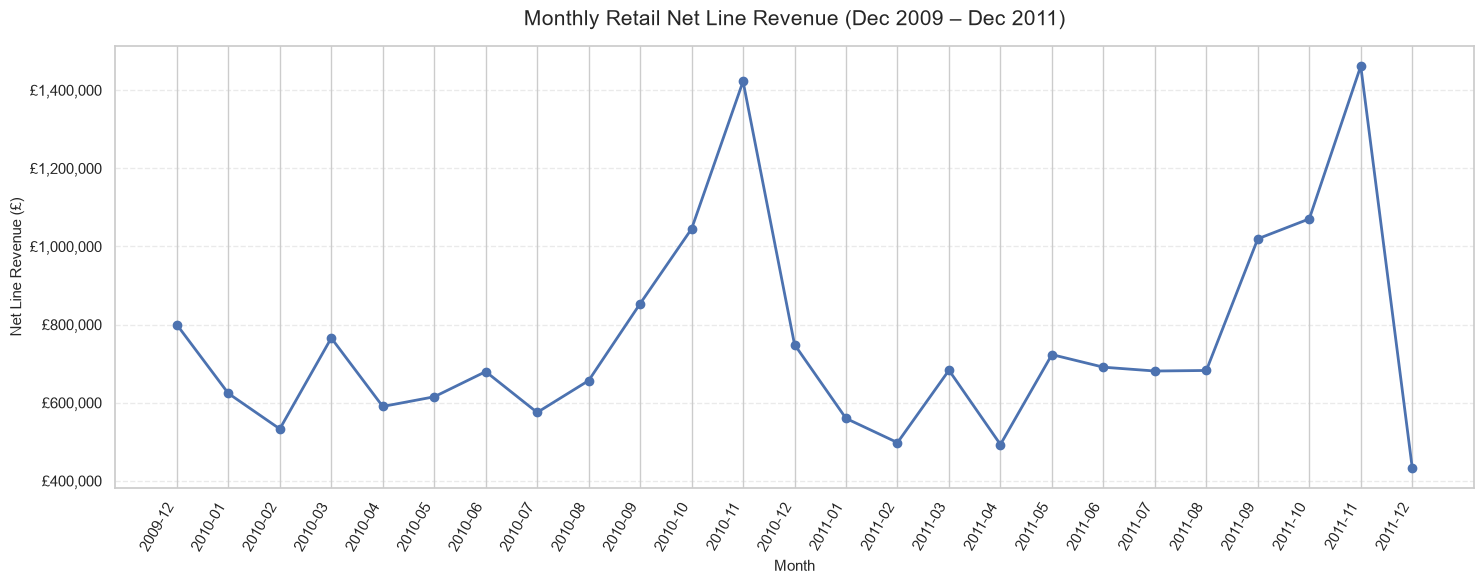

Chart created successfully.
Note: December 2011 is incomplete; data ends on 9 December 2011.


In [46]:
# STEP 4.3: VISUALISE MONTHLY REVENUE TRENDS

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Ensure chronological order
monthly_revenue = monthly_revenue.sort_values("Year_Month").copy()

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_revenue["Year_Month"],
    monthly_revenue["Total_Revenue"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Retail Net Line Revenue (Dec 2009 – Dec 2011)",
    fontsize=15,
    pad=15
)
plt.xlabel("Month", fontsize=11)
plt.ylabel("Net Line Revenue (£)", fontsize=11)

plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("£{x:,.0f}")
)

plt.xticks(
    range(len(monthly_revenue)),
    monthly_revenue["Year_Month"],
    rotation=60,
    ha="right"
)

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Chart created successfully.")
print("Note: December 2011 is incomplete; data ends on 9 December 2011.")

In [47]:
# STEP 4.4: MONTHLY TRANSACTION VOLUME AND AVERAGE REVENUE PER INVOICE

monthly_performance = (
    df_clean.groupby("Year_Month")
    .agg(
        Transaction_Lines=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique"),
        Net_Line_Revenue=("Revenue", "sum")
    )
    .reset_index()
    .sort_values("Year_Month")
)

monthly_performance["Revenue_Per_Invoice"] = (
    monthly_performance["Net_Line_Revenue"]
    / monthly_performance["Unique_Invoices"]
)

print("=" * 85)
print("MONTHLY TRANSACTION VOLUME AND REVENUE PER INVOICE")
print("=" * 85)

print(
    monthly_performance[
        [
            "Year_Month",
            "Transaction_Lines",
            "Unique_Invoices",
            "Net_Line_Revenue",
            "Revenue_Per_Invoice"
        ]
    ].round(2).to_string(index=False)
)

print("\n" + "-" * 85)

highest_volume = monthly_performance.loc[
    monthly_performance["Unique_Invoices"].idxmax()
]

highest_revenue_per_invoice = monthly_performance.loc[
    monthly_performance["Revenue_Per_Invoice"].idxmax()
]

print(
    f"Highest invoice volume: {highest_volume['Year_Month']} "
    f"({highest_volume['Unique_Invoices']:,} invoices)"
)

print(
    f"Highest net revenue per invoice: "
    f"{highest_revenue_per_invoice['Year_Month']} "
    f"(£{highest_revenue_per_invoice['Revenue_Per_Invoice']:,.2f})"
)

MONTHLY TRANSACTION VOLUME AND REVENUE PER INVOICE
Year_Month  Transaction_Lines  Unique_Invoices  Net_Line_Revenue  Revenue_Per_Invoice
   2009-12              45228             2330         799847.11               343.28
   2010-01              31555             1633         624032.89               382.14
   2010-02              29388             1969         533091.43               270.74
   2010-03              41511             2367         765848.76               323.55
   2010-04              34057             1892         590580.43               312.15
   2010-05              35323             2418         615322.83               254.48
   2010-06              39983             2216         679786.61               306.76
   2010-07              33383             2017         575236.36               285.19
   2010-08              33306             1877         656776.34               349.91
   2010-09              42091             2375         853650.43               359.43
   

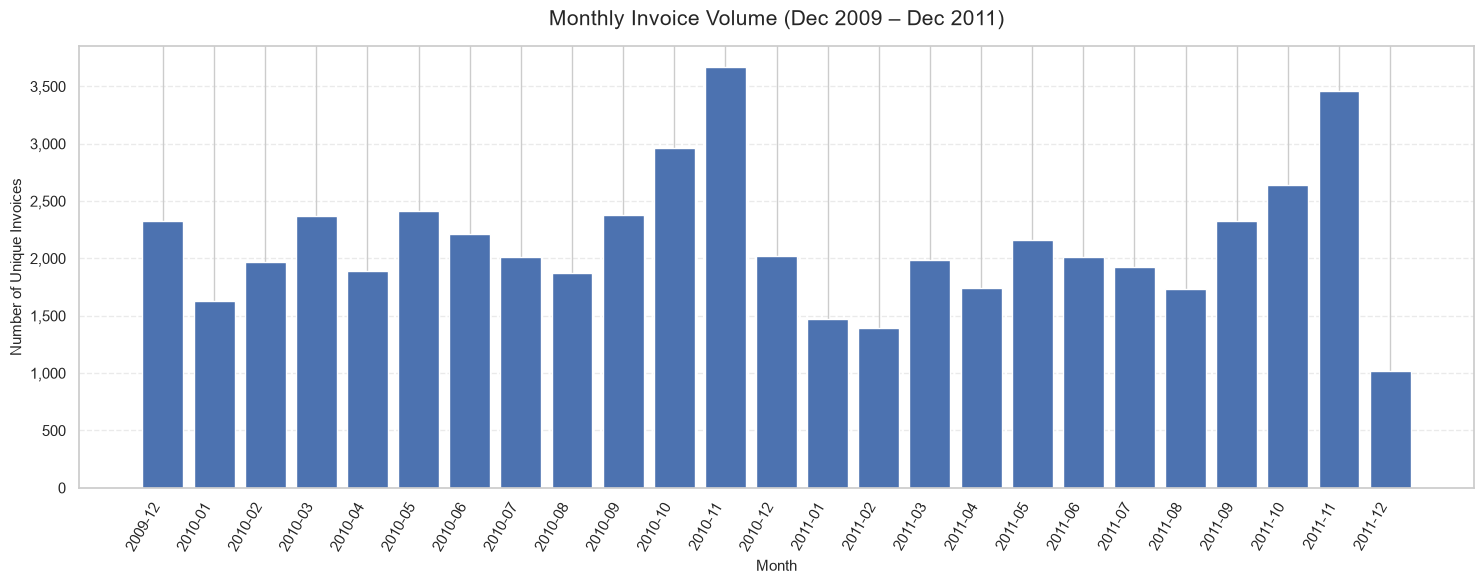

Monthly invoice volume chart created successfully.
Note: December 2011 is incomplete; data ends on 9 December 2011.


In [48]:
# STEP 4.5: MONTHLY INVOICE VOLUME CHART

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

monthly_performance = monthly_performance.sort_values("Year_Month")

plt.figure(figsize=(15, 6))

plt.bar(
    monthly_performance["Year_Month"],
    monthly_performance["Unique_Invoices"]
)

plt.title(
    "Monthly Invoice Volume (Dec 2009 – Dec 2011)",
    fontsize=15,
    pad=15
)
plt.xlabel("Month", fontsize=11)
plt.ylabel("Number of Unique Invoices", fontsize=11)

plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

plt.xticks(
    range(len(monthly_performance)),
    monthly_performance["Year_Month"],
    rotation=60,
    ha="right"
)

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Monthly invoice volume chart created successfully.")
print("Note: December 2011 is incomplete; data ends on 9 December 2011.")

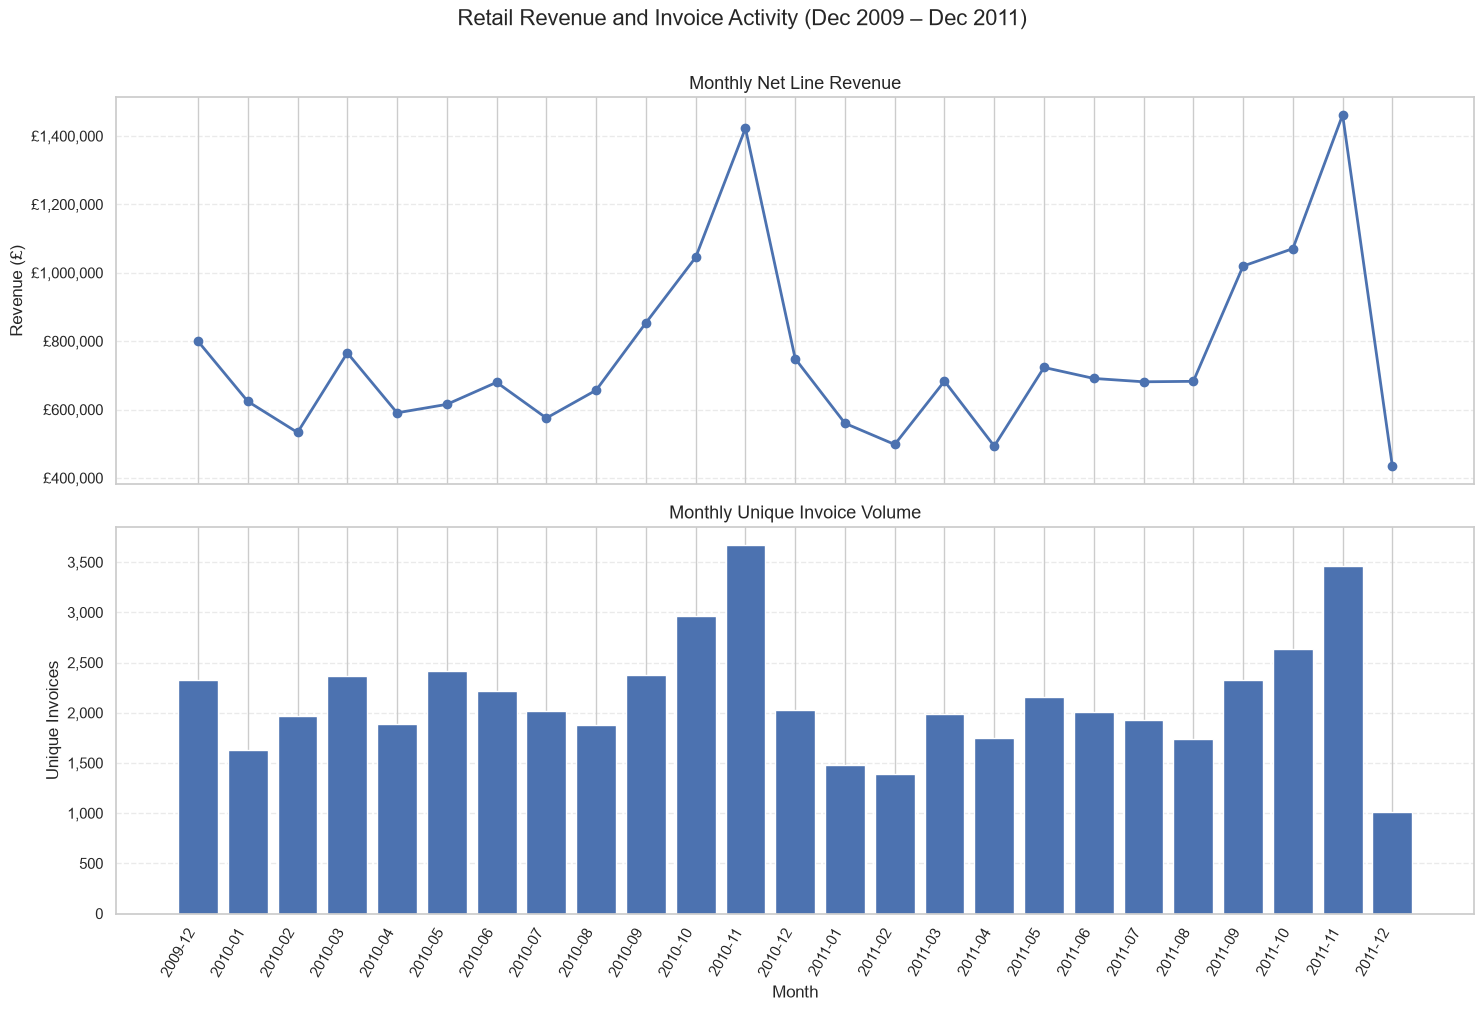

Correlation between monthly net line revenue and invoice volume: 0.918
Note: Correlation describes association, not causation.
December 2011 is incomplete; data ends on 9 December 2011.


In [49]:
# STEP 4.6: COMPARE MONTHLY REVENUE AND INVOICE VOLUME

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

monthly_performance = monthly_performance.sort_values("Year_Month")

fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

# Chart 1: Net line revenue
axes[0].plot(
    monthly_performance["Year_Month"],
    monthly_performance["Net_Line_Revenue"],
    marker="o",
    linewidth=2
)
axes[0].set_title("Monthly Net Line Revenue", fontsize=13)
axes[0].set_ylabel("Revenue (£)")
axes[0].yaxis.set_major_formatter(
    mtick.StrMethodFormatter("£{x:,.0f}")
)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

# Chart 2: Unique invoices
axes[1].bar(
    monthly_performance["Year_Month"],
    monthly_performance["Unique_Invoices"]
)
axes[1].set_title("Monthly Unique Invoice Volume", fontsize=13)
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Unique Invoices")
axes[1].yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.xticks(
    range(len(monthly_performance)),
    monthly_performance["Year_Month"],
    rotation=60,
    ha="right"
)

fig.suptitle(
    "Retail Revenue and Invoice Activity (Dec 2009 – Dec 2011)",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

# Calculate the correlation as a descriptive measure
correlation = monthly_performance[
    ["Net_Line_Revenue", "Unique_Invoices"]
].corr().iloc[0, 1]

print(f"Correlation between monthly net line revenue and invoice volume: {correlation:.3f}")
print("Note: Correlation describes association, not causation.")
print("December 2011 is incomplete; data ends on 9 December 2011.")

## Product Performance Analysis

In [50]:
# STEP 5.1: TOP 10 PRODUCTS BY NET LINE REVENUE

product_performance = (
    df_clean
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Net_Line_Revenue=("Revenue", "sum"),
        Transaction_Lines=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique")
    )
    .reset_index()
)

# Rank products by net line revenue
top_10_products = (
    product_performance
    .sort_values("Net_Line_Revenue", ascending=False)
    .head(10)
    .copy()
)

print("=" * 100)
print("TOP 10 PRODUCTS BY NET LINE REVENUE")
print("=" * 100)

print(
    top_10_products[
        [
            "StockCode",
            "Description",
            "Total_Quantity",
            "Net_Line_Revenue",
            "Transaction_Lines",
            "Unique_Invoices"
        ]
    ].round(2).to_string(index=False)
)

print("\nTotal distinct StockCode–Description combinations:",
      len(product_performance))


TOP 10 PRODUCTS BY NET LINE REVENUE
StockCode                         Description  Total_Quantity  Net_Line_Revenue  Transaction_Lines  Unique_Invoices
    22423            REGENCY CAKESTAND 3 TIER           25084         314513.47               4316             4261
      DOT                      DOTCOM POSTAGE            1417         309844.10               1423             1423
   85123A  WHITE HANGING HEART T-LIGHT HOLDER           90630         248500.30               5699             5495
    47566                       PARTY BUNTING           27948         147157.43               2741             2699
   85099B             JUMBO BAG RED RETROSPOT           76257         144129.70               3375             3320
    84879       ASSORTED COLOUR BIRD ORNAMENT           79790         128907.01               2894             2827
    22086      PAPER CHAIN KIT 50'S CHRISTMAS           34536         116422.49               2109             2034
     POST                           

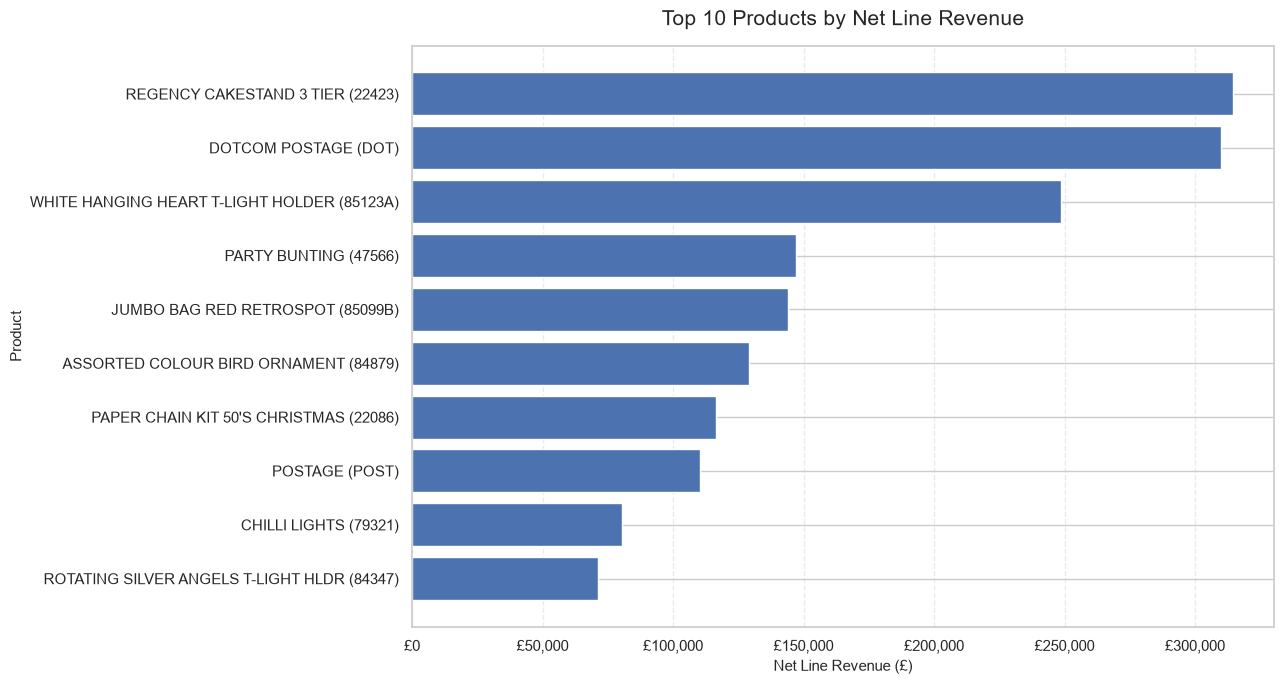

Top 10 product revenue chart created successfully.
Note: Postage and other service-related entries are included in this ranking.


In [51]:
# STEP 5.2: TOP 10 PRODUCTS BY NET LINE REVENUE — BAR CHART

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Prepare products for plotting
plot_data = top_10_products.sort_values(
    "Net_Line_Revenue",
    ascending=True
).copy()

# Create readable product labels
plot_data["Product_Label"] = (
    plot_data["Description"]
    .fillna("Unknown description")
    + " ("
    + plot_data["StockCode"].astype(str)
    + ")"
)

plt.figure(figsize=(13, 7))

plt.barh(
    plot_data["Product_Label"],
    plot_data["Net_Line_Revenue"]
)

plt.title(
    "Top 10 Products by Net Line Revenue",
    fontsize=15,
    pad=15
)
plt.xlabel("Net Line Revenue (£)", fontsize=11)
plt.ylabel("Product", fontsize=11)

plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter("£{x:,.0f}")
)

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Top 10 product revenue chart created successfully.")
print("Note: Postage and other service-related entries are included in this ranking.")

In [52]:
# STEP 5.3: TOP 10 PRODUCTS BY TOTAL QUANTITY

top_10_quantity = (
    product_performance
    .sort_values("Total_Quantity", ascending=False)
    .head(10)
    .copy()
)

print("=" * 100)
print("TOP 10 PRODUCTS BY TOTAL QUANTITY")
print("=" * 100)

print(
    top_10_quantity[
        [
            "StockCode",
            "Description",
            "Total_Quantity",
            "Net_Line_Revenue",
            "Transaction_Lines",
            "Unique_Invoices"
        ]
    ].round(2).to_string(index=False)
)


TOP 10 PRODUCTS BY TOTAL QUANTITY
StockCode                        Description  Total_Quantity  Net_Line_Revenue  Transaction_Lines  Unique_Invoices
    84077  WORLD WAR 2 GLIDERS ASSTD DESIGNS          104786          24145.85               1039             1032
   85123A WHITE HANGING HEART T-LIGHT HOLDER           90630         248500.30               5699             5495
    84879      ASSORTED COLOUR BIRD ORNAMENT           79790         128907.01               2894             2827
   85099B            JUMBO BAG RED RETROSPOT           76257         144129.70               3375             3320
    17003                 BROCADE RING PURSE           69675          14561.08                470              463
    21977 PACK OF 60 PINK PAISLEY CAKE CASES           56011          28041.78               2061             2004
    84991        60 TEATIME FAIRY CAKE CASES           53856          26935.56               2233             2141
    22197               SMALL POPCORN HOLDER  

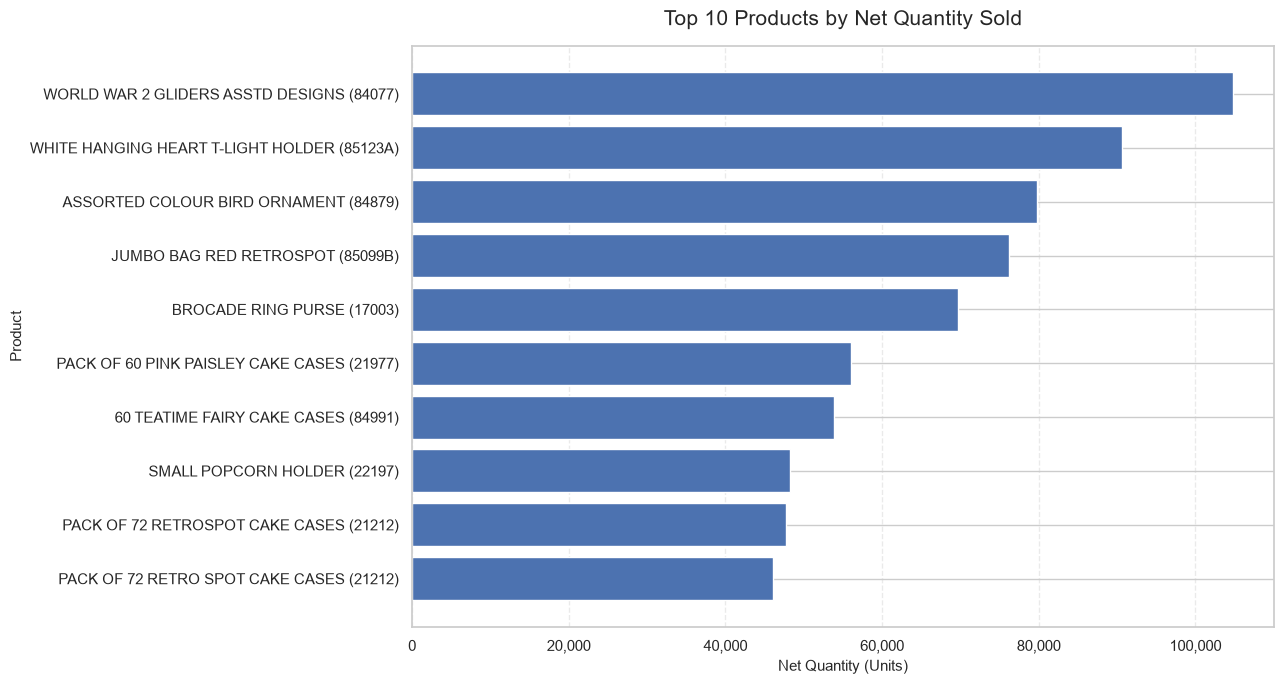

Top 10 products by quantity chart created successfully.
Note: Quantities include returns and other negative-quantity transactions.


In [53]:
# STEP 5.4: TOP 10 PRODUCTS BY QUANTITY — BAR CHART

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plot_quantity = top_10_quantity.sort_values(
    "Total_Quantity",
    ascending=True
).copy()

plot_quantity["Product_Label"] = (
    plot_quantity["Description"].fillna("Unknown description")
    + " ("
    + plot_quantity["StockCode"].astype(str)
    + ")"
)

plt.figure(figsize=(13, 7))

plt.barh(
    plot_quantity["Product_Label"],
    plot_quantity["Total_Quantity"]
)

plt.title(
    "Top 10 Products by Net Quantity Sold",
    fontsize=15,
    pad=15
)
plt.xlabel("Net Quantity (Units)", fontsize=11)
plt.ylabel("Product", fontsize=11)

plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Top 10 products by quantity chart created successfully.")
print("Note: Quantities include returns and other negative-quantity transactions.")

In [54]:
# STEP 5.5: COMPARE REVENUE LEADERS AND QUANTITY LEADERS

revenue_leaders = set(top_10_products["StockCode"])
quantity_leaders = set(top_10_quantity["StockCode"])

common_products = revenue_leaders.intersection(quantity_leaders)

comparison = product_performance[
    product_performance["StockCode"].isin(common_products)
].copy()

comparison = comparison.sort_values(
    "Net_Line_Revenue",
    ascending=False
)

print("=" * 100)
print("PRODUCTS APPEARING IN BOTH TOP-10 RANKINGS")
print("=" * 100)

if comparison.empty:
    print("No products appear in both top-10 rankings.")
else:
    print(
        comparison[
            [
                "StockCode",
                "Description",
                "Total_Quantity",
                "Net_Line_Revenue",
                "Transaction_Lines",
                "Unique_Invoices"
            ]
        ].round(2).to_string(index=False)
    )

print(f"\nProducts appearing in both rankings: {len(comparison)}")

PRODUCTS APPEARING IN BOTH TOP-10 RANKINGS
StockCode                        Description  Total_Quantity  Net_Line_Revenue  Transaction_Lines  Unique_Invoices
   85123A WHITE HANGING HEART T-LIGHT HOLDER           90630         248500.30               5699             5495
   85099B            JUMBO BAG RED RETROSPOT           76257         144129.70               3375             3320
    84879      ASSORTED COLOUR BIRD ORNAMENT           79790         128907.01               2894             2827
   85099B         JUMBO BAG RED WHITE SPOTTY           14066          25054.27                552              541
   85099B            RED RETROSPOT JUMBO BAG            5402           9535.24                219              216
   85123A CREAM HANGING HEART T-LIGHT HOLDER              61            178.51                  9                9
    84879                            damaged            -160              0.00                  1                1
    84879                   Dotcom mu

In [55]:
# STEP 5.6: INVESTIGATE UNUSUAL DESCRIPTIONS IN TOP-PERFORMING STOCK CODES

import pandas as pd

focus_stock_codes = ["85123A", "85099B", "84879"]

focus_records = df_clean[
    df_clean["StockCode"].astype(str).isin(focus_stock_codes)
].copy()

# Summarise each StockCode–Description combination
description_audit = (
    focus_records
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Transaction_Lines=("Invoice", "size"),
        Total_Quantity=("Quantity", "sum"),
        Net_Line_Revenue=("Revenue", "sum"),
        Unique_Invoices=("Invoice", "nunique")
    )
    .reset_index()
)

# Flag descriptions that may indicate adjustments or exceptions
review_keywords = (
    r"damag|missing|wrong|mixed|multiples|carton|"
    r"adjust|lost|broken|incorrect|faulty|?" 
)

# Avoid using a bare question mark as a regex pattern
review_keywords = (
    r"damag|missing|wrong|mixed|multiples|carton|"
    r"adjust|lost|broken|incorrect|faulty"
)

description_text = (
    description_audit["Description"]
    .fillna("")
    .astype(str)
)

description_audit["Review_Flag"] = description_text.str.contains(
    review_keywords,
    case=False,
    regex=True
)

review_results = description_audit[
    description_audit["Review_Flag"]
].sort_values(
    ["StockCode", "Transaction_Lines"],
    ascending=[True, False]
)

print("=" * 100)
print("UNUSUAL DESCRIPTIONS ASSOCIATED WITH TOP-PERFORMING STOCK CODES")
print("=" * 100)

if review_results.empty:
    print("No descriptions matched the selected review keywords.")
else:
    print(
        review_results[
            [
                "StockCode",
                "Description",
                "Transaction_Lines",
                "Total_Quantity",
                "Net_Line_Revenue",
                "Unique_Invoices"
            ]
        ].to_string(index=False)
    )

print("\nOriginal working dataset shape:", df_clean.shape)
print("No rows have been removed or modified by this investigation.")

UNUSUAL DESCRIPTIONS ASSOCIATED WITH TOP-PERFORMING STOCK CODES
StockCode                 Description  Transaction_Lines  Total_Quantity  Net_Line_Revenue  Unique_Invoices
    84879            Dotcom multiples                  1            -441               0.0                1
    84879                     damaged                  1            -160               0.0                1
   85099B                     missing                  1           -1400               0.0                1
   85123A                 21733 mixed                  1            -192               0.0                1
   85123A wrongly marked carton 22804                  1            -256               0.0                1

Original working dataset shape: (1044848, 15)
No rows have been removed or modified by this investigation.


In [56]:
# STEP 5.7: CREATE A PROVISIONAL MERCHANDISE-ONLY VIEW

import pandas as pd

# Start from the existing product-level summary
merchandise_view = product_performance.copy()

# Identify descriptions that are clearly service-related or flagged for review
service_pattern = r"\b(postage|carriage|dotcom postage)\b"

review_pattern = (
    r"damag|missing|wrong|mixed|multiples|carton|"
    r"adjust|lost|broken|incorrect|faulty"
)

description_text = (
    merchandise_view["Description"]
    .fillna("")
    .astype(str)
)

is_service = description_text.str.contains(
    service_pattern,
    case=False,
    regex=True
)

is_review = description_text.str.contains(
    review_pattern,
    case=False,
    regex=True
)

# Keep a separate view; do not change the source DataFrame
merchandise_view = merchandise_view.loc[
    ~(is_service | is_review)
].copy()

# Rank the provisional merchandise view
top_merchandise_revenue = (
    merchandise_view
    .sort_values("Net_Line_Revenue", ascending=False)
    .head(10)
)

top_merchandise_quantity = (
    merchandise_view
    .sort_values("Total_Quantity", ascending=False)
    .head(10)
)

print("=" * 100)
print("TOP 10 PROVISIONAL MERCHANDISE ITEMS BY NET LINE REVENUE")
print("=" * 100)

print(
    top_merchandise_revenue[
        [
            "StockCode",
            "Description",
            "Total_Quantity",
            "Net_Line_Revenue",
            "Transaction_Lines",
            "Unique_Invoices"
        ]
    ].round(2).to_string(index=False)
)

print("\n" + "=" * 100)
print("TOP 10 PROVISIONAL MERCHANDISE ITEMS BY NET QUANTITY")
print("=" * 100)

print(
    top_merchandise_quantity[
        [
            "StockCode",
            "Description",
            "Total_Quantity",
            "Net_Line_Revenue",
            "Transaction_Lines",
            "Unique_Invoices"
        ]
    ].round(2).to_string(index=False)
)

print("\nOriginal working dataset shape:", df_clean.shape)
print("Provisional merchandise combinations:", len(merchandise_view))
print("No source rows have been deleted.")

TOP 10 PROVISIONAL MERCHANDISE ITEMS BY NET LINE REVENUE
StockCode                         Description  Total_Quantity  Net_Line_Revenue  Transaction_Lines  Unique_Invoices
    22423            REGENCY CAKESTAND 3 TIER           25084         314513.47               4316             4261
   85123A  WHITE HANGING HEART T-LIGHT HOLDER           90630         248500.30               5699             5495
    47566                       PARTY BUNTING           27948         147157.43               2741             2699
   85099B             JUMBO BAG RED RETROSPOT           76257         144129.70               3375             3320
    84879       ASSORTED COLOUR BIRD ORNAMENT           79790         128907.01               2894             2827
    22086      PAPER CHAIN KIT 50'S CHRISTMAS           34536         116422.49               2109             2034
    79321                       CHILLI LIGHTS           15780          80237.48               1173             1161
    84347 ROTAT

C:\Users\ADITYA\AppData\Local\Temp\ipykernel_23300\1825787099.py:22: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  is_service = description_text.str.contains(


In [57]:
# STEP 5.8: CROSS-RANK PROVISIONAL MERCHANDISE

# Rank products separately on each measure
ranked_products = merchandise_view.copy()

ranked_products["Revenue_Rank"] = (
    ranked_products["Net_Line_Revenue"]
    .rank(method="min", ascending=False)
    .astype(int)
)

ranked_products["Quantity_Rank"] = (
    ranked_products["Total_Quantity"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Combined rank: lower is better
ranked_products["Combined_Rank_Score"] = (
    ranked_products["Revenue_Rank"]
    + ranked_products["Quantity_Rank"]
)

# Products ranked in the top 20 for both measures
strong_both = ranked_products[
    (ranked_products["Revenue_Rank"] <= 20)
    & (ranked_products["Quantity_Rank"] <= 20)
].sort_values("Combined_Rank_Score")

print("=" * 100)
print("PRODUCTS RANKED IN THE TOP 20 FOR BOTH REVENUE AND QUANTITY")
print("=" * 100)

if strong_both.empty:
    print("No products meet both top-20 criteria.")
else:
    print(
        strong_both[
            [
                "StockCode",
                "Description",
                "Net_Line_Revenue",
                "Total_Quantity",
                "Revenue_Rank",
                "Quantity_Rank",
                "Combined_Rank_Score"
            ]
        ].to_string(index=False)
    )

print("\nProducts meeting both criteria:", len(strong_both))
print("Original dataset unchanged:", df_clean.shape == (1044848, 15))

PRODUCTS RANKED IN THE TOP 20 FOR BOTH REVENUE AND QUANTITY
StockCode                        Description  Net_Line_Revenue  Total_Quantity  Revenue_Rank  Quantity_Rank  Combined_Rank_Score
   85123A WHITE HANGING HEART T-LIGHT HOLDER         248500.30           90630             2              2                    4
    84879      ASSORTED COLOUR BIRD ORNAMENT         128907.01           79790             5              3                    8
   85099B            JUMBO BAG RED RETROSPOT         144129.70           76257             4              4                    8
   85099F               JUMBO BAG STRAWBERRY          67579.61           36632             9             18                   27

Products meeting both criteria: 4
Original dataset unchanged: True


In [58]:
# STEP 5.9: TOP 10 MERCHANDISE REVENUE CONTRIBUTION

# Sum the net line revenue of all products in the provisional view
total_merchandise_revenue = merchandise_view["Net_Line_Revenue"].sum()

# Sum the revenue of the top 10 merchandise items
top10_merchandise_revenue = top_merchandise_revenue["Net_Line_Revenue"].sum()

if total_merchandise_revenue != 0:
    top10_revenue_share = (
        top10_merchandise_revenue / total_merchandise_revenue
    ) * 100
else:
    top10_revenue_share = float("nan")

print("=" * 85)
print("TOP 10 MERCHANDISE REVENUE CONTRIBUTION")
print("=" * 85)

print(f"Provisional merchandise combinations: {len(merchandise_view):,}")
print(f"Total net line revenue in provisional view: £{total_merchandise_revenue:,.2f}")
print(f"Top 10 merchandise net line revenue: £{top10_merchandise_revenue:,.2f}")
print(f"Top 10 share of provisional merchandise revenue: {top10_revenue_share:.2f}%")

print("\nImportant:")
print("- Revenue includes negative and zero-value transactions.")
print("- Merchandise classification is provisional and description-based.")
print("- This is revenue concentration, not profit concentration.")

TOP 10 MERCHANDISE REVENUE CONTRIBUTION
Provisional merchandise combinations: 8,638
Total net line revenue in provisional view: £18,612,793.12
Top 10 merchandise net line revenue: £1,385,235.23
Top 10 share of provisional merchandise revenue: 7.44%

Important:
- Revenue includes negative and zero-value transactions.
- Merchandise classification is provisional and description-based.
- This is revenue concentration, not profit concentration.


## Customer Intelligence

In [59]:
# STEP 6.1: CUSTOMER-LEVEL PERFORMANCE SUMMARY

# Use records with a known Customer ID for customer-level analysis.
identified_customer_data = df_clean.loc[
    df_clean["Customer ID"].notna()
].copy()

# Convert Customer ID to a consistent integer representation in this analysis table.
identified_customer_data["Customer ID"] = (
    identified_customer_data["Customer ID"].astype("int64")
)

customer_performance = (
    identified_customer_data
    .groupby("Customer ID")
    .agg(
        Transaction_Lines=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Net_Line_Revenue=("Revenue", "sum"),
        First_Purchase=("InvoiceDate", "min"),
        Last_Purchase=("InvoiceDate", "max"),
        Countries=("Country", "nunique")
    )
    .reset_index()
)

customer_performance = customer_performance.sort_values(
    "Net_Line_Revenue",
    ascending=False
).reset_index(drop=True)

print("=" * 100)
print("CUSTOMER-LEVEL PERFORMANCE SUMMARY")
print("=" * 100)

print("Identified customer records:", f"{len(identified_customer_data):,}")
print("Unique identified customers:", f"{customer_performance['Customer ID'].nunique():,}")
print("Customers in summary table:", f"{len(customer_performance):,}")

print("\nTop 10 customers by net line revenue:")
print(
    customer_performance.head(10)[
        [
            "Customer ID",
            "Transaction_Lines",
            "Unique_Invoices",
            "Total_Quantity",
            "Net_Line_Revenue",
            "First_Purchase",
            "Last_Purchase"
        ]
    ].round(2).to_string(index=False)
)

print("\nCustomer summary table shape:", customer_performance.shape)

CUSTOMER-LEVEL PERFORMANCE SUMMARY
Identified customer records: 809,561
Unique identified customers: 5,942
Customers in summary table: 5,942

Top 10 customers by net line revenue:
 Customer ID  Transaction_Lines  Unique_Invoices  Total_Quantity  Net_Line_Revenue      First_Purchase       Last_Purchase
       18102               1050              153          180415         570380.61 2009-12-01 09:24:00 2011-12-09 11:50:00
       14646               3890              164          365220         523342.07 2009-12-02 16:52:00 2011-12-08 12:12:00
       14156               4125              202          162364         296249.99 2009-12-01 12:30:00 2011-11-30 10:54:00
       14911              11452              510          141764         265836.95 2009-12-01 11:41:00 2011-12-08 15:54:00
       17450                445               61           80858         231550.55 2010-09-27 16:59:00 2011-12-01 13:29:00
       13694               1552              164          184438         189983.40

C:\Users\ADITYA\AppData\Local\Temp\ipykernel_23300\3704559636.py:53: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2).to_string(index=False)


In [60]:
# Step 6.2: Customer Revenue and Purchase Frequency Analysis

print("=" * 100)
print("CUSTOMER REVENUE AND PURCHASE FREQUENCY ANALYSIS")
print("=" * 100)

# 1. Overall customer-level statistics
print("\n1. CUSTOMER REVENUE STATISTICS")
print("-" * 60)

print(
    customer_performance["Net_Line_Revenue"]
    .describe()
    .round(2)
    .to_string()
)

# 2. Customers with the highest invoice frequency
print("\n\n2. TOP 10 CUSTOMERS BY UNIQUE INVOICES")
print("-" * 60)

top_customers_frequency = (
    customer_performance
    .sort_values("Unique_Invoices", ascending=False)
    .head(10)
)

print(
    top_customers_frequency[
        ["Customer ID", "Unique_Invoices", "Transaction_Lines",
         "Net_Line_Revenue", "Total_Quantity"]
    ]
    .round(2)
    .to_string(index=False)
)

# 3. Customers with the highest net line revenue
print("\n\n3. TOP 10 CUSTOMERS BY NET LINE REVENUE")
print("-" * 60)

top_customers_revenue = customer_performance.head(10)

print(
    top_customers_revenue[
        ["Customer ID", "Unique_Invoices", "Net_Line_Revenue"]
    ]
    .round(2)
    .to_string(index=False)
)

# 4. Revenue concentration among top customers
print("\n\n4. CUSTOMER REVENUE CONCENTRATION")
print("-" * 60)

total_identified_customer_revenue = customer_performance["Net_Line_Revenue"].sum()

for n in [10, 50, 100]:
    top_n_revenue = customer_performance.head(n)["Net_Line_Revenue"].sum()
    share = (
        top_n_revenue / total_identified_customer_revenue * 100
        if total_identified_customer_revenue != 0
        else 0
    )
    print(
        f"Top {n} customers' net line revenue: "
        f"£{top_n_revenue:,.2f} ({share:.2f}% of identified-customer net line revenue)"
    )

print(
    f"\nTotal identified-customer net line revenue: "
    f"£{total_identified_customer_revenue:,.2f}"
)

CUSTOMER REVENUE AND PURCHASE FREQUENCY ANALYSIS

1. CUSTOMER REVENUE STATISTICS
------------------------------------------------------------
count      5942.00
mean       2750.53
std       13679.48
min      -25111.09
25%         322.51
50%         828.68
75%        2150.65
max      570380.61


2. TOP 10 CUSTOMERS BY UNIQUE INVOICES
------------------------------------------------------------
 Customer ID  Unique_Invoices  Transaction_Lines  Net_Line_Revenue  Total_Quantity
       14911              510              11452         265836.95          141764
       12748              365               6936          47976.73           35744
       17841              289              12907          67984.13           36542
       15311              270               4608         111920.03           68949
       14606              259               6587          29500.40           15045
       13089              247               3397         109983.57           58025
       14156           

In [61]:
# Step 6.3: Customer Revenue Segmentation

print("=" * 100)
print("CUSTOMER REVENUE SEGMENTATION")
print("=" * 100)

# Create a separate copy so the original customer summary remains unchanged
customer_segments = customer_performance.copy()

# Rank customers to handle tied revenue values consistently
customer_segments["Revenue_Rank"] = (
    customer_segments["Net_Line_Revenue"]
    .rank(method="first", ascending=True)
)

# Divide customers into three approximately equal-sized groups
customer_segments["Customer_Segment"] = pd.qcut(
    customer_segments["Revenue_Rank"],
    q=3,
    labels=["Low Revenue", "Medium Revenue", "High Revenue"]
)

# Summarise each segment
segment_summary = (
    customer_segments
    .groupby("Customer_Segment", observed=True)
    .agg(
        Customer_Count=("Customer ID", "nunique"),
        Total_Net_Line_Revenue=("Net_Line_Revenue", "sum"),
        Average_Net_Line_Revenue=("Net_Line_Revenue", "mean"),
        Median_Net_Line_Revenue=("Net_Line_Revenue", "median"),
        Average_Unique_Invoices=("Unique_Invoices", "mean"),
        Total_Transaction_Lines=("Transaction_Lines", "sum")
    )
    .reset_index()
)

# Calculate each segment's share of identified-customer net line revenue
identified_revenue = customer_segments["Net_Line_Revenue"].sum()

segment_summary["Revenue_Share_Percent"] = (
    segment_summary["Total_Net_Line_Revenue"]
    / identified_revenue * 100
)

print("\nCUSTOMER SEGMENT SUMMARY")
print("-" * 100)

print(
    segment_summary.round(2).to_string(index=False)
)

print("\nCUSTOMER COUNT VALIDATION")
print("-" * 60)
print("Customers in original summary:", len(customer_performance))
print("Customers assigned to segments:", customer_segments["Customer_Segment"].notna().sum())
print("Missing segment assignments:", customer_segments["Customer_Segment"].isna().sum())

print("\nCUSTOMER SEGMENT DISTRIBUTION")
print("-" * 60)

print(
    customer_segments["Customer_Segment"]
    .value_counts()
    .sort_index()
    .to_string()
)

CUSTOMER REVENUE SEGMENTATION

CUSTOMER SEGMENT SUMMARY
----------------------------------------------------------------------------------------------------
Customer_Segment  Customer_Count  Total_Net_Line_Revenue  Average_Net_Line_Revenue  Median_Net_Line_Revenue  Average_Unique_Invoices  Total_Transaction_Lines  Revenue_Share_Percent
     Low Revenue            1981               345919.42                    174.62                   217.24                     1.66                    41487                   2.12
  Medium Revenue            1980              1729620.97                    873.55                   828.68                     3.96                   138385                  10.58
    High Revenue            1981             14268128.64                   7202.49                  3320.84                    17.03                   629689                  87.30

CUSTOMER COUNT VALIDATION
------------------------------------------------------------
Customers in original summary: 

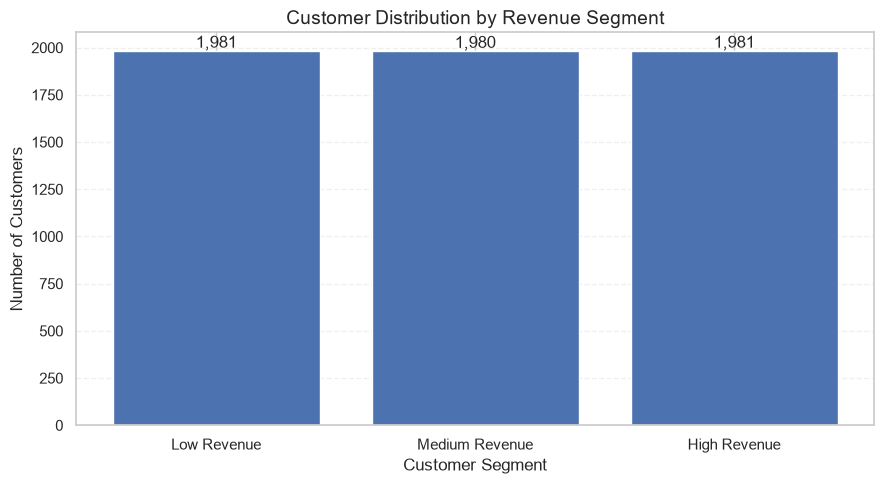

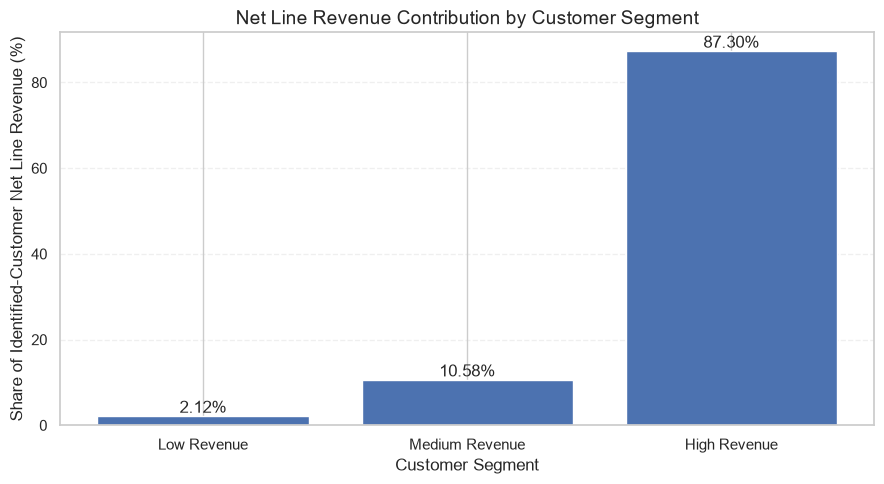

In [62]:
# Step 6.4: Visualise Customer Revenue Segmentation

import matplotlib.pyplot as plt

# Ensure segments appear in the intended order
segment_order = ["Low Revenue", "Medium Revenue", "High Revenue"]

segment_chart_data = (
    segment_summary
    .set_index("Customer_Segment")
    .reindex(segment_order)
)

# Chart 1: Customer count by segment
plt.figure(figsize=(9, 5))

bars = plt.bar(
    segment_chart_data.index.astype(str),
    segment_chart_data["Customer_Count"]
)

plt.title("Customer Distribution by Revenue Segment", fontsize=14)
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.grid(axis="y", linestyle="--", alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# Chart 2: Net line revenue contribution by segment
plt.figure(figsize=(9, 5))

bars = plt.bar(
    segment_chart_data.index.astype(str),
    segment_chart_data["Revenue_Share_Percent"]
)

plt.title("Net Line Revenue Contribution by Customer Segment", fontsize=14)
plt.xlabel("Customer Segment")
plt.ylabel("Share of Identified-Customer Net Line Revenue (%)")
plt.grid(axis="y", linestyle="--", alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [63]:
# Step 6.5: Customer Recency Analysis

print("=" * 100)
print("CUSTOMER RECENCY ANALYSIS")
print("=" * 100)

# Use the latest transaction date in the dataset as the reference date
analysis_date = df_clean["InvoiceDate"].max()

print(f"\nDataset reference date: {analysis_date}")
print(f"Total identified customers: {len(customer_performance):,}")

# Calculate days since each customer's last recorded purchase
customer_recency = customer_performance[
    ["Customer ID", "Last_Purchase", "Unique_Invoices", "Net_Line_Revenue"]
].copy()

customer_recency["Recency_Days"] = (
    analysis_date.normalize()
    - customer_recency["Last_Purchase"].dt.normalize()
).dt.days

# Summarise recency distribution
print("\n1. CUSTOMER RECENCY STATISTICS")
print("-" * 60)

print(
    customer_recency["Recency_Days"]
    .describe()
    .round(2)
    .to_string()
)

# Create descriptive recency groups
customer_recency["Recency_Group"] = pd.cut(
    customer_recency["Recency_Days"],
    bins=[-1, 30, 90, 180, 365, float("inf")],
    labels=[
        "0–30 days",
        "31–90 days",
        "91–180 days",
        "181–365 days",
        "Over 365 days"
    ]
)

# Summarise the customer distribution by recency group
recency_summary = (
    customer_recency
    .groupby("Recency_Group", observed=False)
    .agg(
        Customer_Count=("Customer ID", "nunique"),
        Average_Recency_Days=("Recency_Days", "mean"),
        Average_Unique_Invoices=("Unique_Invoices", "mean"),
        Net_Line_Revenue=("Net_Line_Revenue", "sum")
    )
    .reset_index()
)

recency_summary["Customer_Share_Percent"] = (
    recency_summary["Customer_Count"]
    / len(customer_recency) * 100
)

print("\n\n2. CUSTOMER DISTRIBUTION BY RECENCY GROUP")
print("-" * 100)

print(recency_summary.round(2).to_string(index=False))

# Inspect the 10 customers with the longest recency
print("\n\n3. TEN CUSTOMERS WITH THE LONGEST RECENCY")
print("-" * 100)

print(
    customer_recency
    .sort_values("Recency_Days", ascending=False)
    .head(10)[
        [
            "Customer ID",
            "Last_Purchase",
            "Recency_Days",
            "Unique_Invoices",
            "Net_Line_Revenue"
        ]
    ]
    .to_string(index=False)
)

# Validate recency calculations
print("\n\n4. VALIDATION")
print("-" * 60)
print("Missing recency values:", customer_recency["Recency_Days"].isna().sum())
print("Negative recency values:", (customer_recency["Recency_Days"] < 0).sum())
print("Customers analysed:", customer_recency["Customer ID"].nunique())

CUSTOMER RECENCY ANALYSIS

Dataset reference date: 2011-12-09 12:50:00
Total identified customers: 5,942

1. CUSTOMER RECENCY STATISTICS
------------------------------------------------------------
count    5942.00
mean      202.46
std       211.88
min         0.00
25%        24.00
50%        95.50
75%       381.00
max       738.00


2. CUSTOMER DISTRIBUTION BY RECENCY GROUP
----------------------------------------------------------------------------------------------------
Recency_Group  Customer_Count  Average_Recency_Days  Average_Unique_Invoices  Net_Line_Revenue  Customer_Share_Percent
    0–30 days            1714                 12.69                    15.05       10709459.48                   28.85
   31–90 days            1204                 55.82                     6.82        2706020.26                   20.26
  91–180 days             592                132.78                     5.90        1019296.81                    9.96
 181–365 days             797                

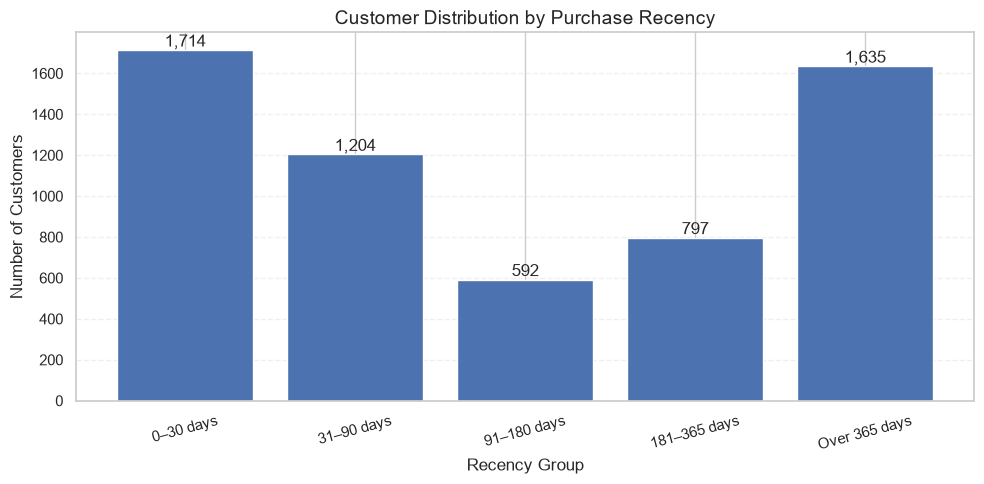

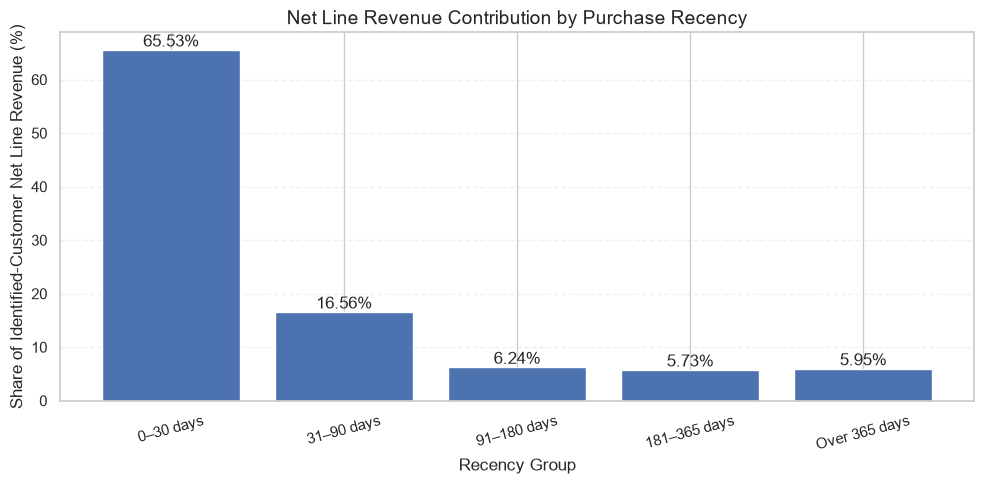

In [64]:
# Step 6.6: Visualise Customer Recency

import matplotlib.pyplot as plt

recency_chart_data = recency_summary.copy()

# Chart 1: Customer count by recency group
plt.figure(figsize=(10, 5))

bars = plt.bar(
    recency_chart_data["Recency_Group"].astype(str),
    recency_chart_data["Customer_Count"]
)

plt.title("Customer Distribution by Purchase Recency", fontsize=14)
plt.xlabel("Recency Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# Chart 2: Net line revenue by recency group
# Calculate each group's share of identified-customer net line revenue
total_customer_revenue = customer_recency["Net_Line_Revenue"].sum()

recency_chart_data["Revenue_Share_Percent"] = (
    recency_chart_data["Net_Line_Revenue"]
    / total_customer_revenue * 100
)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    recency_chart_data["Recency_Group"].astype(str),
    recency_chart_data["Revenue_Share_Percent"]
)

plt.title("Net Line Revenue Contribution by Purchase Recency", fontsize=14)
plt.xlabel("Recency Group")
plt.ylabel("Share of Identified-Customer Net Line Revenue (%)")
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## RFM Customer Analysis

In [65]:
# Step 7.1: Prepare the RFM Dataset

print("=" * 100)
print("RFM CUSTOMER ANALYSIS — DATA PREPARATION")
print("=" * 100)

# Use the latest transaction date as the reference date
analysis_date = df_clean["InvoiceDate"].max().normalize()

# Build the RFM table using the existing customer-level summary
rfm = customer_performance[
    [
        "Customer ID",
        "Last_Purchase",
        "Unique_Invoices",
        "Net_Line_Revenue"
    ]
].copy()

# Calculate Recency, Frequency, and Monetary Value
rfm["Recency"] = (
    analysis_date - rfm["Last_Purchase"].dt.normalize()
).dt.days

rfm["Frequency"] = rfm["Unique_Invoices"]

rfm["Monetary"] = rfm["Net_Line_Revenue"]

# Keep only the three RFM metrics and customer identifier
rfm = rfm[
    ["Customer ID", "Recency", "Frequency", "Monetary"]
].copy()

print(f"\nReference date: {analysis_date.date()}")
print(f"Number of identified customers: {len(rfm):,}")

print("\nRFM DATA SAMPLE")
print("-" * 80)
print(rfm.head(10).to_string(index=False))

print("\nRFM METRIC SUMMARY")
print("-" * 80)
print(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2).to_string())

print("\nDATA VALIDATION")
print("-" * 80)
print("Missing values by column:")
print(rfm.isna().sum().to_string())

print("\nDuplicate customer IDs:", rfm["Customer ID"].duplicated().sum())
print("Negative recency values:", (rfm["Recency"] < 0).sum())
print("Customers with negative monetary value:", (rfm["Monetary"] < 0).sum())
print("Customers with zero monetary value:", (rfm["Monetary"] == 0).sum())

RFM CUSTOMER ANALYSIS — DATA PREPARATION

Reference date: 2011-12-09
Number of identified customers: 5,942

RFM DATA SAMPLE
--------------------------------------------------------------------------------
 Customer ID  Recency  Frequency  Monetary
       18102        0        153 570380.61
       14646        1        164 523342.07
       14156        9        202 296249.99
       14911        1        510 265836.95
       17450        8         61 231550.55
       13694        3        164 189983.40
       17511        2         85 168491.62
       12415       24         33 143269.29
       16684        4         65 141502.25
       15061        3        138 124961.98

RFM METRIC SUMMARY
--------------------------------------------------------------------------------
       Recency  Frequency   Monetary
count  5942.00    5942.00    5942.00
mean    202.46       7.55    2750.53
std     211.88      15.97   13679.48
min       0.00       1.00  -25111.09
25%      24.00       2.00     322.51

In [66]:
# Step 7.2: Inspect RFM Monetary Values

print("=" * 100)
print("RFM MONETARY VALUE INSPECTION")
print("=" * 100)

# Classify customers by net line revenue without modifying the original RFM data
rfm["Monetary_Category"] = pd.cut(
    rfm["Monetary"],
    bins=[-float("inf"), 0, float("inf")],
    labels=["Negative", "Positive"],
    right=False
)

# Separate negative, zero, and positive monetary values
negative_count = (rfm["Monetary"] < 0).sum()
zero_count = (rfm["Monetary"] == 0).sum()
positive_count = (rfm["Monetary"] > 0).sum()

print("\n1. CUSTOMER COUNTS BY MONETARY VALUE")
print("-" * 60)
print(f"Negative net line revenue: {negative_count:,}")
print(f"Zero net line revenue:     {zero_count:,}")
print(f"Positive net line revenue: {positive_count:,}")
print(f"Total customers:           {len(rfm):,}")

print("\n2. MONETARY STATISTICS BY CATEGORY")
print("-" * 60)

for category, condition in [
    ("Negative", rfm["Monetary"] < 0),
    ("Zero", rfm["Monetary"] == 0),
    ("Positive", rfm["Monetary"] > 0)
]:
    values = rfm.loc[condition, "Monetary"]

    print(f"\n{category} monetary values")
    if len(values) > 0:
        print(f"Customer count: {len(values):,}")
        print(f"Minimum: £{values.min():,.2f}")
        print(f"Median:  £{values.median():,.2f}")
        print(f"Maximum: £{values.max():,.2f}")
        print(f"Total:   £{values.sum():,.2f}")

print("\n3. LOWEST 10 MONETARY VALUES")
print("-" * 60)

print(
    rfm.nsmallest(10, "Monetary")[
        ["Customer ID", "Recency", "Frequency", "Monetary"]
    ].to_string(index=False)
)

print("\n4. HIGHEST 10 MONETARY VALUES")
print("-" * 60)

print(
    rfm.nlargest(10, "Monetary")[
        ["Customer ID", "Recency", "Frequency", "Monetary"]
    ].to_string(index=False)
)

# Remove the temporary inspection column so the RFM dataframe remains clean
rfm.drop(columns=["Monetary_Category"], inplace=True)

print("\nInspection complete. The original RFM metrics remain unchanged.")

RFM MONETARY VALUE INSPECTION

1. CUSTOMER COUNTS BY MONETARY VALUE
------------------------------------------------------------
Negative net line revenue: 84
Zero net line revenue:     15
Positive net line revenue: 5,843
Total customers:           5,942

2. MONETARY STATISTICS BY CATEGORY
------------------------------------------------------------

Negative monetary values
Customer count: 84
Minimum: £-25,111.09
Median:  £-128.94
Maximum: £-0.00
Total:   £-92,649.69

Zero monetary values
Customer count: 15
Minimum: £0.00
Median:  £0.00
Maximum: £0.00
Total:   £0.00

Positive monetary values
Customer count: 5,843
Minimum: £0.00
Median:  £850.18
Maximum: £570,380.61
Total:   £16,436,318.73

3. LOWEST 10 MONETARY VALUES
------------------------------------------------------------
 Customer ID  Recency  Frequency  Monetary
       17399      540          1 -25111.09
       12918      626          3 -10953.50
       15849      596          1  -5876.34
       15760      630          5  -579

In [67]:
# Step 7.3: Assign RFM Scores

print("=" * 100)
print("RFM CUSTOMER SCORING")
print("=" * 100)

# Create a separate scoring dataframe
rfm_scored = rfm.copy()

# Recency: lower number of days is better, so reverse the quintile scores
rfm_scored["R_Score"] = (
    6 - pd.qcut(
        rfm_scored["Recency"].rank(method="first"),
        q=5,
        labels=False
    )
)

# Frequency: more unique invoices is better
rfm_scored["F_Score"] = (
    pd.qcut(
        rfm_scored["Frequency"].rank(method="first"),
        q=5,
        labels=False
    ) + 1
)

# Monetary status: keep non-positive revenue customers separate
rfm_scored["Monetary_Status"] = np.select(
    [
        rfm_scored["Monetary"] < 0,
        rfm_scored["Monetary"] == 0,
        rfm_scored["Monetary"] > 0
    ],
    [
        "Negative",
        "Zero",
        "Positive"
    ],
    default="Unknown"
)

# Initialise monetary score as missing
rfm_scored["M_Score"] = np.nan

# Score only customers with positive net line revenue
positive_monetary_mask = rfm_scored["Monetary"] > 0

rfm_scored.loc[positive_monetary_mask, "M_Score"] = (
    pd.qcut(
        rfm_scored.loc[positive_monetary_mask, "Monetary"].rank(method="first"),
        q=5,
        labels=False
    ) + 1
).astype(int)

# Create a combined RFM score where all three component scores exist
rfm_scored["RFM_Score"] = np.where(
    rfm_scored["M_Score"].notna(),
    rfm_scored["R_Score"].astype(str)
    + rfm_scored["F_Score"].astype(str)
    + rfm_scored["M_Score"].astype("Int64").astype(str),
    pd.NA
)

print("\n1. RFM SCORE SAMPLE")
print("-" * 80)

print(
    rfm_scored[
        [
            "Customer ID", "Recency", "Frequency", "Monetary",
            "R_Score", "F_Score", "M_Score",
            "Monetary_Status", "RFM_Score"
        ]
    ]
    .head(10)
    .to_string(index=False)
)

print("\n2. SCORE DISTRIBUTIONS")
print("-" * 80)

for score_column in ["R_Score", "F_Score", "M_Score"]:
    print(f"\n{score_column} distribution:")
    print(
        rfm_scored[score_column]
        .value_counts(dropna=False)
        .sort_index()
        .to_string()
    )

print("\n3. MONETARY STATUS VALIDATION")
print("-" * 80)

print(rfm_scored["Monetary_Status"].value_counts().to_string())

print("\n4. DATA VALIDATION")
print("-" * 80)
print("Total customers:", len(rfm_scored))
print("Missing R scores:", rfm_scored["R_Score"].isna().sum())
print("Missing F scores:", rfm_scored["F_Score"].isna().sum())
print("Missing M scores:", rfm_scored["M_Score"].isna().sum())
print("Customers with complete RFM scores:", rfm_scored["RFM_Score"].notna().sum())
print("Customers with non-positive monetary values:", (~positive_monetary_mask).sum())

RFM CUSTOMER SCORING

1. RFM SCORE SAMPLE
--------------------------------------------------------------------------------
 Customer ID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score Monetary_Status RFM_Score
       18102        0        153 570380.61        6        5      5.0        Positive       655
       14646        1        164 523342.07        6        5      5.0        Positive       655
       14156        9        202 296249.99        6        5      5.0        Positive       655
       14911        1        510 265836.95        6        5      5.0        Positive       655
       17450        8         61 231550.55        6        5      5.0        Positive       655
       13694        3        164 189983.40        6        5      5.0        Positive       655
       17511        2         85 168491.62        6        5      5.0        Positive       655
       12415       24         33 143269.29        5        5      5.0        Positive       555
       16684 

In [68]:
# Step 7.3A: Correct RFM scoring to use a 1–5 scale

# Recalculate Recency scores:
# More recent customers receive higher scores.
rfm_scored["R_Score"] = (
    5 - pd.qcut(
        rfm_scored["Recency"].rank(method="first"),
        q=5,
        labels=False
    )
).astype(int)

# Recalculate Frequency scores:
# More invoices receive higher scores.
rfm_scored["F_Score"] = (
    pd.qcut(
        rfm_scored["Frequency"].rank(method="first"),
        q=5,
        labels=False
    ) + 1
).astype(int)

# Recalculate Monetary scores for positive net line revenue only.
# Customers with zero or negative revenue remain unscored for Monetary.
positive_monetary_mask = rfm_scored["Monetary"] > 0

rfm_scored["M_Score"] = np.nan

rfm_scored.loc[positive_monetary_mask, "M_Score"] = (
    pd.qcut(
        rfm_scored.loc[positive_monetary_mask, "Monetary"].rank(method="first"),
        q=5,
        labels=False
    ) + 1
).astype(int)

# Rebuild the combined RFM score.
rfm_scored["RFM_Score"] = pd.NA

complete_rfm_mask = rfm_scored["M_Score"].notna()

rfm_scored.loc[complete_rfm_mask, "RFM_Score"] = (
    rfm_scored.loc[complete_rfm_mask, "R_Score"].astype(str)
    + rfm_scored.loc[complete_rfm_mask, "F_Score"].astype(str)
    + rfm_scored.loc[complete_rfm_mask, "M_Score"].astype(int).astype(str)
)

# Display validation results.
print("=" * 90)
print("CORRECTED RFM SCORE VALIDATION")
print("=" * 90)

print("\nRecency score distribution:")
print(rfm_scored["R_Score"].value_counts().sort_index().to_string())

print("\nFrequency score distribution:")
print(rfm_scored["F_Score"].value_counts().sort_index().to_string())

print("\nMonetary score distribution:")
print(rfm_scored["M_Score"].value_counts(dropna=False).sort_index().to_string())

print("\nRFM score sample:")
print(
    rfm_scored[
        ["Customer ID", "Recency", "Frequency", "Monetary",
         "R_Score", "F_Score", "M_Score", "RFM_Score"]
    ].head(10).to_string(index=False)
)

print("\nValidation checks:")
print("Recency scores within 1–5:",
      rfm_scored["R_Score"].between(1, 5).all())
print("Frequency scores within 1–5:",
      rfm_scored["F_Score"].between(1, 5).all())
print("Monetary scores within 1–5:",
      rfm_scored["M_Score"].dropna().between(1, 5).all())
print("Customers with complete RFM scores:",
      rfm_scored["RFM_Score"].notna().sum())
print("Customers without a Monetary score:",
      rfm_scored["M_Score"].isna().sum())

CORRECTED RFM SCORE VALIDATION

Recency score distribution:
R_Score
1    1189
2    1188
3    1188
4    1188
5    1189

Frequency score distribution:
F_Score
1    1189
2    1188
3    1188
4    1188
5    1189

Monetary score distribution:
M_Score
1.0    1169
2.0    1168
3.0    1169
4.0    1168
5.0    1169
NaN      99

RFM score sample:
 Customer ID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score RFM_Score
       18102        0        153 570380.61        5        5      5.0       555
       14646        1        164 523342.07        5        5      5.0       555
       14156        9        202 296249.99        5        5      5.0       555
       14911        1        510 265836.95        5        5      5.0       555
       17450        8         61 231550.55        5        5      5.0       555
       13694        3        164 189983.40        5        5      5.0       555
       17511        2         85 168491.62        5        5      5.0       555
       12415       24   

In [69]:
# Step 7.4: Create Rule-Based RFM Customer Segments

print("=" * 100)
print("RFM CUSTOMER SEGMENTATION")
print("=" * 100)

# Start with a separate copy of the scored RFM dataset
rfm_segments = rfm_scored.copy()

# Initialise all customers as Other Customers
rfm_segments["Customer_Segment"] = "Other Customers"

# Assign non-positive revenue customers to a separate category
non_positive_mask = rfm_segments["Monetary"] <= 0
rfm_segments.loc[non_positive_mask, "Customer_Segment"] = "Non-positive Revenue"

# Apply business rules only to customers with positive net line revenue
positive_mask = rfm_segments["Monetary"] > 0

# Champions: high scores across all three dimensions
champions_mask = (
    positive_mask
    & (rfm_segments["R_Score"] >= 4)
    & (rfm_segments["F_Score"] >= 4)
    & (rfm_segments["M_Score"] >= 4)
)
rfm_segments.loc[champions_mask, "Customer_Segment"] = "Champions"

# Loyal Customers: frequent purchasers who have purchased relatively recently
loyal_mask = (
    positive_mask
    & (rfm_segments["F_Score"] >= 4)
    & (rfm_segments["R_Score"] >= 3)
    & (rfm_segments["Customer_Segment"] == "Other Customers")
)
rfm_segments.loc[loyal_mask, "Customer_Segment"] = "Loyal Customers"

# Big Spenders: high monetary score, not already classified
big_spender_mask = (
    positive_mask
    & (rfm_segments["M_Score"] == 5)
    & (rfm_segments["Customer_Segment"] == "Other Customers")
)
rfm_segments.loc[big_spender_mask, "Customer_Segment"] = "Big Spenders"

# Recent Customers: very recent purchasers who are not already classified
recent_mask = (
    positive_mask
    & (rfm_segments["R_Score"] == 5)
    & (rfm_segments["Customer_Segment"] == "Other Customers")
)
rfm_segments.loc[recent_mask, "Customer_Segment"] = "Recent Customers"

# Needs Attention: moderate recency and frequency scores
attention_mask = (
    positive_mask
    & (rfm_segments["R_Score"].isin([2, 3]))
    & (rfm_segments["F_Score"].isin([2, 3]))
    & (rfm_segments["Customer_Segment"] == "Other Customers")
)
rfm_segments.loc[attention_mask, "Customer_Segment"] = "Needs Attention"

# At Risk: least-recently active customers not already classified
at_risk_mask = (
    positive_mask
    & (rfm_segments["R_Score"].isin([1, 2]))
    & (rfm_segments["Customer_Segment"] == "Other Customers")
)
rfm_segments.loc[at_risk_mask, "Customer_Segment"] = "At Risk"

# Summarise customer segments
rfm_segment_summary = (
    rfm_segments
    .groupby("Customer_Segment", observed=True)
    .agg(
        Customer_Count=("Customer ID", "nunique"),
        Total_Net_Line_Revenue=("Monetary", "sum"),
        Average_Net_Line_Revenue=("Monetary", "mean"),
        Average_Recency_Score=("R_Score", "mean"),
        Average_Frequency_Score=("F_Score", "mean"),
        Average_Monetary_Score=("M_Score", "mean")
    )
    .reset_index()
    .sort_values("Customer_Count", ascending=False)
)

rfm_segment_summary["Customer_Share_Percent"] = (
    rfm_segment_summary["Customer_Count"]
    / len(rfm_segments) * 100
)

print("\n1. RFM SEGMENT SUMMARY")
print("-" * 100)
print(rfm_segment_summary.round(2).to_string(index=False))

print("\n2. CUSTOMER COUNT VALIDATION")
print("-" * 60)
print("Total customers:", len(rfm_segments))
print("Customers assigned to a segment:", rfm_segments["Customer_Segment"].notna().sum())
print("Missing segment assignments:", rfm_segments["Customer_Segment"].isna().sum())

print("\n3. SEGMENT DISTRIBUTION")
print("-" * 60)
print(rfm_segments["Customer_Segment"].value_counts().to_string())

RFM CUSTOMER SEGMENTATION

1. RFM SEGMENT SUMMARY
----------------------------------------------------------------------------------------------------
    Customer_Segment  Customer_Count  Total_Net_Line_Revenue  Average_Net_Line_Revenue  Average_Recency_Score  Average_Frequency_Score  Average_Monetary_Score  Customer_Share_Percent
             At Risk            1610               878772.32                    545.82                   1.33                     2.00                    1.99                   27.10
           Champions            1275             11408916.30                   8948.17                   4.60                     4.70                    4.65                   21.46
     Needs Attention            1039               755580.73                    727.22                   2.44                     2.53                    2.47                   17.49
     Other Customers             735               443140.17                    602.91                   3.74        

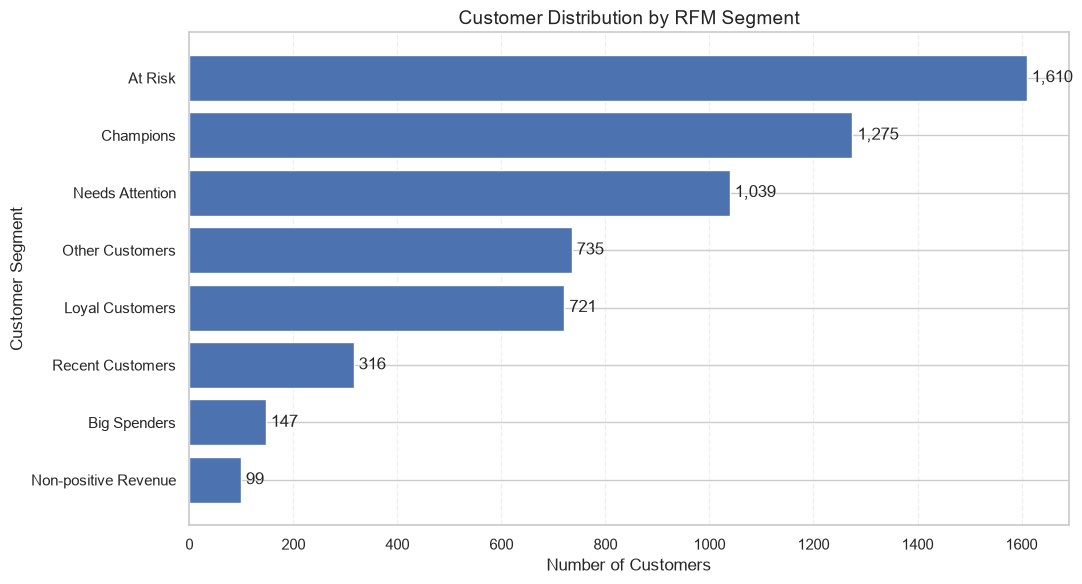

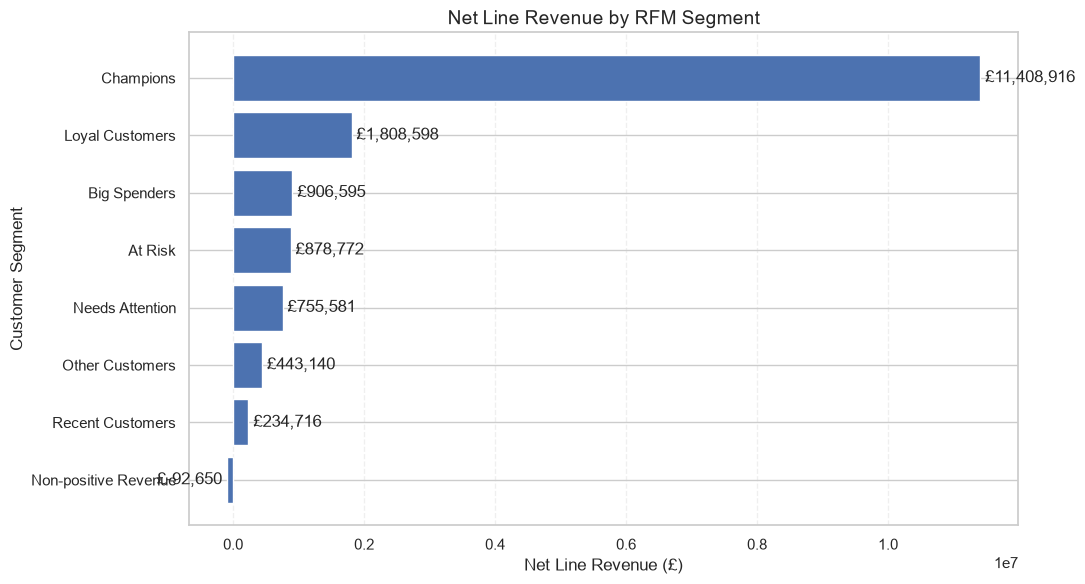

In [70]:
# Step 7.5: Visualise RFM Customer Segments

import matplotlib.pyplot as plt

# Sort segments by customer count for the first chart
segment_counts = (
    rfm_segment_summary
    .sort_values("Customer_Count", ascending=True)
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    segment_counts["Customer_Segment"],
    segment_counts["Customer_Count"]
)

plt.title("Customer Distribution by RFM Segment", fontsize=14)
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.grid(axis="x", linestyle="--", alpha=0.3)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {int(width):,}",
        va="center"
    )

plt.tight_layout()
plt.show()


# Sort segments by net line revenue for the second chart
segment_revenue = (
    rfm_segment_summary
    .sort_values("Total_Net_Line_Revenue", ascending=True)
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    segment_revenue["Customer_Segment"],
    segment_revenue["Total_Net_Line_Revenue"]
)

plt.title("Net Line Revenue by RFM Segment", fontsize=14)
plt.xlabel("Net Line Revenue (£)")
plt.ylabel("Customer Segment")
plt.grid(axis="x", linestyle="--", alpha=0.3)

for bar in bars:
    width = bar.get_width()
    label = f"£{width:,.0f}"

    if width >= 0:
        plt.text(
            width,
            bar.get_y() + bar.get_height() / 2,
            f" {label}",
            va="center"
        )
    else:
        plt.text(
            width,
            bar.get_y() + bar.get_height() / 2,
            f"{label} ",
            ha="right",
            va="center"
        )

plt.tight_layout()
plt.show()

## Country-Level Sales Analysis

In [71]:
# Step 8.1: Country-Level Sales Performance

country_performance = (
    df_clean.groupby("Country", dropna=False)
    .agg(
        Transaction_Lines=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique"),
        Unique_Customers=("Customer ID", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Net_Line_Revenue=("Revenue", "sum"),
        Positive_Revenue=("Revenue", lambda x: x[x > 0].sum()),
        Negative_Revenue=("Revenue", lambda x: x[x < 0].sum())
    )
    .reset_index()
)

# Calculate revenue per invoice
country_performance["Revenue_Per_Invoice"] = (
    country_performance["Net_Line_Revenue"]
    / country_performance["Unique_Invoices"].replace(0, float("nan"))
)

# Calculate each country's share of total net line revenue
total_net_revenue = country_performance["Net_Line_Revenue"].sum()

country_performance["Revenue_Share_Percent"] = (
    country_performance["Net_Line_Revenue"] / total_net_revenue * 100
)

# Sort countries by net line revenue
country_performance = country_performance.sort_values(
    "Net_Line_Revenue",
    ascending=False
).reset_index(drop=True)

# Display the top 15 countries
display(
    country_performance.head(15).round(2)
)

# Validate that country-level revenue reconciles to the full dataset
print("\nValidation")
print("-" * 50)
print("Countries analysed:", country_performance["Country"].nunique())
print("Country-level net line revenue:", round(country_performance["Net_Line_Revenue"].sum(), 2))
print("Original dataset net line revenue:", round(df_clean["Revenue"].sum(), 2))
print(
    "Revenue reconciles:",
    abs(country_performance["Net_Line_Revenue"].sum() - df_clean["Revenue"].sum()) < 0.01
)

,Country,Transaction_Lines,Unique_Invoices,Unique_Customers,Total_Quantity,Net_Line_Revenue,Positive_Revenue,Negative_Revenue,Revenue_Per_Invoice,Revenue_Share_Percent
0,United Kingdom,959983,49108,5410,8544941,16038601.66,17466269.91,-1427668.25,326.60,84.82
1,EIRE,17689,806,5,327618,610244.27,659149.00,-48904.73,757.13,3.23
2,Netherlands,5138,250,23,381854,548332.35,554039.74,-5707.39,2193.33,2.90
3,Germany,17363,1095,107,222030,412517.83,425578.38,-13060.55,376.73,2.18
4,France,14059,746,95,181768,321928.53,350654.18,-28725.65,431.54,1.70
5,Australia,1891,117,15,103385,166511.92,169350.96,-2839.04,1423.18,0.88
6,Switzerland,3183,123,22,52268,99425.36,100707.89,-1282.53,808.34,0.53
7,Spain,3766,188,41,44689,91064.76,108383.81,-17319.05,484.39,0.48
8,Sweden,1364,129,19,87875,87809.42,91903.72,-4094.30,680.69,0.46
9,Denmark,797,53,12,234764,64459.59,68580.69,-4121.10,1216.22,0.34



Validation
--------------------------------------------------
Countries analysed: 43
Country-level net line revenue: 18909762.12
Original dataset net line revenue: 18909762.12
Revenue reconciles: True


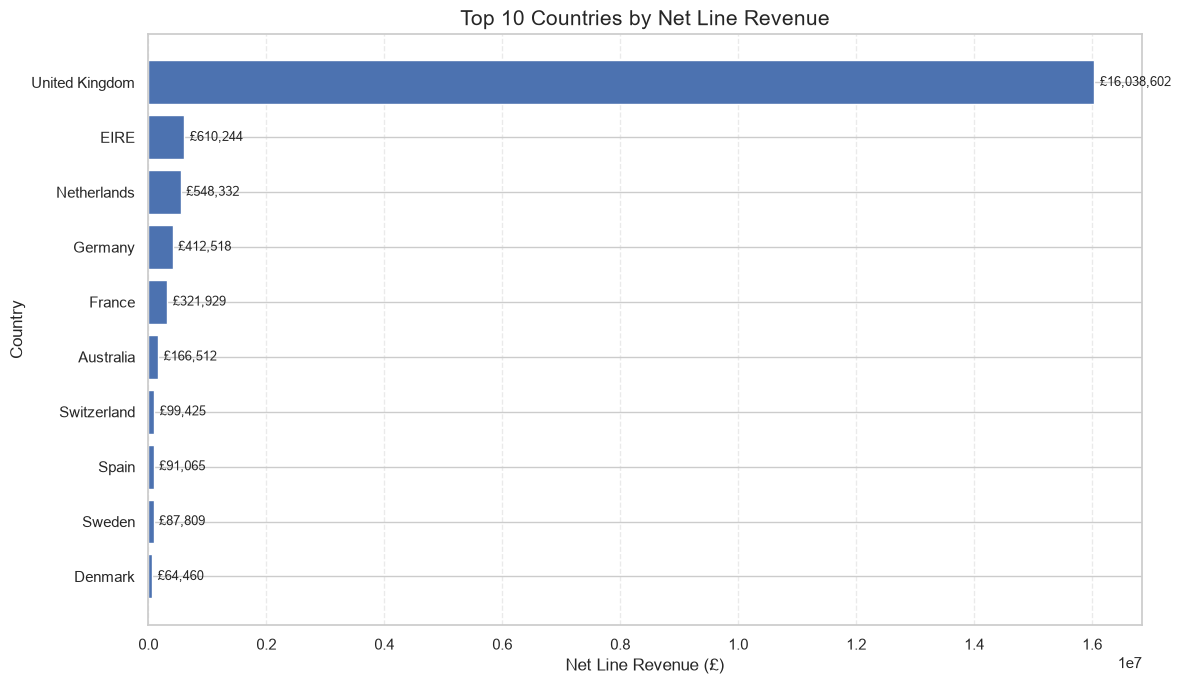

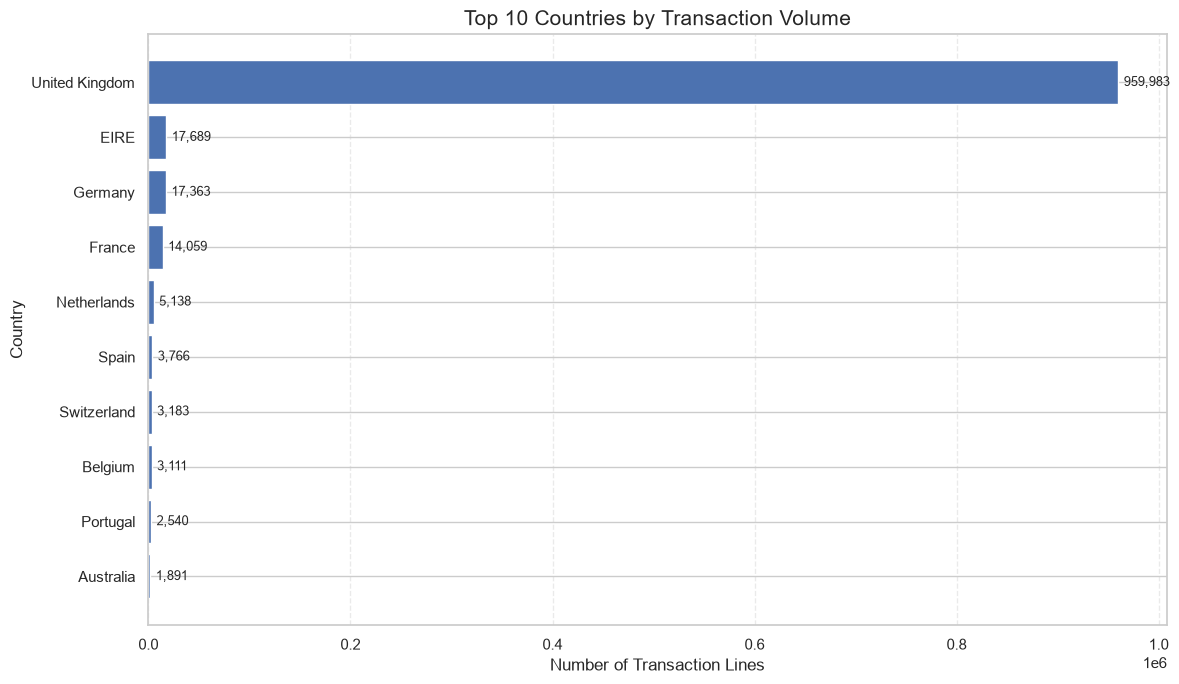

In [72]:
# Step 8.2: Country-Level Performance Visualisations

import matplotlib.pyplot as plt

# Chart 1: Top 10 countries by net line revenue
top_countries_revenue = (
    country_performance
    .sort_values("Net_Line_Revenue", ascending=True)
    .tail(10)
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_countries_revenue["Country"],
    top_countries_revenue["Net_Line_Revenue"]
)

plt.bar_label(
    bars,
    labels=[
        f"£{value:,.0f}"
        for value in top_countries_revenue["Net_Line_Revenue"]
    ],
    padding=4,
    fontsize=9
)

plt.title("Top 10 Countries by Net Line Revenue", fontsize=15)
plt.xlabel("Net Line Revenue (£)")
plt.ylabel("Country")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# Chart 2: Top 10 countries by transaction volume
top_countries_transactions = (
    country_performance
    .sort_values("Transaction_Lines", ascending=True)
    .tail(10)
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_countries_transactions["Country"],
    top_countries_transactions["Transaction_Lines"]
)

plt.bar_label(
    bars,
    labels=[
        f"{value:,.0f}"
        for value in top_countries_transactions["Transaction_Lines"]
    ],
    padding=4,
    fontsize=9
)

plt.title("Top 10 Countries by Transaction Volume", fontsize=15)
plt.xlabel("Number of Transaction Lines")
plt.ylabel("Country")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [73]:
# Step 8.3: International Market Analysis (Excluding UK)

international_markets = (
    country_performance[
        country_performance["Country"] != "United Kingdom"
    ]
    .sort_values("Net_Line_Revenue", ascending=False)
    .reset_index(drop=True)
)

# Display the top 10 international markets
display(
    international_markets[
        [
            "Country",
            "Transaction_Lines",
            "Unique_Invoices",
            "Unique_Customers",
            "Net_Line_Revenue",
            "Revenue_Per_Invoice",
            "Revenue_Share_Percent"
        ]
    ].head(10).round(2)
)

# Summary statistics for international markets
print("\nInternational Market Summary")
print("-" * 45)

print("Number of international markets:", international_markets["Country"].nunique())

print(
    "Combined international net line revenue: £",
    f"{international_markets['Net_Line_Revenue'].sum():,.2f}"
)

print(
    "International share of total net line revenue:",
    f"{international_markets['Revenue_Share_Percent'].sum():.2f}%"
)

print(
    "Highest-revenue international market:",
    international_markets.loc[
        international_markets["Net_Line_Revenue"].idxmax(),
        "Country"
    ]
)

,Country,Transaction_Lines,Unique_Invoices,Unique_Customers,Net_Line_Revenue,Revenue_Per_Invoice,Revenue_Share_Percent
0,EIRE,17689,806,5,610244.27,757.13,3.23
1,Netherlands,5138,250,23,548332.35,2193.33,2.90
2,Germany,17363,1095,107,412517.83,376.73,2.18
3,France,14059,746,95,321928.53,431.54,1.70
4,Australia,1891,117,15,166511.92,1423.18,0.88
5,Switzerland,3183,123,22,99425.36,808.34,0.53
6,Spain,3766,188,41,91064.76,484.39,0.48
7,Sweden,1364,129,19,87809.42,680.69,0.46
8,Denmark,797,53,12,64459.59,1216.22,0.34
9,Belgium,3111,183,29,63228.39,345.51,0.33



International Market Summary
---------------------------------------------
Number of international markets: 42
Combined international net line revenue: £ 2,871,160.46
International share of total net line revenue: 15.18%
Highest-revenue international market: EIRE


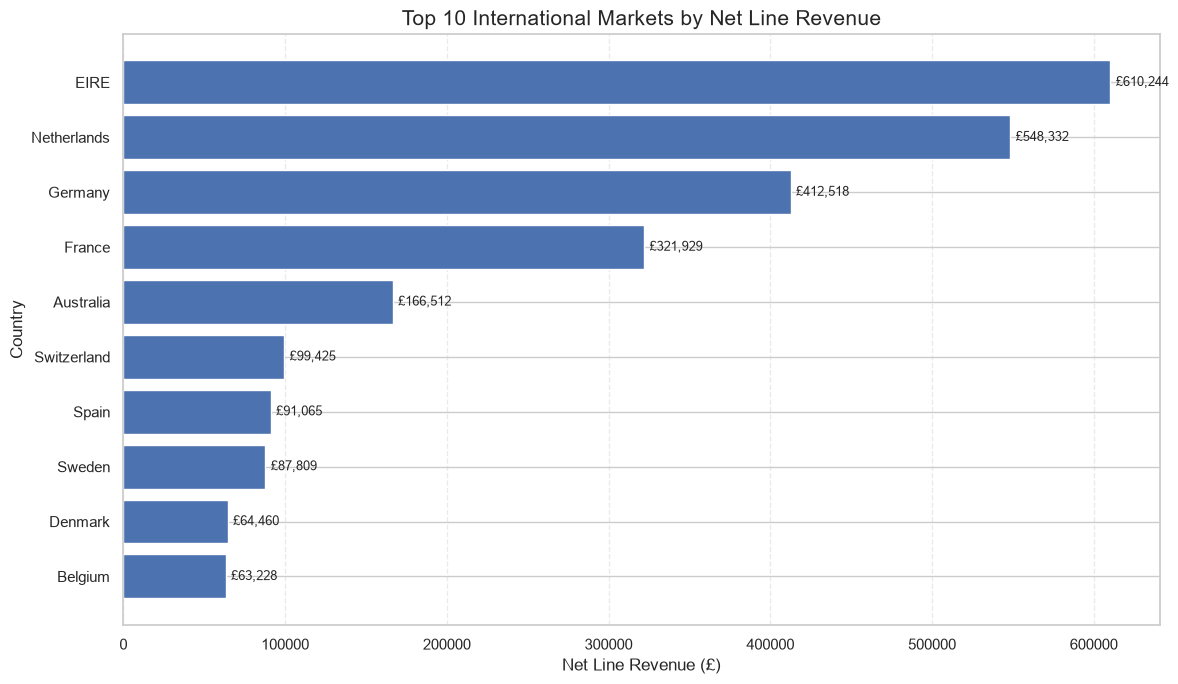

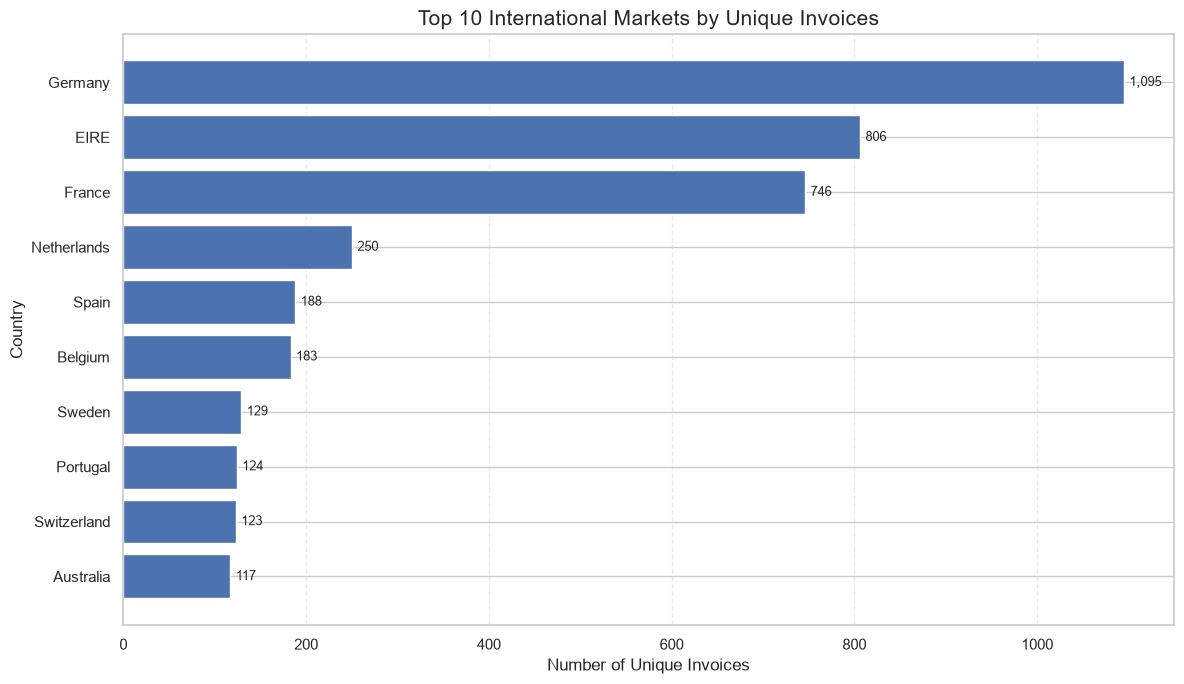

In [74]:
# Step 8.4: International Market Visualisations

import matplotlib.pyplot as plt

# Chart 1: Top 10 international markets by net line revenue
top_international_revenue = (
    international_markets
    .nlargest(10, "Net_Line_Revenue")
    .sort_values("Net_Line_Revenue", ascending=True)
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_international_revenue["Country"],
    top_international_revenue["Net_Line_Revenue"]
)

plt.bar_label(
    bars,
    labels=[
        f"£{value:,.0f}"
        for value in top_international_revenue["Net_Line_Revenue"]
    ],
    padding=4,
    fontsize=9
)

plt.title("Top 10 International Markets by Net Line Revenue", fontsize=15)
plt.xlabel("Net Line Revenue (£)")
plt.ylabel("Country")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# Chart 2: Top 10 international markets by unique invoices
top_international_invoices = (
    international_markets
    .nlargest(10, "Unique_Invoices")
    .sort_values("Unique_Invoices", ascending=True)
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_international_invoices["Country"],
    top_international_invoices["Unique_Invoices"]
)

plt.bar_label(
    bars,
    labels=[
        f"{value:,.0f}"
        for value in top_international_invoices["Unique_Invoices"]
    ],
    padding=4,
    fontsize=9
)

plt.title("Top 10 International Markets by Unique Invoices", fontsize=15)
plt.xlabel("Number of Unique Invoices")
plt.ylabel("Country")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## Order Value Analysis

In [75]:
# Step 9.1: Average Revenue Per Invoice Analysis

# Create an analytical view excluding the UK
order_value_analysis = (
    international_markets[
        [
            "Country",
            "Unique_Invoices",
            "Net_Line_Revenue",
            "Revenue_Per_Invoice"
        ]
    ]
    .copy()
)

# Sort by average net line revenue per invoice
order_value_analysis = (
    order_value_analysis
    .sort_values("Revenue_Per_Invoice", ascending=False)
    .reset_index(drop=True)
)

print("Top 10 International Markets by Average Revenue Per Invoice")
print("=" * 65)

display(
    order_value_analysis.head(10).round(2)
)

# Compare the leading markets
print("\nComparison of Leading International Markets")
print("=" * 50)

comparison_countries = ["EIRE", "Netherlands", "Germany", "France"]

display(
    order_value_analysis[
        order_value_analysis["Country"].isin(comparison_countries)
    ]
    .sort_values("Revenue_Per_Invoice", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

Top 10 International Markets by Average Revenue Per Invoice


,Country,Unique_Invoices,Net_Line_Revenue,Revenue_Per_Invoice
0,Netherlands,250,548332.35,2193.33
1,Thailand,2,3070.54,1535.27
2,Australia,117,166511.92,1423.18
3,Bermuda,1,1253.14,1253.14
4,Denmark,53,64459.59,1216.22
5,Israel,11,11107.22,1009.75
6,Singapore,14,13158.16,939.87
7,Greece,21,18995.49,904.55
8,Lithuania,6,4892.68,815.45
9,Switzerland,123,99425.36,808.34



Comparison of Leading International Markets


,Country,Unique_Invoices,Net_Line_Revenue,Revenue_Per_Invoice
0,Netherlands,250,548332.35,2193.33
1,EIRE,806,610244.27,757.13
2,France,746,321928.53,431.54
3,Germany,1095,412517.83,376.73


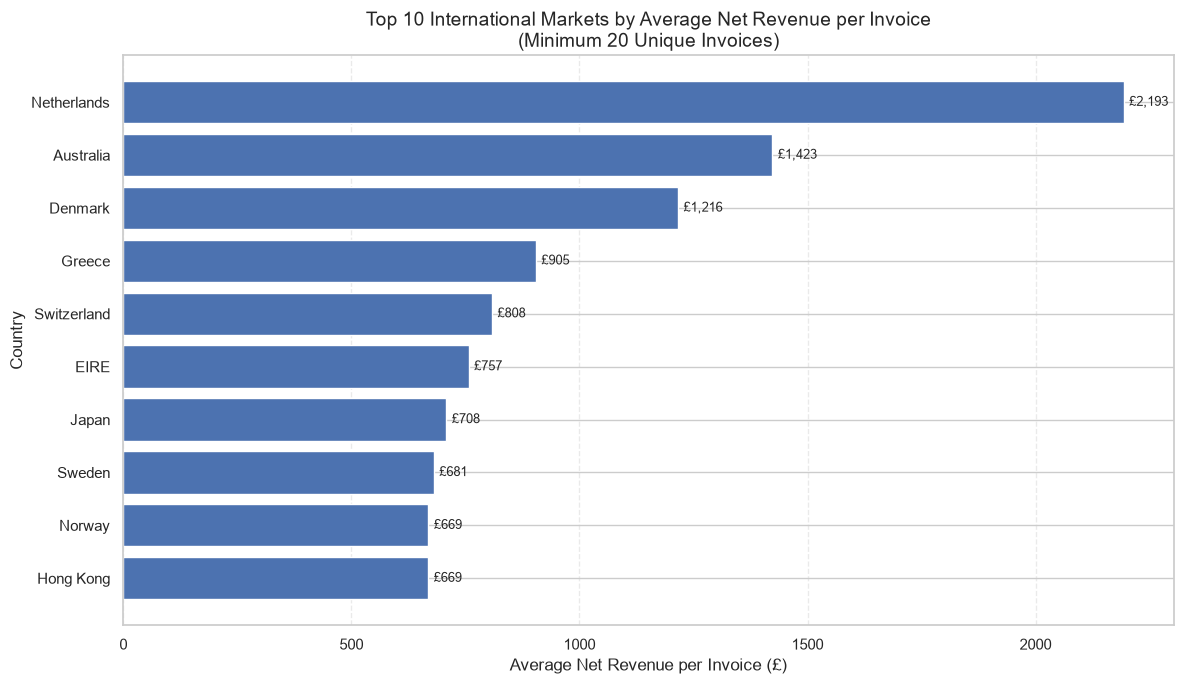

,Country,Unique_Invoices,Net_Line_Revenue,Revenue_Per_Invoice
0,Netherlands,250,548332.35,2193.33
1,Australia,117,166511.92,1423.18
2,Denmark,53,64459.59,1216.22
3,Greece,21,18995.49,904.55
4,Switzerland,123,99425.36,808.34
5,EIRE,806,610244.27,757.13
6,Japan,56,39662.10,708.25
7,Sweden,129,87809.42,680.69
8,Norway,53,35455.91,668.98
9,Hong Kong,21,14039.30,668.54


In [76]:
# Step 9.2: Average Revenue Per Invoice by International Market

import matplotlib.pyplot as plt

# Filter markets with at least 20 unique invoices
reliable_invoice_markets = international_markets[
    international_markets["Unique_Invoices"] >= 20
].copy()

# Select the top 10 by average net revenue per invoice
top_markets_by_invoice_value = (
    reliable_invoice_markets
    .nlargest(10, "Revenue_Per_Invoice")
    .sort_values("Revenue_Per_Invoice", ascending=True)
)

# Plot the results
plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_markets_by_invoice_value["Country"],
    top_markets_by_invoice_value["Revenue_Per_Invoice"]
)

plt.bar_label(
    bars,
    labels=[
        f"£{value:,.0f}"
        for value in top_markets_by_invoice_value["Revenue_Per_Invoice"]
    ],
    padding=4,
    fontsize=9
)

plt.title(
    "Top 10 International Markets by Average Net Revenue per Invoice\n"
    "(Minimum 20 Unique Invoices)",
    fontsize=14
)

plt.xlabel("Average Net Revenue per Invoice (£)")
plt.ylabel("Country")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Display the supporting data
display(
    top_markets_by_invoice_value[
        [
            "Country",
            "Unique_Invoices",
            "Net_Line_Revenue",
            "Revenue_Per_Invoice"
        ]
    ]
    .sort_values("Revenue_Per_Invoice", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

## Invoice-Level Analysis

In [77]:
# Step 10.1: Create Invoice-Level Dataset

invoice_analysis = (
    df_clean.groupby("Invoice", dropna=False)
    .agg(
        InvoiceDate=("InvoiceDate", "min"),
        Country=("Country", "first"),
        Customer_ID=("Customer ID", "first"),
        Transaction_Lines=("StockCode", "size"),
        Total_Quantity=("Quantity", "sum"),
        Net_Line_Revenue=("Revenue", "sum"),
        Positive_Revenue=("Revenue", lambda x: x[x > 0].sum()),
        Negative_Revenue=("Revenue", lambda x: x[x < 0].sum())
    )
    .reset_index()
)

# Calculate revenue per transaction line
invoice_analysis["Revenue_Per_Line"] = (
    invoice_analysis["Net_Line_Revenue"]
    / invoice_analysis["Transaction_Lines"].replace(0, float("nan"))
)

# Display a sample
print("Invoice-Level Dataset")
print("-" * 40)

display(invoice_analysis.head(10).round(2))

# Validate the aggregation
print("\nValidation")
print("-" * 40)

print("Invoice-level rows:", len(invoice_analysis))
print("Unique invoice IDs in source:", df_clean["Invoice"].nunique())

print(
    "Net line revenue reconciles:",
    abs(
        invoice_analysis["Net_Line_Revenue"].sum()
        - df_clean["Revenue"].sum()
    ) < 0.01
)

print(
    "Total transaction lines reconcile:",
    invoice_analysis["Transaction_Lines"].sum()
    == len(df_clean)
)

Invoice-Level Dataset
----------------------------------------


C:\Users\ADITYA\AppData\Local\Temp\ipykernel_23300\943217894.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(invoice_analysis.head(10).round(2))


,Invoice,InvoiceDate,Country,Customer_ID,Transaction_Lines,Total_Quantity,Net_Line_Revenue,Positive_Revenue,Negative_Revenue,Revenue_Per_Line
0,489434,2009-12-01 07:45:00,United Kingdom,13085.0,8,166,505.30,505.30,0.0,63.16
1,489435,2009-12-01 07:46:00,United Kingdom,13085.0,4,60,145.80,145.80,0.0,36.45
2,489436,2009-12-01 09:06:00,United Kingdom,13078.0,19,193,630.33,630.33,0.0,33.18
3,489437,2009-12-01 09:08:00,United Kingdom,15362.0,23,145,310.75,310.75,0.0,13.51
4,489438,2009-12-01 09:24:00,United Kingdom,18102.0,17,826,2286.24,2286.24,0.0,134.48
5,489439,2009-12-01 09:28:00,France,12682.0,19,219,426.30,426.30,0.0,22.44
6,489440,2009-12-01 09:43:00,United Kingdom,18087.0,2,16,50.40,50.40,0.0,25.20
7,489441,2009-12-01 09:44:00,United Kingdom,18087.0,4,102,344.34,344.34,0.0,86.08
8,489442,2009-12-01 09:46:00,United Kingdom,13635.0,23,275,382.37,382.37,0.0,16.62
9,489443,2009-12-01 09:50:00,United Kingdom,14110.0,7,120,285.06,285.06,0.0,40.72



Validation
----------------------------------------
Invoice-level rows: 53628
Unique invoice IDs in source: 53628
Net line revenue reconciles: True
Total transaction lines reconcile: True


In [78]:
# Step 10.2: Invoice Revenue Distribution Analysis

import numpy as np

invoice_revenue = invoice_analysis["Net_Line_Revenue"]

# Overall invoice revenue statistics
print("INVOICE REVENUE DISTRIBUTION")
print("=" * 50)

print(f"Total invoices: {len(invoice_analysis):,}")
print(f"Mean net revenue per invoice: £{invoice_revenue.mean():,.2f}")
print(f"Median net revenue per invoice: £{invoice_revenue.median():,.2f}")
print(f"Minimum net revenue: £{invoice_revenue.min():,.2f}")
print(f"Maximum net revenue: £{invoice_revenue.max():,.2f}")
print(f"Standard deviation: £{invoice_revenue.std():,.2f}")

# Classify invoices by net revenue
invoice_analysis["Invoice_Revenue_Status"] = np.select(
    [
        invoice_analysis["Net_Line_Revenue"] > 0,
        invoice_analysis["Net_Line_Revenue"] < 0
    ],
    [
        "Positive Revenue",
        "Negative Revenue"
    ],
    default="Zero Revenue"
)

# Summarise invoice revenue status
invoice_status_summary = (
    invoice_analysis
    .groupby("Invoice_Revenue_Status")
    .agg(
        Invoice_Count=("Invoice", "size"),
        Total_Net_Revenue=("Net_Line_Revenue", "sum")
    )
    .reset_index()
)

invoice_status_summary["Invoice_Share_Percent"] = (
    invoice_status_summary["Invoice_Count"]
    / len(invoice_analysis)
    * 100
)

print("\nINVOICE REVENUE STATUS")
print("=" * 50)

display(invoice_status_summary.round(2))

# Validate invoice status counts
print("\nValidation")
print("-" * 30)
print(
    "Status counts reconcile:",
    invoice_status_summary["Invoice_Count"].sum() == len(invoice_analysis)
)

INVOICE REVENUE DISTRIBUTION
Total invoices: 53,628
Mean net revenue per invoice: £352.61
Median net revenue per invoice: £193.76
Minimum net revenue: £-168,469.60
Maximum net revenue: £168,469.60
Standard deviation: £1,619.12

INVOICE REVENUE STATUS


,Invoice_Revenue_Status,Invoice_Count,Total_Net_Revenue,Invoice_Share_Percent
0,Negative Revenue,8296,-1624353.37,15.47
1,Positive Revenue,40078,20534115.49,74.73
2,Zero Revenue,5254,0.00,9.80



Validation
------------------------------
Status counts reconcile: True


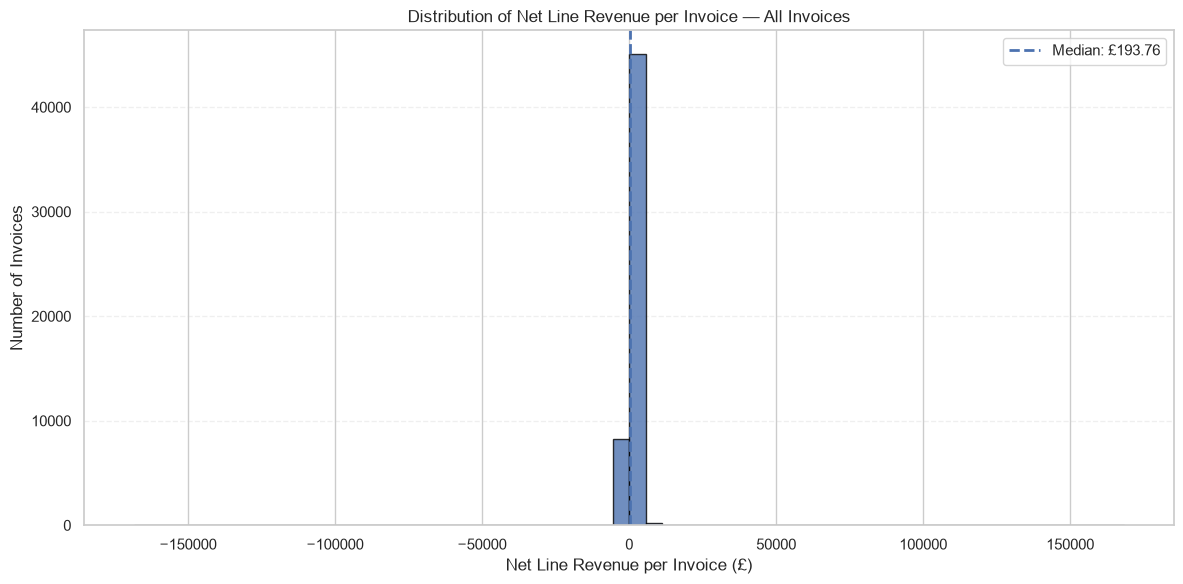

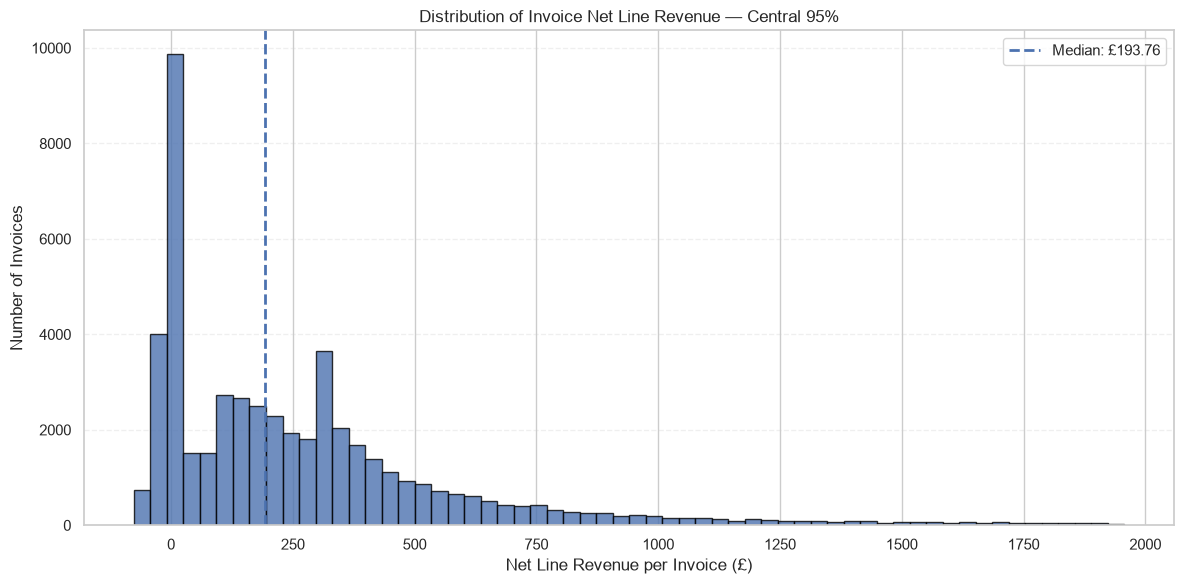

Distribution inspection
----------------------------------------
Lower 2.5th percentile: £-76.32
Upper 97.5th percentile: £1,957.98
All invoices: 53,628
Invoices in central 95% view: 50,946


In [79]:
# Step 10.3: Visualise Invoice Revenue Distribution

import matplotlib.pyplot as plt

invoice_revenue = invoice_analysis["Net_Line_Revenue"].dropna()

# Calculate the 2.5th and 97.5th percentiles
lower_bound = invoice_revenue.quantile(0.025)
upper_bound = invoice_revenue.quantile(0.975)

# Chart 1: All invoices
plt.figure(figsize=(12, 6))

plt.hist(
    invoice_revenue,
    bins=60,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    invoice_revenue.median(),
    linestyle="--",
    linewidth=2,
    label=f"Median: £{invoice_revenue.median():,.2f}"
)

plt.title("Distribution of Net Line Revenue per Invoice — All Invoices")
plt.xlabel("Net Line Revenue per Invoice (£)")
plt.ylabel("Number of Invoices")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


# Chart 2: Central 95% of invoices
central_invoices = invoice_revenue[
    invoice_revenue.between(lower_bound, upper_bound)
]

plt.figure(figsize=(12, 6))

plt.hist(
    central_invoices,
    bins=60,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    central_invoices.median(),
    linestyle="--",
    linewidth=2,
    label=f"Median: £{central_invoices.median():,.2f}"
)

plt.title("Distribution of Invoice Net Line Revenue — Central 95%")
plt.xlabel("Net Line Revenue per Invoice (£)")
plt.ylabel("Number of Invoices")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

print("Distribution inspection")
print("-" * 40)
print(f"Lower 2.5th percentile: £{lower_bound:,.2f}")
print(f"Upper 97.5th percentile: £{upper_bound:,.2f}")
print(f"All invoices: {len(invoice_revenue):,}")
print(f"Invoices in central 95% view: {len(central_invoices):,}")

In [80]:
# Step 10.4: Investigate Extreme Invoice Values

invoice_columns = [
    "Invoice",
    "InvoiceDate",
    "Country",
    "Customer_ID",
    "Transaction_Lines",
    "Total_Quantity",
    "Positive_Revenue",
    "Negative_Revenue",
    "Net_Line_Revenue"
]

# 10 invoices with the highest net line revenue
top_10_invoices = (
    invoice_analysis
    .nlargest(10, "Net_Line_Revenue")[invoice_columns]
    .reset_index(drop=True)
)

# 10 invoices with the lowest net line revenue
bottom_10_invoices = (
    invoice_analysis
    .nsmallest(10, "Net_Line_Revenue")[invoice_columns]
    .reset_index(drop=True)
)

print("TOP 10 INVOICES BY NET LINE REVENUE")
print("=" * 60)

display(top_10_invoices.round(2))

print("\nBOTTOM 10 INVOICES BY NET LINE REVENUE")
print("=" * 60)

display(bottom_10_invoices.round(2))

# Summary of extreme invoice values
print("\nEXTREME VALUE SUMMARY")
print("=" * 40)

print(
    "Highest net line revenue:",
    f"£{invoice_analysis['Net_Line_Revenue'].max():,.2f}"
)

print(
    "Lowest net line revenue:",
    f"£{invoice_analysis['Net_Line_Revenue'].min():,.2f}"
)

print(
    "Invoices with net revenue above £10,000:",
    int((invoice_analysis["Net_Line_Revenue"] > 10000).sum())
)

print(
    "Invoices with net revenue below -£10,000:",
    int((invoice_analysis["Net_Line_Revenue"] < -10000).sum())
)

TOP 10 INVOICES BY NET LINE REVENUE


C:\Users\ADITYA\AppData\Local\Temp\ipykernel_23300\2600274685.py:32: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(top_10_invoices.round(2))


,Invoice,InvoiceDate,Country,Customer_ID,Transaction_Lines,Total_Quantity,Positive_Revenue,Negative_Revenue,Net_Line_Revenue
0,581483,2011-12-09 09:15:00,United Kingdom,16446.0,1,80995,168469.60,0.0,168469.60
1,541431,2011-01-18 10:01:00,United Kingdom,12346.0,1,74215,77183.60,0.0,77183.60
2,574941,2011-11-07 17:42:00,United Kingdom,NaN,101,14149,52940.94,0.0,52940.94
3,576365,2011-11-14 17:55:00,United Kingdom,NaN,99,13956,50653.91,0.0,50653.91
4,533027,2010-11-15 16:02:00,United Kingdom,NaN,111,13387,49844.99,0.0,49844.99
5,531516,2010-11-08 16:45:00,United Kingdom,NaN,115,12410,45332.97,0.0,45332.97
6,493819,2010-01-07 12:34:00,EIRE,14156.0,94,25018,44051.60,0.0,44051.60
7,556444,2011-06-10 15:28:00,United Kingdom,15098.0,1,60,38970.00,0.0,38970.00
8,524181,2010-09-27 16:59:00,United Kingdom,17450.0,14,8820,33167.80,0.0,33167.80
9,567423,2011-09-20 11:05:00,United Kingdom,17450.0,12,12572,31698.16,0.0,31698.16



BOTTOM 10 INVOICES BY NET LINE REVENUE


C:\Users\ADITYA\AppData\Local\Temp\ipykernel_23300\2600274685.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(bottom_10_invoices.round(2))


,Invoice,InvoiceDate,Country,Customer_ID,Transaction_Lines,Total_Quantity,Positive_Revenue,Negative_Revenue,Net_Line_Revenue
0,C581484,2011-12-09 09:27:00,United Kingdom,16446.0,1,-80995,0.0,-168469.60,-168469.60
1,C541433,2011-01-18 10:17:00,United Kingdom,12346.0,1,-74215,0.0,-77183.60,-77183.60
2,A506401,2010-04-29 13:36:00,United Kingdom,NaN,1,1,0.0,-53594.36,-53594.36
3,A516228,2010-07-19 11:24:00,United Kingdom,NaN,1,1,0.0,-44031.79,-44031.79
4,C556445,2011-06-10 15:31:00,United Kingdom,15098.0,1,-1,0.0,-38970.00,-38970.00
5,A528059,2010-10-20 12:04:00,United Kingdom,NaN,1,1,0.0,-38925.87,-38925.87
6,C512770,2010-06-17 16:52:00,United Kingdom,17399.0,1,-1,0.0,-25111.09,-25111.09
7,C550456,2011-04-18 13:08:00,United Kingdom,15749.0,5,-9014,0.0,-22998.40,-22998.40
8,C520667,2010-08-27 13:42:00,United Kingdom,NaN,1,-1,0.0,-18910.69,-18910.69
9,C580605,2011-12-05 11:36:00,United Kingdom,NaN,1,-1,0.0,-17836.46,-17836.46



EXTREME VALUE SUMMARY
Highest net line revenue: £168,469.60
Lowest net line revenue: £-168,469.60
Invoices with net revenue above £10,000: 93
Invoices with net revenue below -£10,000: 25


In [81]:
# Step 10.5: Inspect Matching High-Value and Cancellation Invoices

invoice_ids_to_check = [
    "581483", "C581484",
    "541431", "C541433",
    "556444", "C556445"
]

# Convert invoice IDs to strings for consistent matching
invoice_detail_check = df_clean[
    df_clean["Invoice"].astype(str).isin(invoice_ids_to_check)
].copy()

# Sort by invoice and transaction date
invoice_detail_check = invoice_detail_check.sort_values(
    ["Invoice", "InvoiceDate", "StockCode"]
)

columns_to_display = [
    "Invoice",
    "InvoiceDate",
    "StockCode",
    "Description",
    "Quantity",
    "Price",
    "Revenue",
    "Customer ID"
]

print("TRANSACTION-LEVEL DETAILS")
print("=" * 70)

display(invoice_detail_check[columns_to_display])

# Summarise each invoice directly from the source rows
print("\nSOURCE-ROW VALIDATION")
print("=" * 70)

invoice_pair_summary = (
    invoice_detail_check
    .groupby("Invoice", dropna=False)
    .agg(
        Transaction_Lines=("StockCode", "size"),
        Total_Quantity=("Quantity", "sum"),
        Net_Line_Revenue=("Revenue", "sum"),
        Unique_Stock_Codes=("StockCode", "nunique")
    )
    .reset_index()
)

display(invoice_pair_summary)

print(
    "\nAll selected invoices found:",
    set(invoice_ids_to_check).issubset(
        set(invoice_detail_check["Invoice"].astype(str).unique())
    )
)

TRANSACTION-LEVEL DETAILS


,Invoice,InvoiceDate,StockCode,Description,Quantity,Price,Revenue,Customer ID
564557,541431,2011-01-18 10:01:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,12346.0
725609,556444,2011-06-10 15:28:00,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.0,15098.0
1043359,581483,2011-12-09 09:15:00,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446.0
564562,C541433,2011-01-18 10:17:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,-77183.6,12346.0
725619,C556445,2011-06-10 15:31:00,M,Manual,-1,38970.00,-38970.0,15098.0
1043360,C581484,2011-12-09 09:27:00,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.6,16446.0



SOURCE-ROW VALIDATION


,Invoice,Transaction_Lines,Total_Quantity,Net_Line_Revenue,Unique_Stock_Codes
0,541431,1,74215,77183.6,1
1,556444,1,60,38970.0,1
2,581483,1,80995,168469.6,1
3,C541433,1,-74215,-77183.6,1
4,C556445,1,-1,-38970.0,1
5,C581484,1,-80995,-168469.6,1



All selected invoices found: True


In [82]:
# Step 10.6: Invoice Composition Analysis

import pandas as pd
import numpy as np

# Create transaction-line categories
invoice_analysis["Invoice_Size_Group"] = pd.cut(
    invoice_analysis["Transaction_Lines"],
    bins=[0, 1, 5, 10, 20, np.inf],
    labels=[
        "1 line",
        "2–5 lines",
        "6–10 lines",
        "11–20 lines",
        "More than 20 lines"
    ],
    include_lowest=True
)

# Summarise invoice characteristics by size group
invoice_size_summary = (
    invoice_analysis
    .groupby("Invoice_Size_Group", observed=False)
    .agg(
        Invoice_Count=("Invoice", "size"),
        Average_Net_Revenue=("Net_Line_Revenue", "mean"),
        Median_Net_Revenue=("Net_Line_Revenue", "median"),
        Total_Net_Revenue=("Net_Line_Revenue", "sum"),
        Average_Total_Quantity=("Total_Quantity", "mean")
    )
    .reset_index()
)

invoice_size_summary["Invoice_Share_Percent"] = (
    invoice_size_summary["Invoice_Count"]
    / len(invoice_analysis)
    * 100
)

print("INVOICE COMPOSITION ANALYSIS")
print("=" * 65)

display(invoice_size_summary.round(2))

print("\nVALIDATION")
print("=" * 40)

print(
    "Invoice counts reconcile:",
    invoice_size_summary["Invoice_Count"].sum() == len(invoice_analysis)
)

print(
    "All invoice size groups assigned:",
    invoice_analysis["Invoice_Size_Group"].notna().all()
)

INVOICE COMPOSITION ANALYSIS


,Invoice_Size_Group,Invoice_Count,Average_Net_Revenue,Median_Net_Revenue,Total_Net_Revenue,Average_Total_Quantity,Invoice_Share_Percent
0,1 line,13570,-6.67,0.00,-90445.29,-6.26,25.30
1,2–5 lines,8754,164.35,48.80,1438687.27,107.14,16.32
2,6–10 lines,6069,322.92,181.10,1959824.40,185.90,11.32
3,11–20 lines,10067,395.84,302.44,3984916.89,229.09,18.77
4,More than 20 lines,15168,765.87,450.86,11616778.85,405.74,28.28



VALIDATION
Invoice counts reconcile: True
All invoice size groups assigned: True


In [83]:
# Step 10.7: Analyse Single-Line Invoices

single_line_invoices = invoice_analysis[
    invoice_analysis["Transaction_Lines"] == 1
].copy()

# Classify revenue status
single_line_invoices["Revenue_Status"] = np.select(
    [
        single_line_invoices["Net_Line_Revenue"] > 0,
        single_line_invoices["Net_Line_Revenue"] < 0
    ],
    [
        "Positive Revenue",
        "Negative Revenue"
    ],
    default="Zero Revenue"
)

# Summarise revenue status
single_line_status = (
    single_line_invoices
    .groupby("Revenue_Status")
    .agg(
        Invoice_Count=("Invoice", "size"),
        Total_Net_Revenue=("Net_Line_Revenue", "sum"),
        Average_Net_Revenue=("Net_Line_Revenue", "mean"),
        Median_Net_Revenue=("Net_Line_Revenue", "median")
    )
    .reset_index()
)

single_line_status["Invoice_Share_Percent"] = (
    single_line_status["Invoice_Count"]
    / len(single_line_invoices)
    * 100
)

print("SINGLE-LINE INVOICE REVENUE ANALYSIS")
print("=" * 60)

display(single_line_status.round(2))

# Customer identification analysis
print("\nCUSTOMER IDENTIFICATION")
print("=" * 60)

missing_customer_count = (
    single_line_invoices["Customer_ID"].isna().sum()
)

identified_customer_count = (
    single_line_invoices["Customer_ID"].notna().sum()
)

print(f"Total single-line invoices: {len(single_line_invoices):,}")
print(f"Invoices with customer ID: {identified_customer_count:,}")
print(f"Invoices without customer ID: {missing_customer_count:,}")

print(
    "Missing customer ID share:",
    f"{missing_customer_count / len(single_line_invoices) * 100:.2f}%"
)

# Validation
print("\nVALIDATION")
print("=" * 40)

print(
    "Revenue-status counts reconcile:",
    single_line_status["Invoice_Count"].sum()
    == len(single_line_invoices)
)

SINGLE-LINE INVOICE REVENUE ANALYSIS


,Revenue_Status,Invoice_Count,Total_Net_Revenue,Average_Net_Revenue,Median_Net_Revenue,Invoice_Share_Percent
0,Negative Revenue,4696,-1242923.75,-264.68,-12.75,34.61
1,Positive Revenue,3629,1152478.46,317.57,45.00,26.74
2,Zero Revenue,5245,0.00,0.00,0.00,38.65



CUSTOMER IDENTIFICATION
Total single-line invoices: 13,570
Invoices with customer ID: 7,447
Invoices without customer ID: 6,123
Missing customer ID share: 45.12%

VALIDATION
Revenue-status counts reconcile: True


In [84]:
# Step 10.8: Investigate Zero-Revenue Single-Line Invoices

# Select single-line invoices with zero net revenue
zero_revenue_single_invoices = single_line_invoices[
    single_line_invoices["Net_Line_Revenue"] == 0
].copy()

# Retrieve their original transaction-level records
zero_invoice_details = df_clean[
    df_clean["Invoice"].astype(str).isin(
        zero_revenue_single_invoices["Invoice"].astype(str)
    )
].copy()

# Display a sample of 20 records
detail_columns = [
    "Invoice",
    "InvoiceDate",
    "StockCode",
    "Description",
    "Quantity",
    "Price",
    "Revenue",
    "Country",
    "Customer ID"
]

print("ZERO-REVENUE SINGLE-LINE INVOICE SAMPLE")
print("=" * 70)

display(
    zero_invoice_details[detail_columns]
    .head(20)
    .reset_index(drop=True)
)

# Examine stock-code patterns
print("\nSTOCK CODE SUMMARY")
print("=" * 70)

stock_code_summary = (
    zero_invoice_details
    .groupby("StockCode", dropna=False)
    .agg(
        Transaction_Lines=("Invoice", "size"),
        Unique_Descriptions=("Description", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum")
    )
    .sort_values("Transaction_Lines", ascending=False)
    .head(15)
    .reset_index()
)

display(stock_code_summary)

# Validate the extracted records
print("\nVALIDATION")
print("=" * 40)

print(
    "Zero-revenue invoice count:",
    len(zero_revenue_single_invoices)
)

print(
    "Original rows retrieved:",
    len(zero_invoice_details)
)

print(
    "All retrieved rows have zero revenue:",
    zero_invoice_details["Revenue"].eq(0).all()
)

ZERO-REVENUE SINGLE-LINE INVOICE SAMPLE


,Invoice,InvoiceDate,StockCode,Description,Quantity,Price,Revenue,Country,Customer ID
0,489464,2009-12-01 10:52:00,21733,85123a mixed,-96,0.0,-0.0,United Kingdom,NaN
1,489463,2009-12-01 10:52:00,71477,short,-240,0.0,-0.0,United Kingdom,NaN
2,489467,2009-12-01 10:53:00,85123A,21733 mixed,-192,0.0,-0.0,United Kingdom,NaN
3,489521,2009-12-01 11:44:00,21646,NaN,-50,0.0,-0.0,United Kingdom,NaN
4,489655,2009-12-01 17:26:00,20683,NaN,-44,0.0,-0.0,United Kingdom,NaN
5,489659,2009-12-01 17:39:00,21350,NaN,230,0.0,0.0,United Kingdom,NaN
6,489660,2009-12-01 17:43:00,35956,lost,-1043,0.0,-0.0,United Kingdom,NaN
7,489663,2009-12-01 18:02:00,35605A,damages,-117,0.0,-0.0,United Kingdom,NaN
8,489781,2009-12-02 11:45:00,84292,NaN,17,0.0,0.0,United Kingdom,NaN
9,489806,2009-12-02 12:42:00,18010,NaN,-770,0.0,-0.0,United Kingdom,NaN



STOCK CODE SUMMARY


,StockCode,Transaction_Lines,Unique_Descriptions,Total_Quantity,Total_Revenue
0,23084,16,6,-34,0.0
1,84990,13,1,-507,0.0
2,22734,13,6,-545,0.0
3,35965,13,3,61,0.0
4,20713,13,8,-2206,0.0
5,79321,11,0,-51,0.0
6,22423,11,6,-349,0.0
7,22139,10,1,20,0.0
8,22087,10,1,-97,0.0
9,22950,10,0,-44,0.0



VALIDATION
Zero-revenue invoice count: 5245
Original rows retrieved: 5245
All retrieved rows have zero revenue: True


In [85]:
# Step 10.9: Verify Price and Description Patterns

# Price distribution for zero-revenue single-line invoices
print("PRICE ANALYSIS")
print("=" * 55)

print(
    "Transactions with zero price:",
    int(zero_invoice_details["Price"].eq(0).sum())
)

print(
    "Transactions with non-zero price:",
    int(zero_invoice_details["Price"].ne(0).sum())
)

print(
    "Transactions with missing price:",
    int(zero_invoice_details["Price"].isna().sum())
)

# Verify the revenue calculation
print("\nREVENUE CALCULATION VALIDATION")
print("=" * 55)

calculated_revenue = (
    zero_invoice_details["Quantity"]
    * zero_invoice_details["Price"]
)

print(
    "All calculated revenues equal recorded revenues:",
    np.allclose(
        calculated_revenue.fillna(0),
        zero_invoice_details["Revenue"].fillna(0)
    )
)

# Summarise price and quantity patterns
print("\nPRICE AND QUANTITY PATTERNS")
print("=" * 55)

price_quantity_summary = (
    zero_invoice_details
    .groupby("Price", dropna=False)
    .agg(
        Transaction_Lines=("Invoice", "size"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Stock_Codes=("StockCode", "nunique")
    )
    .reset_index()
    .sort_values("Transaction_Lines", ascending=False)
)

display(price_quantity_summary.head(15))

# Inspect descriptions
print("\nMOST COMMON DESCRIPTIONS")
print("=" * 55)

description_summary = (
    zero_invoice_details["Description"]
    .fillna("[Missing Description]")
    .value_counts()
    .head(15)
    .rename_axis("Description")
    .reset_index(name="Transaction_Lines")
)

display(description_summary)

PRICE ANALYSIS
Transactions with zero price: 5245
Transactions with non-zero price: 0
Transactions with missing price: 0

REVENUE CALCULATION VALIDATION
All calculated revenues equal recorded revenues: True

PRICE AND QUANTITY PATTERNS


,Price,Transaction_Lines,Total_Quantity,Unique_Stock_Codes
0,0.0,5245,-344738,2805



MOST COMMON DESCRIPTIONS


,Description,Transaction_Lines
0,[Missing Description],4275
1,check,160
2,?,90
3,damages,83
4,damaged,81
5,found,28
6,missing,27
7,sold as set on dotcom,20
8,Damaged,17
9,adjustment,16


In [86]:
# Step 10.10: Classify Zero-Price Transaction Descriptions

zero_invoice_details["Description_Clean"] = (
    zero_invoice_details["Description"]
    .fillna("")
    .str.strip()
    .str.lower()
)

description = zero_invoice_details["Description_Clean"]

conditions = [
    description.eq(""),
    description.str.contains(
        r"damage|damaged|smashed|unsaleable|destroyed|thrown away",
        regex=True,
        na=False
    ),
    description.str.contains(
        r"\bmissing\b|\bfound\b",
        regex=True,
        na=False
    ),
    description.str.contains(
        r"adjustment|^check$|^\?$",
        regex=True,
        na=False
    )
]

categories = [
    "Missing Description",
    "Damage / Unsaleable",
    "Missing / Found",
    "Adjustment / Check"
]

zero_invoice_details["Provisional_Category"] = np.select(
    conditions,
    categories,
    default="Other Description"
)

# Summarise the categories
zero_price_category_summary = (
    zero_invoice_details
    .groupby("Provisional_Category")
    .agg(
        Transaction_Lines=("Invoice", "size"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Stock_Codes=("StockCode", "nunique")
    )
    .reset_index()
    .sort_values("Transaction_Lines", ascending=False)
)

zero_price_category_summary["Transaction_Share_Percent"] = (
    zero_price_category_summary["Transaction_Lines"]
    / len(zero_invoice_details)
    * 100
)

print("PROVISIONAL ZERO-PRICE TRANSACTION CLASSIFICATION")
print("=" * 70)

display(zero_price_category_summary.round(2))

print("\nVALIDATION")
print("=" * 40)

print(
    "Category counts reconcile:",
    zero_price_category_summary["Transaction_Lines"].sum()
    == len(zero_invoice_details)
)

print(
    "All transactions retained:",
    len(zero_invoice_details) == 5245
)

PROVISIONAL ZERO-PRICE TRANSACTION CLASSIFICATION


,Provisional_Category,Transaction_Lines,Total_Quantity,Unique_Stock_Codes,Transaction_Share_Percent
3,Missing Description,4275,-74243,2451,81.51
4,Other Description,345,-113611,270,6.58
0,Adjustment / Check,281,-40029,254,5.36
1,Damage / Unsaleable,261,-96157,238,4.98
2,Missing / Found,83,-20698,79,1.58



VALIDATION
Category counts reconcile: True
All transactions retained: True


In [87]:
# Step 10.11: Analyse Positive-Net-Revenue Invoices

positive_revenue_invoices = invoice_analysis[
    invoice_analysis["Net_Line_Revenue"] > 0
].copy()

print("POSITIVE-NET-REVENUE INVOICE ANALYSIS")
print("=" * 60)

print(f"Number of invoices: {len(positive_revenue_invoices):,}")

print(
    f"Average net line revenue: "
    f"£{positive_revenue_invoices['Net_Line_Revenue'].mean():,.2f}"
)

print(
    f"Median net line revenue: "
    f"£{positive_revenue_invoices['Net_Line_Revenue'].median():,.2f}"
)

print(
    f"Minimum net line revenue: "
    f"£{positive_revenue_invoices['Net_Line_Revenue'].min():,.2f}"
)

print(
    f"Maximum net line revenue: "
    f"£{positive_revenue_invoices['Net_Line_Revenue'].max():,.2f}"
)

print(
    f"Average transaction lines per invoice: "
    f"{positive_revenue_invoices['Transaction_Lines'].mean():.2f}"
)

print(
    f"Average total quantity per invoice: "
    f"{positive_revenue_invoices['Total_Quantity'].mean():,.2f}"
)

# Validation against the original invoice dataset
print("\nVALIDATION")
print("=" * 40)

print(
    "All selected invoices have positive net revenue:",
    positive_revenue_invoices["Net_Line_Revenue"].gt(0).all()
)

print(
    "Original invoice dataset unchanged in row count:",
    len(invoice_analysis) == 53628
)

print(
    "Positive-invoice revenue reconciles:",
    abs(
        positive_revenue_invoices["Net_Line_Revenue"].sum()
        - invoice_analysis.loc[
            invoice_analysis["Net_Line_Revenue"] > 0,
            "Net_Line_Revenue"
        ].sum()
    ) < 0.01
)

POSITIVE-NET-REVENUE INVOICE ANALYSIS
Number of invoices: 40,078
Average net line revenue: £512.35
Median net line revenue: £302.79
Minimum net line revenue: £0.19
Maximum net line revenue: £168,469.60
Average transaction lines per invoice: 25.46
Average total quantity per invoice: 281.02

VALIDATION
All selected invoices have positive net revenue: True
Original invoice dataset unchanged in row count: True
Positive-invoice revenue reconciles: True


In [88]:
# Step 10.12: Invoice Size vs Revenue Analysis

invoice_size_revenue = (
    positive_revenue_invoices
    .groupby("Invoice_Size_Group", observed=False)
    .agg(
        Invoice_Count=("Invoice", "count"),
        Average_Revenue=("Net_Line_Revenue", "mean"),
        Median_Revenue=("Net_Line_Revenue", "median"),
        Total_Revenue=("Net_Line_Revenue", "sum"),
        Average_Transaction_Lines=("Transaction_Lines", "mean"),
        Average_Quantity=("Total_Quantity", "mean")
    )
    .reset_index()
)

# Calculate invoice share and revenue contribution
invoice_size_revenue["Invoice_Share_Percent"] = (
    invoice_size_revenue["Invoice_Count"]
    / invoice_size_revenue["Invoice_Count"].sum()
    * 100
)

invoice_size_revenue["Revenue_Share_Percent"] = (
    invoice_size_revenue["Total_Revenue"]
    / invoice_size_revenue["Total_Revenue"].sum()
    * 100
)

print("POSITIVE-REVENUE INVOICES: SIZE VS REVENUE")
print("=" * 75)

display(invoice_size_revenue.round(2))

print("\nVALIDATION")
print("=" * 45)

print(
    "Invoice counts reconcile:",
    invoice_size_revenue["Invoice_Count"].sum()
    == len(positive_revenue_invoices)
)

print(
    "Revenue reconciles:",
    abs(
        invoice_size_revenue["Total_Revenue"].sum()
        - positive_revenue_invoices["Net_Line_Revenue"].sum()
    ) < 0.01
)

print(
    "Revenue shares total approximately 100%:",
    abs(invoice_size_revenue["Revenue_Share_Percent"].sum() - 100) < 0.01
)

POSITIVE-REVENUE INVOICES: SIZE VS REVENUE


,Invoice_Size_Group,Invoice_Count,Average_Revenue,Median_Revenue,Total_Revenue,Average_Transaction_Lines,Average_Quantity,Invoice_Share_Percent,Revenue_Share_Percent
0,1 line,3629,317.57,45.00,1152478.46,1.00,133.27,9.05,5.61
1,2–5 lines,5670,286.83,121.41,1626354.13,3.39,176.84,14.15,7.92
2,6–10 lines,5733,353.63,191.73,2027377.85,7.95,202.43,14.30,9.87
3,11–20 lines,9940,408.38,303.20,4059343.83,15.35,236.42,24.80,19.77
4,More than 20 lines,15106,772.45,452.59,11668561.22,52.91,414.78,37.69,56.83



VALIDATION
Invoice counts reconcile: True
Revenue reconciles: True
Revenue shares total approximately 100%: True


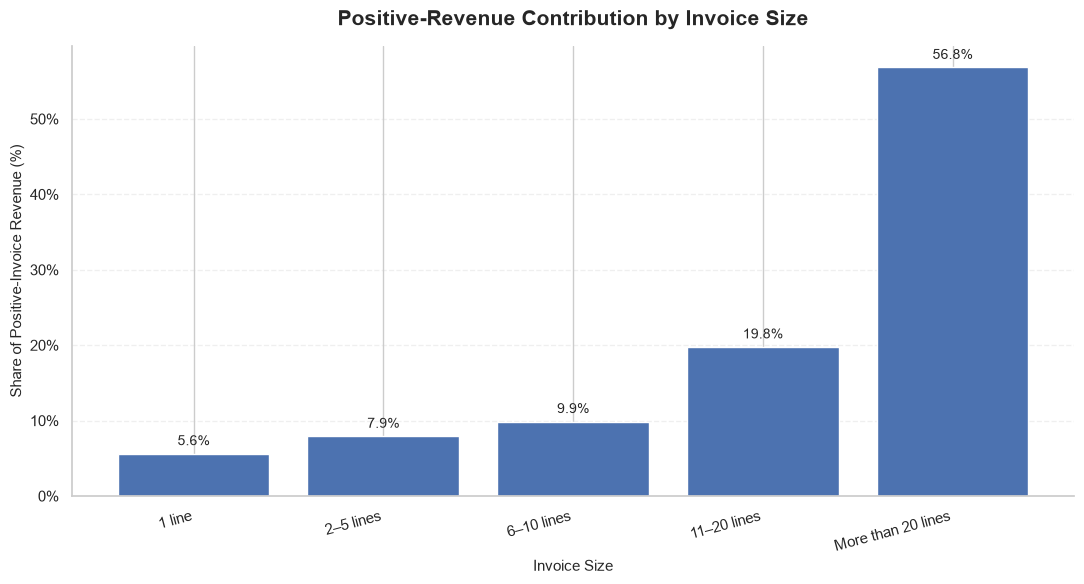

In [89]:
# Step 10.13: Visualise Revenue Contribution by Invoice Size

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plot_data = invoice_size_revenue.copy()

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    plot_data["Invoice_Size_Group"].astype(str),
    plot_data["Revenue_Share_Percent"]
)

ax.set_title(
    "Positive-Revenue Contribution by Invoice Size",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Invoice Size", fontsize=11)
ax.set_ylabel("Share of Positive-Invoice Revenue (%)", fontsize=11)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:.0f}%")
)

ax.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in plot_data["Revenue_Share_Percent"]
    ],
    padding=4,
    fontsize=10
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

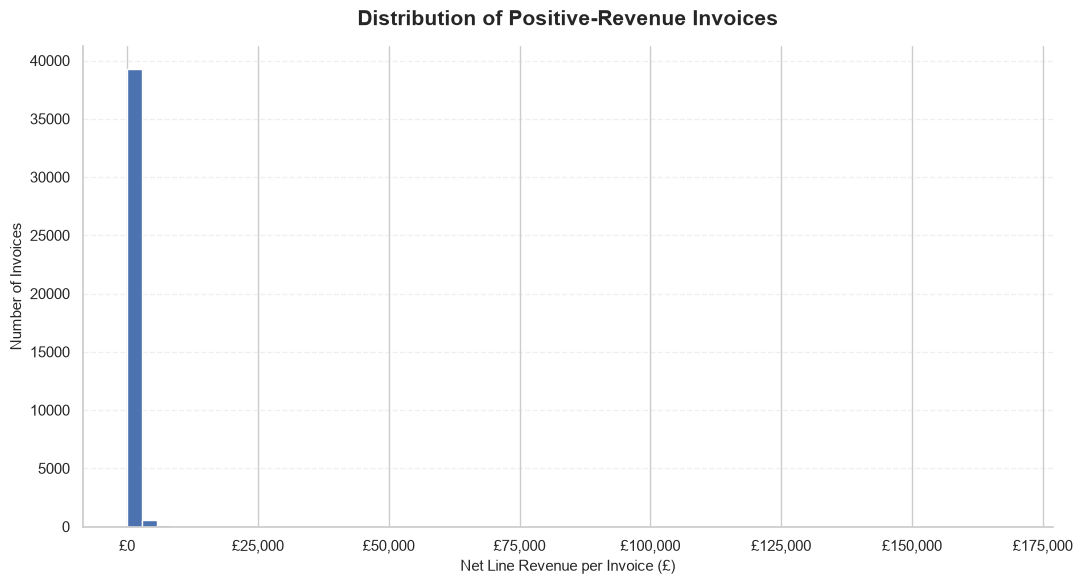

DISTRIBUTION SUMMARY
Median: £302.79
Mean: £512.35
75th percentile: £495.00
90th percentile: £933.33
95th percentile: £1,516.63
99th percentile: £4,408.51


In [90]:
# Step 10.14: Visualise Positive-Invoice Revenue Distribution

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

revenue = positive_revenue_invoices["Net_Line_Revenue"]

fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(revenue, bins=60, edgecolor="white")

ax.set_title(
    "Distribution of Positive-Revenue Invoices",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Net Line Revenue per Invoice (£)", fontsize=11)
ax.set_ylabel("Number of Invoices", fontsize=11)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"£{value:,.0f}")
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("DISTRIBUTION SUMMARY")
print("=" * 50)
print(f"Median: £{revenue.median():,.2f}")
print(f"Mean: £{revenue.mean():,.2f}")
print(f"75th percentile: £{revenue.quantile(0.75):,.2f}")
print(f"90th percentile: £{revenue.quantile(0.90):,.2f}")
print(f"95th percentile: £{revenue.quantile(0.95):,.2f}")
print(f"99th percentile: £{revenue.quantile(0.99):,.2f}")

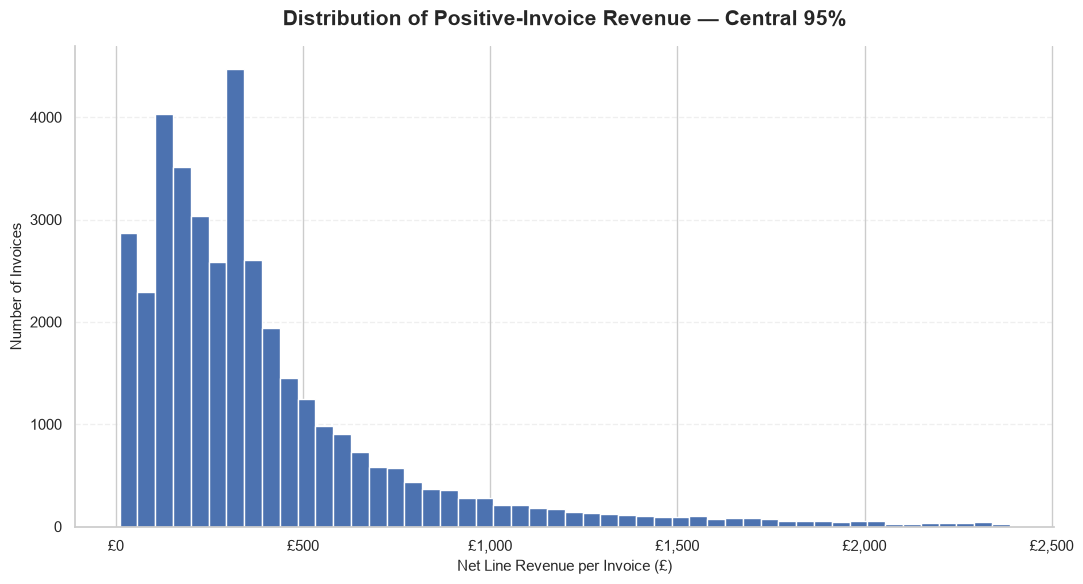

CENTRAL 95% DISTRIBUTION
Lower boundary: £9.85
Upper boundary: £2,388.21
Original positive-revenue invoices: 40,078
Invoices displayed: 38,074
Invoices outside displayed range: 2,004

VALIDATION
Original invoice count unchanged: True
All displayed invoices are within percentile boundaries: True


In [91]:
# Step 10.15: Visualise the Central 95% of Positive-Invoice Revenue

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

revenue = positive_revenue_invoices["Net_Line_Revenue"]

# Calculate percentile boundaries
lower_bound = revenue.quantile(0.025)
upper_bound = revenue.quantile(0.975)

# Filter only for visualisation; retain the original data
central_95_revenue = revenue[
    revenue.between(lower_bound, upper_bound)
]

fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    central_95_revenue,
    bins=50,
    edgecolor="white"
)

ax.set_title(
    "Distribution of Positive-Invoice Revenue — Central 95%",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Net Line Revenue per Invoice (£)", fontsize=11)
ax.set_ylabel("Number of Invoices", fontsize=11)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"£{value:,.0f}")
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("CENTRAL 95% DISTRIBUTION")
print("=" * 55)
print(f"Lower boundary: £{lower_bound:,.2f}")
print(f"Upper boundary: £{upper_bound:,.2f}")
print(f"Original positive-revenue invoices: {len(revenue):,}")
print(f"Invoices displayed: {len(central_95_revenue):,}")
print(f"Invoices outside displayed range: {len(revenue) - len(central_95_revenue):,}")

print("\nVALIDATION")
print("=" * 40)
print(
    "Original invoice count unchanged:",
    len(positive_revenue_invoices) == 40078
)
print(
    "All displayed invoices are within percentile boundaries:",
    central_95_revenue.between(lower_bound, upper_bound).all()
)

In [92]:
# Step 10.16: Compare Invoice Revenue Groups

positive_revenue_invoices["Revenue_Value_Group"] = pd.cut(
    positive_revenue_invoices["Net_Line_Revenue"],
    bins=[
        -np.inf,
        positive_revenue_invoices["Net_Line_Revenue"].quantile(0.75),
        positive_revenue_invoices["Net_Line_Revenue"].quantile(0.95),
        np.inf
    ],
    labels=[
        "Typical-Range Invoices",
        "High-Value Invoices",
        "Exceptional-Value Invoices"
    ],
    include_lowest=True
)

invoice_value_summary = (
    positive_revenue_invoices
    .groupby("Revenue_Value_Group", observed=False)
    .agg(
        Invoice_Count=("Invoice", "count"),
        Total_Revenue=("Net_Line_Revenue", "sum"),
        Average_Revenue=("Net_Line_Revenue", "mean"),
        Median_Revenue=("Net_Line_Revenue", "median")
    )
    .reset_index()
)

invoice_value_summary["Invoice_Share_Percent"] = (
    invoice_value_summary["Invoice_Count"]
    / len(positive_revenue_invoices)
    * 100
)

invoice_value_summary["Revenue_Share_Percent"] = (
    invoice_value_summary["Total_Revenue"]
    / positive_revenue_invoices["Net_Line_Revenue"].sum()
    * 100
)

print("REVENUE CONTRIBUTION BY INVOICE VALUE GROUP")
print("=" * 70)

display(invoice_value_summary.round(2))

print("\nVALIDATION")
print("=" * 40)

print(
    "Invoice counts reconcile:",
    invoice_value_summary["Invoice_Count"].sum()
    == len(positive_revenue_invoices)
)

print(
    "Revenue reconciles:",
    abs(
        invoice_value_summary["Total_Revenue"].sum()
        - positive_revenue_invoices["Net_Line_Revenue"].sum()
    ) < 0.01
)

print(
    "No missing invoice classifications:",
    positive_revenue_invoices["Revenue_Value_Group"].notna().all()
)

REVENUE CONTRIBUTION BY INVOICE VALUE GROUP


,Revenue_Value_Group,Invoice_Count,Total_Revenue,Average_Revenue,Median_Revenue,Invoice_Share_Percent,Revenue_Share_Percent
0,Typical-Range Invoices,30060,6758834.84,224.84,219.12,75.0,32.92
1,High-Value Invoices,8014,6310154.87,787.39,710.28,20.0,30.73
2,Exceptional-Value Invoices,2004,7465125.78,3725.11,2388.26,5.0,36.35



VALIDATION
Invoice counts reconcile: True
Revenue reconciles: True
No missing invoice classifications: True


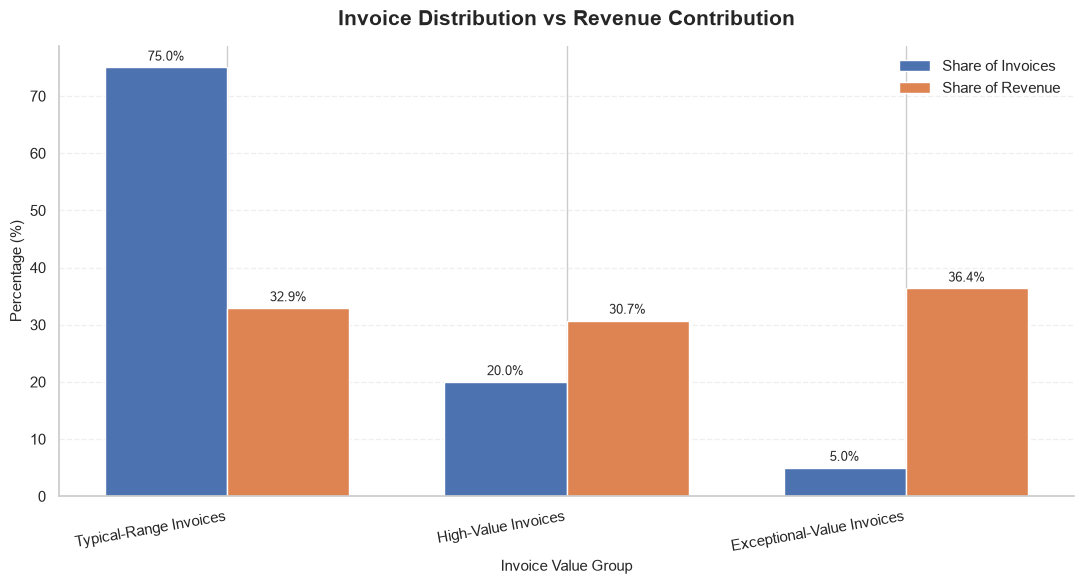

In [93]:
# Step 10.17: Compare Invoice Share vs Revenue Share

import matplotlib.pyplot as plt
import numpy as np

plot_data = invoice_value_summary.copy()

x = np.arange(len(plot_data))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

invoice_bars = ax.bar(
    x - width / 2,
    plot_data["Invoice_Share_Percent"],
    width,
    label="Share of Invoices"
)

revenue_bars = ax.bar(
    x + width / 2,
    plot_data["Revenue_Share_Percent"],
    width,
    label="Share of Revenue"
)

ax.set_title(
    "Invoice Distribution vs Revenue Contribution",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Invoice Value Group", fontsize=11)
ax.set_ylabel("Percentage (%)", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(
    plot_data["Revenue_Value_Group"].astype(str),
    rotation=10,
    ha="right"
)

ax.bar_label(
    invoice_bars,
    labels=[
        f"{value:.1f}%"
        for value in plot_data["Invoice_Share_Percent"]
    ],
    padding=3,
    fontsize=9
)

ax.bar_label(
    revenue_bars,
    labels=[
        f"{value:.1f}%"
        for value in plot_data["Revenue_Share_Percent"]
    ],
    padding=3,
    fontsize=9
)

ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [94]:
# Step 10.18: Validate Revenue Concentration Findings

summary = invoice_value_summary.copy()

summary["Revenue_Per_Invoice"] = (
    summary["Total_Revenue"] / summary["Invoice_Count"]
)

typical_revenue = summary.loc[
    summary["Revenue_Value_Group"] == "Typical-Range Invoices",
    "Revenue_Per_Invoice"
].iloc[0]

exceptional_revenue = summary.loc[
    summary["Revenue_Value_Group"] == "Exceptional-Value Invoices",
    "Revenue_Per_Invoice"
].iloc[0]

print("REVENUE CONCENTRATION VALIDATION")
print("=" * 60)

print(f"Total positive-revenue invoices: {summary['Invoice_Count'].sum():,}")
print(f"Total positive-invoice revenue: £{summary['Total_Revenue'].sum():,.2f}")

print(
    "Exceptional group invoice share:",
    f"{summary.loc[2, 'Invoice_Share_Percent']:.2f}%"
)

print(
    "Exceptional group revenue share:",
    f"{summary.loc[2, 'Revenue_Share_Percent']:.2f}%"
)

print(
    "Exceptional-to-typical average revenue multiple:",
    f"{exceptional_revenue / typical_revenue:.2f}x"
)

print("\nVALIDATION")
print("=" * 40)

print(
    "Invoice counts reconcile:",
    summary["Invoice_Count"].sum() == len(positive_revenue_invoices)
)

print(
    "Revenue totals reconcile:",
    abs(
        summary["Total_Revenue"].sum()
        - positive_revenue_invoices["Net_Line_Revenue"].sum()
    ) < 0.01
)

REVENUE CONCENTRATION VALIDATION
Total positive-revenue invoices: 40,078
Total positive-invoice revenue: £20,534,115.49
Exceptional group invoice share: 5.00%
Exceptional group revenue share: 36.35%
Exceptional-to-typical average revenue multiple: 16.57x

VALIDATION
Invoice counts reconcile: True
Revenue totals reconcile: True


In [95]:
# Step 10.19: Validate Monthly Revenue Analysis

print("MONTHLY REVENUE DATA VALIDATION")
print("=" * 60)

# Check monthly data structure
print("Monthly revenue DataFrame shape:", monthly_revenue.shape)
print("Total monthly periods:", monthly_revenue["Year_Month"].nunique())

# Calculate total revenue using the correct column name
monthly_total_revenue = monthly_revenue["Total_Revenue"].sum()
dataset_total_revenue = df_clean["Revenue"].sum()

print(f"\nTotal revenue from monthly analysis: £{monthly_total_revenue:,.2f}")
print(f"Total revenue from original dataset: £{dataset_total_revenue:,.2f}")
print(
    f"Difference: "
    f"£{abs(monthly_total_revenue - dataset_total_revenue):,.6f}"
)

# Validation checks
print("\nVALIDATION CHECKS")
print("=" * 60)

print(
    "Monthly periods match expected count:",
    monthly_revenue["Year_Month"].nunique() == 25
)

print(
    "Monthly revenue reconciles with original dataset:",
    abs(monthly_total_revenue - dataset_total_revenue) < 0.01
)

print(
    "Monthly revenue contains no missing values:",
    monthly_revenue["Total_Revenue"].notna().all()
)

print(
    "Monthly periods are unique:",
    monthly_revenue["Year_Month"].is_unique
)

MONTHLY REVENUE DATA VALIDATION
Monthly revenue DataFrame shape: (25, 6)
Total monthly periods: 25

Total revenue from monthly analysis: £18,909,762.12
Total revenue from original dataset: £18,909,762.12
Difference: £0.000000

VALIDATION CHECKS
Monthly periods match expected count: True
Monthly revenue reconciles with original dataset: True
Monthly revenue contains no missing values: True
Monthly periods are unique: True


MONTHLY NET REVENUE TREND
Highest-revenue complete month: 2011-11 — £1,461,756.25
Lowest-revenue complete month: 2011-04 — £493,207.12
Average monthly net revenue (complete months): £769,836.50
Median monthly net revenue (complete months): £682,973.79


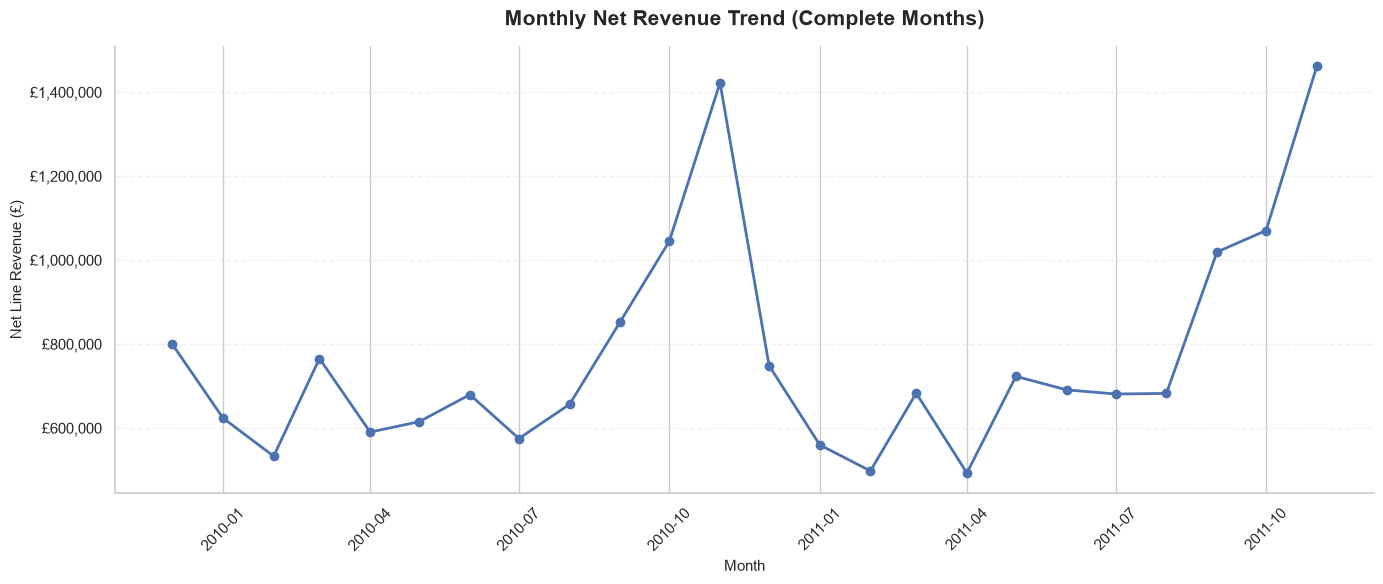


VALIDATION
Complete months analysed: 24
Incomplete December 2011 excluded: True
Original monthly DataFrame unchanged: True


In [96]:
# Step 10.20: Monthly Net Revenue Trend Analysis

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Work on a copy; preserve the original DataFrame
monthly_trend = monthly_revenue.copy()

# Convert Year_Month into a datetime field for chronological plotting
monthly_trend["Month_Date"] = pd.to_datetime(
    monthly_trend["Year_Month"].astype(str),
    format="%Y-%m"
)

monthly_trend = monthly_trend.sort_values("Month_Date").reset_index(drop=True)

# Exclude incomplete December 2011 from full-month comparisons
complete_months = monthly_trend[
    monthly_trend["Year_Month"].astype(str) != "2011-12"
].copy()

# Identify highest and lowest revenue among complete months
highest_month = complete_months.loc[
    complete_months["Total_Revenue"].idxmax()
]

lowest_month = complete_months.loc[
    complete_months["Total_Revenue"].idxmin()
]

print("MONTHLY NET REVENUE TREND")
print("=" * 60)

print(
    f"Highest-revenue complete month: "
    f"{highest_month['Year_Month']} — "
    f"£{highest_month['Total_Revenue']:,.2f}"
)

print(
    f"Lowest-revenue complete month: "
    f"{lowest_month['Year_Month']} — "
    f"£{lowest_month['Total_Revenue']:,.2f}"
)

print(
    f"Average monthly net revenue (complete months): "
    f"£{complete_months['Total_Revenue'].mean():,.2f}"
)

print(
    f"Median monthly net revenue (complete months): "
    f"£{complete_months['Total_Revenue'].median():,.2f}"
)

# Plot monthly revenue
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    complete_months["Month_Date"],
    complete_months["Total_Revenue"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Monthly Net Revenue Trend (Complete Months)",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Net Line Revenue (£)", fontsize=11)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"£{value:,.0f}")
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Validation
print("\nVALIDATION")
print("=" * 40)

print(
    "Complete months analysed:",
    len(complete_months)
)

print(
    "Incomplete December 2011 excluded:",
    "2011-12" not in complete_months["Year_Month"].astype(str).values
)

print(
    "Original monthly DataFrame unchanged:",
    len(monthly_revenue) == 25
)

In [97]:
# Step 10.21: Month-over-Month Revenue Growth Analysis

# Reuse the existing monthly trend DataFrame
mom_analysis = monthly_trend[
    monthly_trend["Year_Month"].astype(str) != "2011-12"
].copy()

mom_analysis = mom_analysis.sort_values("Month_Date").reset_index(drop=True)

# Calculate absolute and percentage change from the previous month
mom_analysis["Revenue_Change"] = (
    mom_analysis["Total_Revenue"].diff()
)

mom_analysis["MoM_Growth_Percent"] = (
    mom_analysis["Total_Revenue"].pct_change() * 100
)

# Display the monthly results
print("MONTH-OVER-MONTH REVENUE GROWTH")
print("=" * 75)

display(
    mom_analysis[
        [
            "Year_Month",
            "Total_Revenue",
            "Revenue_Change",
            "MoM_Growth_Percent"
        ]
    ].round(2)
)

# Identify strongest increase and decline, excluding the first month
growth_data = mom_analysis.dropna(
    subset=["MoM_Growth_Percent"]
)

strongest_growth = growth_data.loc[
    growth_data["MoM_Growth_Percent"].idxmax()
]

largest_decline = growth_data.loc[
    growth_data["MoM_Growth_Percent"].idxmin()
]

print("\nKEY FINDINGS")
print("=" * 50)

print(
    f"Strongest monthly growth: {strongest_growth['Year_Month']} "
    f"({strongest_growth['MoM_Growth_Percent']:.2f}%)"
)

print(
    f"Largest monthly decline: {largest_decline['Year_Month']} "
    f"({largest_decline['MoM_Growth_Percent']:.2f}%)"
)

# Validation
print("\nVALIDATION")
print("=" * 40)

print("Complete months included:", len(mom_analysis))

print(
    "December 2011 excluded:",
    "2011-12" not in mom_analysis["Year_Month"].astype(str).values
)

print(
    "Original monthly data unchanged:",
    len(monthly_revenue) == 25
)

MONTH-OVER-MONTH REVENUE GROWTH


,Year_Month,Total_Revenue,Revenue_Change,MoM_Growth_Percent
0,2009-12,799847.11,NaN,NaN
1,2010-01,624032.89,-175814.22,-21.98
2,2010-02,533091.43,-90941.47,-14.57
3,2010-03,765848.76,232757.34,43.66
4,2010-04,590580.43,-175268.33,-22.89
5,2010-05,615322.83,24742.40,4.19
6,2010-06,679786.61,64463.78,10.48
7,2010-07,575236.36,-104550.25,-15.38
8,2010-08,656776.34,81539.98,14.18
9,2010-09,853650.43,196874.09,29.98



KEY FINDINGS
Strongest monthly growth: 2011-09 (49.37%)
Largest monthly decline: 2010-12 (-47.35%)

VALIDATION
Complete months included: 24
December 2011 excluded: True
Original monthly data unchanged: True


In [98]:
# Step 10.22: Compare Revenue Growth with Invoice Growth

# Reuse the existing monthly trend data
growth_comparison = monthly_trend[
    monthly_trend["Year_Month"].astype(str) != "2011-12"
].copy()

growth_comparison = (
    growth_comparison
    .sort_values("Month_Date")
    .reset_index(drop=True)
)

# Calculate month-over-month growth rates
growth_comparison["Revenue_Growth_Percent"] = (
    growth_comparison["Total_Revenue"].pct_change() * 100
)

growth_comparison["Invoice_Growth_Percent"] = (
    growth_comparison["Unique_Invoices"].pct_change() * 100
)

# First month has no previous month for comparison
growth_rates = growth_comparison.dropna(
    subset=["Revenue_Growth_Percent", "Invoice_Growth_Percent"]
).copy()

# Correlation between the two monthly growth rates
growth_correlation = growth_rates[
    ["Revenue_Growth_Percent", "Invoice_Growth_Percent"]
].corr().iloc[0, 1]

print("REVENUE GROWTH VS INVOICE GROWTH")
print("=" * 65)

display(
    growth_rates[
        [
            "Year_Month",
            "Revenue_Growth_Percent",
            "Invoice_Growth_Percent"
        ]
    ].round(2)
)

print("\nSUMMARY")
print("=" * 45)

print(f"Months compared: {len(growth_rates)}")
print(f"Correlation between growth rates: {growth_correlation:.3f}")

print("\nINTERPRETATION GUIDE")
print("Correlation near +1: growth rates tend to move together.")
print("Correlation near  0: little linear relationship.")
print("Correlation near -1: growth rates tend to move oppositely.")

print("\nVALIDATION")
print("=" * 40)

print(
    "December 2011 excluded:",
    "2011-12" not in growth_comparison["Year_Month"].astype(str).values
)

print(
    "Growth rates contain no missing values:",
    growth_rates[
        ["Revenue_Growth_Percent", "Invoice_Growth_Percent"]
    ].notna().all().all()
)

print(
    "Original monthly data unchanged:",
    len(monthly_revenue) == 25
)

REVENUE GROWTH VS INVOICE GROWTH


,Year_Month,Revenue_Growth_Percent,Invoice_Growth_Percent
1,2010-01,-21.98,-29.91
2,2010-02,-14.57,20.58
3,2010-03,43.66,20.21
4,2010-04,-22.89,-20.07
5,2010-05,4.19,27.80
6,2010-06,10.48,-8.35
7,2010-07,-15.38,-8.98
8,2010-08,14.18,-6.94
9,2010-09,29.98,26.53
10,2010-10,22.44,24.84



SUMMARY
Months compared: 23
Correlation between growth rates: 0.850

INTERPRETATION GUIDE
Correlation near +1: growth rates tend to move together.
Correlation near  0: little linear relationship.
Correlation near -1: growth rates tend to move oppositely.

VALIDATION
December 2011 excluded: True
Growth rates contain no missing values: True
Original monthly data unchanged: True


MONTHLY AVERAGE REVENUE PER INVOICE


,Year_Month,Unique_Invoices,Total_Revenue,Revenue_Per_Invoice,Revenue_Per_Invoice_Growth_Percent
0,2009-12,2330,799847.11,343.28,NaN
1,2010-01,1633,624032.89,382.14,11.32
2,2010-02,1969,533091.43,270.74,-29.15
3,2010-03,2367,765848.76,323.55,19.51
4,2010-04,1892,590580.43,312.15,-3.53
5,2010-05,2418,615322.83,254.48,-18.48
6,2010-06,2216,679786.61,306.76,20.55
7,2010-07,2017,575236.36,285.19,-7.03
8,2010-08,1877,656776.34,349.91,22.69
9,2010-09,2375,853650.43,359.43,2.72



KEY FINDINGS
Highest revenue per invoice: 2011-09 — £438.20
Lowest revenue per invoice: 2010-05 — £254.48
Average across complete months: £348.05


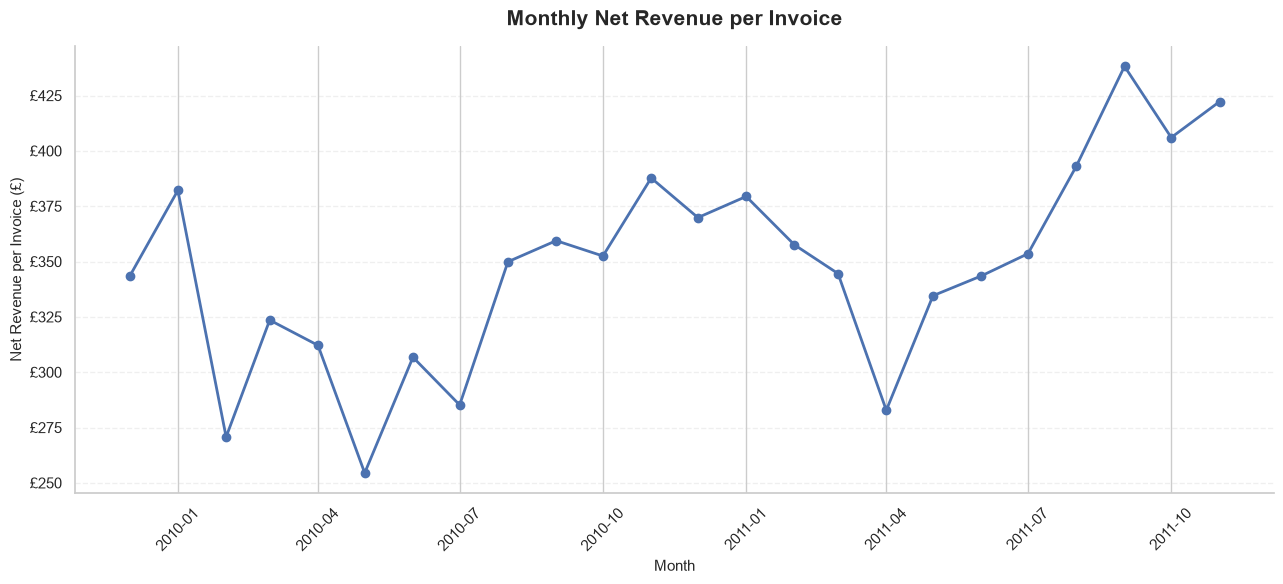


VALIDATION
Complete months analysed: 24
All invoice counts are positive: True
Revenue per invoice calculation is valid: True
Original monthly data unchanged: True


In [99]:
# Step 10.23: Monthly Average Revenue per Invoice

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Reuse existing monthly analysis
monthly_invoice_value = monthly_revenue.copy()

# Exclude incomplete December 2011
monthly_invoice_value = monthly_invoice_value[
    monthly_invoice_value["Year_Month"].astype(str) != "2011-12"
].copy()

monthly_invoice_value["Month_Date"] = pd.to_datetime(
    monthly_invoice_value["Year_Month"].astype(str),
    format="%Y-%m"
)

monthly_invoice_value = (
    monthly_invoice_value
    .sort_values("Month_Date")
    .reset_index(drop=True)
)

# Calculate average net line revenue per invoice
monthly_invoice_value["Revenue_Per_Invoice"] = (
    monthly_invoice_value["Total_Revenue"]
    / monthly_invoice_value["Unique_Invoices"]
)

# Calculate month-over-month change
monthly_invoice_value["Revenue_Per_Invoice_Growth_Percent"] = (
    monthly_invoice_value["Revenue_Per_Invoice"].pct_change() * 100
)

print("MONTHLY AVERAGE REVENUE PER INVOICE")
print("=" * 65)

display(
    monthly_invoice_value[
        [
            "Year_Month",
            "Unique_Invoices",
            "Total_Revenue",
            "Revenue_Per_Invoice",
            "Revenue_Per_Invoice_Growth_Percent"
        ]
    ].round(2)
)

# Identify highest and lowest average revenue per invoice
highest_avg = monthly_invoice_value.loc[
    monthly_invoice_value["Revenue_Per_Invoice"].idxmax()
]

lowest_avg = monthly_invoice_value.loc[
    monthly_invoice_value["Revenue_Per_Invoice"].idxmin()
]

print("\nKEY FINDINGS")
print("=" * 50)

print(
    f"Highest revenue per invoice: {highest_avg['Year_Month']} — "
    f"£{highest_avg['Revenue_Per_Invoice']:,.2f}"
)

print(
    f"Lowest revenue per invoice: {lowest_avg['Year_Month']} — "
    f"£{lowest_avg['Revenue_Per_Invoice']:,.2f}"
)

print(
    f"Average across complete months: "
    f"£{monthly_invoice_value['Revenue_Per_Invoice'].mean():,.2f}"
)

# Plot the trend
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    monthly_invoice_value["Month_Date"],
    monthly_invoice_value["Revenue_Per_Invoice"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Monthly Net Revenue per Invoice",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Net Revenue per Invoice (£)", fontsize=11)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"£{value:,.0f}")
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nVALIDATION")
print("=" * 40)

print("Complete months analysed:", len(monthly_invoice_value))

print(
    "All invoice counts are positive:",
    monthly_invoice_value["Unique_Invoices"].gt(0).all()
)

print(
    "Revenue per invoice calculation is valid:",
    (
        monthly_invoice_value["Revenue_Per_Invoice"]
        - monthly_invoice_value["Total_Revenue"]
        / monthly_invoice_value["Unique_Invoices"]
    ).abs().lt(0.000001).all()
)

print(
    "Original monthly data unchanged:",
    len(monthly_revenue) == 25
)

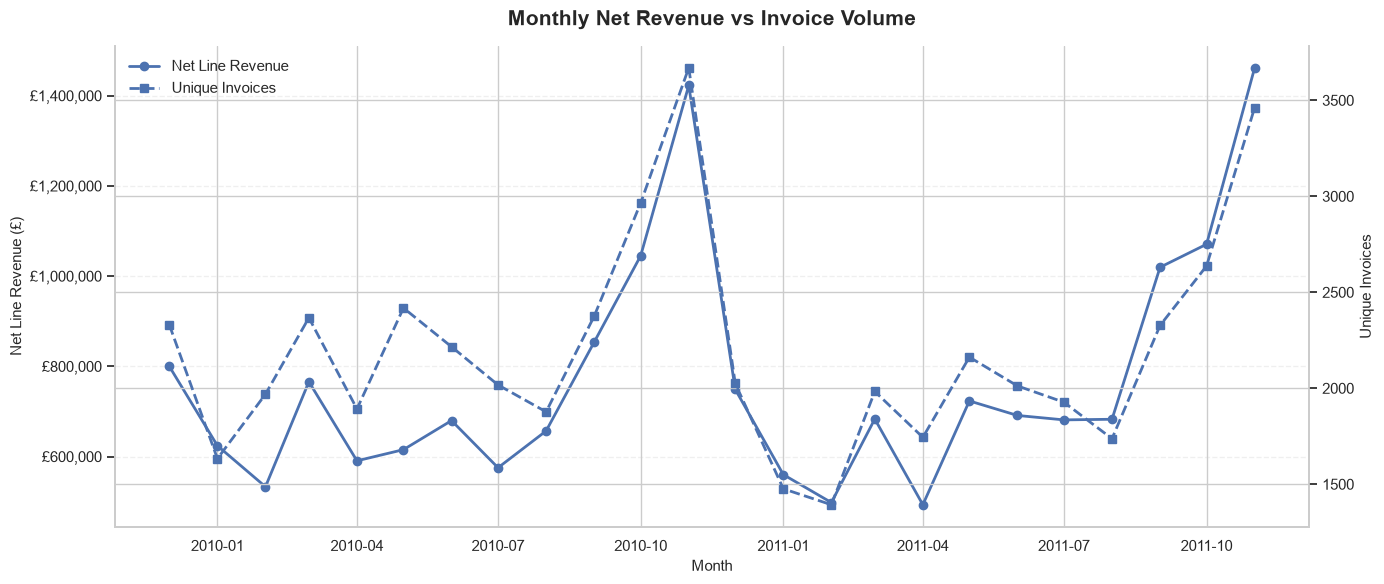

MONTHLY REVENUE VS INVOICE VOLUME
Correlation: 0.920
Complete months analysed: 24

VALIDATION
December 2011 excluded: True
Invoice counts are positive: True
Original monthly dataset unchanged: True


In [100]:
# Step 10.24: Compare Monthly Revenue and Invoice Volume

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Reuse existing monthly analysis
monthly_comparison = monthly_trend[
    monthly_trend["Year_Month"].astype(str) != "2011-12"
].copy()

monthly_comparison = (
    monthly_comparison
    .sort_values("Month_Date")
    .reset_index(drop=True)
)

fig, ax1 = plt.subplots(figsize=(14, 6))

# Revenue line
line1 = ax1.plot(
    monthly_comparison["Month_Date"],
    monthly_comparison["Total_Revenue"],
    marker="o",
    linewidth=2,
    label="Net Line Revenue"
)

ax1.set_xlabel("Month", fontsize=11)
ax1.set_ylabel("Net Line Revenue (£)", fontsize=11)

ax1.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"£{value:,.0f}")
)

# Invoice volume on the secondary axis
ax2 = ax1.twinx()

line2 = ax2.plot(
    monthly_comparison["Month_Date"],
    monthly_comparison["Unique_Invoices"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Unique Invoices"
)

ax2.set_ylabel("Unique Invoices", fontsize=11)

# Combined legend
lines = line1 + line2
labels = [line.get_label() for line in lines]

ax1.legend(
    lines,
    labels,
    loc="upper left",
    frameon=False
)

ax1.set_title(
    "Monthly Net Revenue vs Invoice Volume",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

ax1.grid(axis="y", linestyle="--", alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Numerical correlation between monthly revenue and invoice count
correlation = monthly_comparison[
    ["Total_Revenue", "Unique_Invoices"]
].corr().iloc[0, 1]

print("MONTHLY REVENUE VS INVOICE VOLUME")
print("=" * 55)

print(f"Correlation: {correlation:.3f}")
print("Complete months analysed:", len(monthly_comparison))

print("\nVALIDATION")
print("=" * 40)

print(
    "December 2011 excluded:",
    "2011-12" not in monthly_comparison["Year_Month"].astype(str).values
)

print(
    "Invoice counts are positive:",
    monthly_comparison["Unique_Invoices"].gt(0).all()
)

print(
    "Original monthly dataset unchanged:",
    len(monthly_revenue) == 25
)

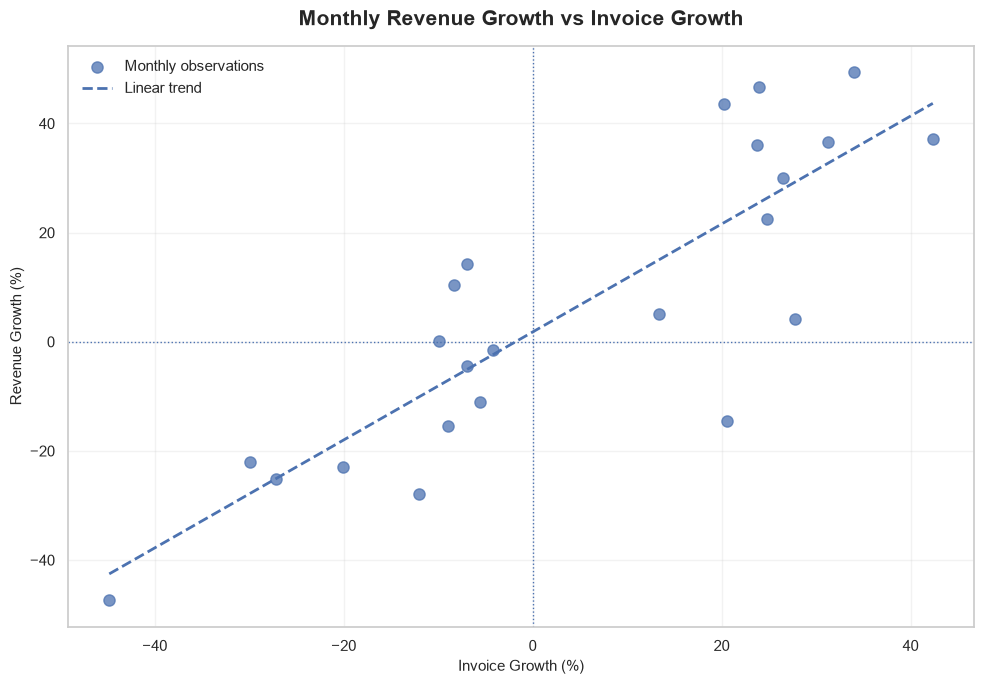

GROWTH RATE RELATIONSHIP
Monthly comparisons: 23
Pearson correlation: 0.850
Months with both growth rates positive: 10
Months with both growth rates negative: 9
Months with opposite growth directions: 4

VALIDATION
Growth data contains no missing values: True
Original monthly dataset unchanged: True


In [101]:
# Step 10.25: Visualise Revenue Growth vs Invoice Growth

import matplotlib.pyplot as plt
import numpy as np

# Reuse the existing growth comparison data
scatter_data = growth_rates.copy()

x = scatter_data["Invoice_Growth_Percent"]
y = scatter_data["Revenue_Growth_Percent"]

# Correlation between the two growth rates
growth_correlation = x.corr(y)

# Fit a linear trend line for visual guidance
slope, intercept = np.polyfit(x, y, 1)
trend_x = np.linspace(x.min(), x.max(), 100)
trend_y = slope * trend_x + intercept

fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(
    x,
    y,
    alpha=0.75,
    s=65,
    label="Monthly observations"
)

ax.plot(
    trend_x,
    trend_y,
    linestyle="--",
    linewidth=2,
    label="Linear trend"
)

# Reference lines at zero growth
ax.axhline(0, linestyle=":", linewidth=1)
ax.axvline(0, linestyle=":", linewidth=1)

ax.set_title(
    "Monthly Revenue Growth vs Invoice Growth",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Invoice Growth (%)", fontsize=11)
ax.set_ylabel("Revenue Growth (%)", fontsize=11)

ax.legend(frameon=False)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("GROWTH RATE RELATIONSHIP")
print("=" * 50)

print(f"Monthly comparisons: {len(scatter_data)}")
print(f"Pearson correlation: {growth_correlation:.3f}")

print(
    "Months with both growth rates positive:",
    int(((x > 0) & (y > 0)).sum())
)

print(
    "Months with both growth rates negative:",
    int(((x < 0) & (y < 0)).sum())
)

print(
    "Months with opposite growth directions:",
    int(((x * y) < 0).sum())
)

print("\nVALIDATION")
print("=" * 40)

print(
    "Growth data contains no missing values:",
    scatter_data[
        ["Invoice_Growth_Percent", "Revenue_Growth_Percent"]
    ].notna().all().all()
)

print(
    "Original monthly dataset unchanged:",
    len(monthly_revenue) == 25
)

In [102]:
# Step 10.26: Investigate Divergence Between Revenue and Invoice Growth

divergent_months = growth_rates[
    (
        (growth_rates["Revenue_Growth_Percent"] > 0)
        & (growth_rates["Invoice_Growth_Percent"] < 0)
    )
    |
    (
        (growth_rates["Revenue_Growth_Percent"] < 0)
        & (growth_rates["Invoice_Growth_Percent"] > 0)
    )
].copy()

# Calculate revenue per invoice for context
divergent_months["Revenue_Per_Invoice"] = (
    divergent_months["Total_Revenue"]
    / divergent_months["Unique_Invoices"]
)

print("MONTHS WITH DIVERGING REVENUE AND INVOICE GROWTH")
print("=" * 75)

display(
    divergent_months[
        [
            "Year_Month",
            "Total_Revenue",
            "Unique_Invoices",
            "Revenue_Per_Invoice",
            "Revenue_Growth_Percent",
            "Invoice_Growth_Percent"
        ]
    ].round(2)
)

print("\nSUMMARY")
print("=" * 50)

print("Divergent months identified:", len(divergent_months))

print(
    "Revenue increased while invoice count declined:",
    int(
        (
            (divergent_months["Revenue_Growth_Percent"] > 0)
            & (divergent_months["Invoice_Growth_Percent"] < 0)
        ).sum()
    )
)

print(
    "Revenue declined while invoice count increased:",
    int(
        (
            (divergent_months["Revenue_Growth_Percent"] < 0)
            & (divergent_months["Invoice_Growth_Percent"] > 0)
        ).sum()
    )
)

print("\nVALIDATION")
print("=" * 40)

print(
    "All selected months have opposite growth directions:",
    (
        divergent_months["Revenue_Growth_Percent"]
        * divergent_months["Invoice_Growth_Percent"]
    ).lt(0).all()
)

print(
    "Original monthly dataset unchanged:",
    len(monthly_revenue) == 25
)

MONTHS WITH DIVERGING REVENUE AND INVOICE GROWTH


,Year_Month,Total_Revenue,Unique_Invoices,Revenue_Per_Invoice,Revenue_Growth_Percent,Invoice_Growth_Percent
2,2010-02,533091.43,1969,270.74,-14.57,20.58
6,2010-06,679786.61,2216,306.76,10.48,-8.35
8,2010-08,656776.34,1877,349.91,14.18,-6.94
20,2011-08,682680.51,1737,393.02,0.20,-9.86



SUMMARY
Divergent months identified: 4
Revenue increased while invoice count declined: 3
Revenue declined while invoice count increased: 1

VALIDATION
All selected months have opposite growth directions: True
Original monthly dataset unchanged: True


In [103]:
# Step 10.27: Detailed Analysis of Divergent Months

# Preserve the existing analysis and create a display copy
divergence_detail = divergent_months.copy()

# Calculate month-over-month absolute changes
divergence_detail["Revenue_Change"] = (
    divergence_detail["Total_Revenue"]
    - divergence_detail["Total_Revenue"].shift(1)
)

# Show the relevant metrics for the four identified months
columns_to_display = [
    "Year_Month",
    "Total_Revenue",
    "Unique_Invoices",
    "Revenue_Per_Invoice",
    "Revenue_Growth_Percent",
    "Invoice_Growth_Percent"
]

print("DETAILED DIVERGENT-MONTH ANALYSIS")
print("=" * 75)

display(
    divergence_detail[columns_to_display]
    .sort_values("Year_Month")
    .round(2)
)

print("\nVALIDATION")
print("=" * 40)

print("Divergent months:", len(divergence_detail))

print(
    "Revenue per invoice calculated correctly:",
    (
        divergence_detail["Revenue_Per_Invoice"]
        - divergence_detail["Total_Revenue"]
        / divergence_detail["Unique_Invoices"]
    ).abs().lt(0.000001).all()
)

print(
    "Original monthly dataset unchanged:",
    len(monthly_revenue) == 25
)

DETAILED DIVERGENT-MONTH ANALYSIS


,Year_Month,Total_Revenue,Unique_Invoices,Revenue_Per_Invoice,Revenue_Growth_Percent,Invoice_Growth_Percent
2,2010-02,533091.43,1969,270.74,-14.57,20.58
6,2010-06,679786.61,2216,306.76,10.48,-8.35
8,2010-08,656776.34,1877,349.91,14.18,-6.94
20,2011-08,682680.51,1737,393.02,0.20,-9.86



VALIDATION
Divergent months: 4
Revenue per invoice calculated correctly: True
Original monthly dataset unchanged: True


In [104]:
# Step 10.27A: Display Divergent Month Details

print("DIVERGENT MONTHS — DETAILED RESULTS")
print("=" * 75)

display(
    divergence_detail[
        [
            "Year_Month",
            "Total_Revenue",
            "Unique_Invoices",
            "Revenue_Per_Invoice",
            "Revenue_Growth_Percent",
            "Invoice_Growth_Percent"
        ]
    ]
    .sort_values("Year_Month")
    .round(2)
    .reset_index(drop=True)
)

DIVERGENT MONTHS — DETAILED RESULTS


,Year_Month,Total_Revenue,Unique_Invoices,Revenue_Per_Invoice,Revenue_Growth_Percent,Invoice_Growth_Percent
0,2010-02,533091.43,1969,270.74,-14.57,20.58
1,2010-06,679786.61,2216,306.76,10.48,-8.35
2,2010-08,656776.34,1877,349.91,14.18,-6.94
3,2011-08,682680.51,1737,393.02,0.20,-9.86


MONTHLY REVENUE COMPOSITION


,Year_Month,Positive_Revenue,Negative_Revenue,Total_Revenue,Negative_Revenue_Impact_Percent
0,2009-12,825685.76,-25838.65,799847.11,3.13
1,2010-01,652708.50,-28675.61,624032.89,4.39
2,2010-02,553713.31,-20621.88,533091.43,3.72
3,2010-03,833570.13,-67721.37,765848.76,8.12
4,2010-04,681528.99,-90948.56,590580.43,13.34
5,2010-05,659858.86,-44536.03,615322.83,6.75
6,2010-06,752270.14,-72483.53,679786.61,9.64
7,2010-07,650712.94,-75476.58,575236.36,11.60
8,2010-08,697274.91,-40498.57,656776.34,5.81
9,2010-09,924333.01,-70682.58,853650.43,7.65



KEY FINDINGS
Highest negative-revenue impact: 2011-01 (19.00%)
Lowest negative-revenue impact: 2009-12 (3.13%)


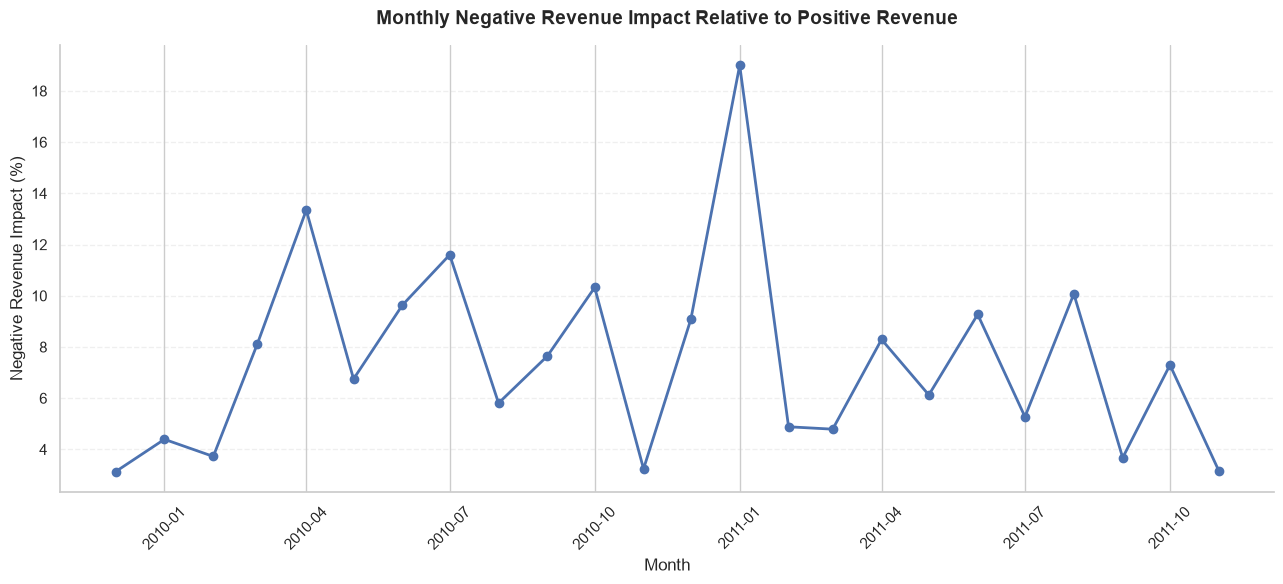


VALIDATION
Complete months analysed: 24
Monthly revenue reconciles: True
Original monthly dataset unchanged: True


In [105]:
# Step 10.28: Monthly Positive vs Negative Revenue Analysis

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Reuse existing monthly data
revenue_composition = monthly_revenue.copy()

# Exclude incomplete December 2011 for full-month comparisons
revenue_composition = revenue_composition[
    revenue_composition["Year_Month"].astype(str) != "2011-12"
].copy()

revenue_composition["Month_Date"] = pd.to_datetime(
    revenue_composition["Year_Month"].astype(str),
    format="%Y-%m"
)

revenue_composition = (
    revenue_composition
    .sort_values("Month_Date")
    .reset_index(drop=True)
)

# Calculate negative revenue as a percentage of positive revenue
revenue_composition["Negative_Revenue_Impact_Percent"] = (
    revenue_composition["Negative_Revenue"].abs()
    / revenue_composition["Positive_Revenue"]
    * 100
)

# Verify net revenue reconciliation for each month
revenue_composition["Calculated_Net_Revenue"] = (
    revenue_composition["Positive_Revenue"]
    + revenue_composition["Negative_Revenue"]
)

print("MONTHLY REVENUE COMPOSITION")
print("=" * 75)

display(
    revenue_composition[
        [
            "Year_Month",
            "Positive_Revenue",
            "Negative_Revenue",
            "Total_Revenue",
            "Negative_Revenue_Impact_Percent"
        ]
    ].round(2)
)

# Identify months with the highest negative impact
highest_impact = revenue_composition.loc[
    revenue_composition["Negative_Revenue_Impact_Percent"].idxmax()
]

lowest_impact = revenue_composition.loc[
    revenue_composition["Negative_Revenue_Impact_Percent"].idxmin()
]

print("\nKEY FINDINGS")
print("=" * 50)

print(
    f"Highest negative-revenue impact: {highest_impact['Year_Month']} "
    f"({highest_impact['Negative_Revenue_Impact_Percent']:.2f}%)"
)

print(
    f"Lowest negative-revenue impact: {lowest_impact['Year_Month']} "
    f"({lowest_impact['Negative_Revenue_Impact_Percent']:.2f}%)"
)

# Plot the negative-revenue impact
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    revenue_composition["Month_Date"],
    revenue_composition["Negative_Revenue_Impact_Percent"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Monthly Negative Revenue Impact Relative to Positive Revenue",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Month")
ax.set_ylabel("Negative Revenue Impact (%)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nVALIDATION")
print("=" * 40)

print("Complete months analysed:", len(revenue_composition))

print(
    "Monthly revenue reconciles:",
    (
        revenue_composition["Calculated_Net_Revenue"]
        - revenue_composition["Total_Revenue"]
    ).abs().lt(0.01).all()
)

print(
    "Original monthly dataset unchanged:",
    len(monthly_revenue) == 25
)

In [106]:
# Step 10.29: Investigate Negative-Revenue Transactions in January 2011

# Preserve the original dataset
negative_transactions = df_clean.loc[
    df_clean["Revenue"] < 0
].copy()

# Create a month identifier
negative_transactions["Year_Month"] = (
    negative_transactions["InvoiceDate"].dt.to_period("M").astype(str)
)

# Filter January 2011 negative-revenue transactions
jan_2011_negative = negative_transactions.loc[
    negative_transactions["Year_Month"] == "2011-01"
].copy()

print("JANUARY 2011 — NEGATIVE-REVENUE TRANSACTIONS")
print("=" * 65)

print("Negative-revenue transaction lines:", len(jan_2011_negative))
print("Unique invoices:", jan_2011_negative["Invoice"].nunique())
print("Unique stock codes:", jan_2011_negative["StockCode"].nunique())
print(
    "Total negative revenue: £{:,.2f}".format(
        jan_2011_negative["Revenue"].sum()
    )
)

print("\nTOP COUNTRIES BY NEGATIVE REVENUE")
print("=" * 65)

country_negative_summary = (
    jan_2011_negative.groupby("Country")
    .agg(
        Transaction_Lines=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique"),
        Negative_Revenue=("Revenue", "sum")
    )
    .sort_values("Negative_Revenue")
    .reset_index()
)

display(country_negative_summary.head(10).round(2))

print("\nTOP INVOICES BY NEGATIVE REVENUE")
print("=" * 65)

invoice_negative_summary = (
    jan_2011_negative.groupby("Invoice")
    .agg(
        Transaction_Lines=("Revenue", "size"),
        Negative_Revenue=("Revenue", "sum"),
        Country=("Country", "first"),
        Customer_ID=("Customer ID", "first")
    )
    .sort_values("Negative_Revenue")
    .reset_index()
)

display(invoice_negative_summary.head(10).round(2))

print("\nVALIDATION")
print("=" * 40)

print(
    "All selected transactions have negative revenue:",
    jan_2011_negative["Revenue"].lt(0).all()
)

print(
    "Selected transactions belong to January 2011:",
    jan_2011_negative["Year_Month"].eq("2011-01").all()
)

print(
    "Original dataset row count unchanged:",
    len(df_clean) == 1_044_848
)

JANUARY 2011 — NEGATIVE-REVENUE TRANSACTIONS
Negative-revenue transaction lines: 701
Unique invoices: 260
Unique stock codes: 443
Total negative revenue: £-131,364.30

TOP COUNTRIES BY NEGATIVE REVENUE


,Country,Transaction_Lines,Unique_Invoices,Negative_Revenue
0,United Kingdom,596,226,-126981.68
1,Spain,3,3,-2907.55
2,Germany,48,9,-459.41
3,EIRE,16,2,-247.67
4,France,15,10,-237.05
5,Bahrain,1,1,-205.74
6,Japan,4,1,-109.80
7,Portugal,4,1,-57.60
8,Belgium,5,3,-46.15
9,Italy,6,2,-41.15



TOP INVOICES BY NEGATIVE REVENUE


,Invoice,Transaction_Lines,Negative_Revenue,Country,Customer_ID
0,C541433,1,-77183.60,United Kingdom,12346.0
1,C540117,1,-16888.02,United Kingdom,NaN
2,C540118,1,-16453.71,United Kingdom,NaN
3,C542348,1,-1715.85,Spain,12539.0
4,C540417,21,-1520.11,United Kingdom,13680.0
5,C541651,1,-1283.80,United Kingdom,NaN
6,C542426,35,-1241.43,United Kingdom,14146.0
7,C540271,1,-1126.00,Spain,12503.0
8,C541653,1,-1050.15,United Kingdom,NaN
9,C540307,16,-855.76,United Kingdom,15823.0



VALIDATION
All selected transactions have negative revenue: True
Selected transactions belong to January 2011: True
Original dataset row count unchanged: True


In [107]:
# Step 10.29A: Display Existing January 2011 Investigation Results

print("JANUARY 2011 NEGATIVE-REVENUE SUMMARY")
print("=" * 60)

print("Transaction lines:", len(jan_2011_negative))
print("Unique invoices:", jan_2011_negative["Invoice"].nunique())
print("Unique stock codes:", jan_2011_negative["StockCode"].nunique())
print(f"Total negative revenue: £{jan_2011_negative['Revenue'].sum():,.2f}")

print("\nTOP 10 COUNTRIES BY NEGATIVE REVENUE")
print("=" * 60)
display(country_negative_summary.head(10).round(2))

print("\nTOP 10 INVOICES BY NEGATIVE REVENUE")
print("=" * 60)
display(invoice_negative_summary.head(10).round(2))

JANUARY 2011 NEGATIVE-REVENUE SUMMARY
Transaction lines: 701
Unique invoices: 260
Unique stock codes: 443
Total negative revenue: £-131,364.30

TOP 10 COUNTRIES BY NEGATIVE REVENUE


,Country,Transaction_Lines,Unique_Invoices,Negative_Revenue
0,United Kingdom,596,226,-126981.68
1,Spain,3,3,-2907.55
2,Germany,48,9,-459.41
3,EIRE,16,2,-247.67
4,France,15,10,-237.05
5,Bahrain,1,1,-205.74
6,Japan,4,1,-109.80
7,Portugal,4,1,-57.60
8,Belgium,5,3,-46.15
9,Italy,6,2,-41.15



TOP 10 INVOICES BY NEGATIVE REVENUE


,Invoice,Transaction_Lines,Negative_Revenue,Country,Customer_ID
0,C541433,1,-77183.60,United Kingdom,12346.0
1,C540117,1,-16888.02,United Kingdom,NaN
2,C540118,1,-16453.71,United Kingdom,NaN
3,C542348,1,-1715.85,Spain,12539.0
4,C540417,21,-1520.11,United Kingdom,13680.0
5,C541651,1,-1283.80,United Kingdom,NaN
6,C542426,35,-1241.43,United Kingdom,14146.0
7,C540271,1,-1126.00,Spain,12503.0
8,C541653,1,-1050.15,United Kingdom,NaN
9,C540307,16,-855.76,United Kingdom,15823.0


In [108]:
# Step 10.30: Inspect the Largest Negative-Revenue Invoices

target_invoices = ["C541433", "C540117", "C540118"]

# Extract the selected invoices from the working dataset
target_invoice_details = df_clean.loc[
    df_clean["Invoice"].astype(str).isin(target_invoices),
    [
        "Invoice",
        "InvoiceDate",
        "StockCode",
        "Description",
        "Quantity",
        "Price",
        "Customer ID",
        "Country",
        "Revenue"
    ]
].copy()

print("SELECTED NEGATIVE-REVENUE INVOICE DETAILS")
print("=" * 80)

display(
    target_invoice_details
    .sort_values(["Invoice", "Revenue"])
    .reset_index(drop=True)
)

# Summarise each invoice
print("\nINVOICE SUMMARY")
print("=" * 80)

target_invoice_summary = (
    target_invoice_details.groupby("Invoice")
    .agg(
        Transaction_Lines=("Invoice", "size"),
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Unique_Stock_Codes=("StockCode", "nunique"),
        Country=("Country", "first"),
        Customer_ID=("Customer ID", "first")
    )
    .reset_index()
)

display(target_invoice_summary.round(2))

# Check whether the same StockCode appears in positive-revenue records
target_stock_codes = target_invoice_details["StockCode"].unique()

positive_matches = df_clean.loc[
    df_clean["StockCode"].isin(target_stock_codes)
    & (df_clean["Revenue"] > 0),
    [
        "Invoice",
        "InvoiceDate",
        "StockCode",
        "Description",
        "Quantity",
        "Price",
        "Customer ID",
        "Country",
        "Revenue"
    ]
].copy()

print("\nPOSITIVE-REVENUE RECORDS WITH MATCHING STOCK CODES")
print("=" * 80)

display(
    positive_matches
    .sort_values("Revenue", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

print("\nVALIDATION")
print("=" * 40)

print(
    "All selected invoices have negative total revenue:",
    target_invoice_summary["Total_Revenue"].lt(0).all()
)

print(
    "Original dataset row count unchanged:",
    len(df_clean) == 1_044_848
)

SELECTED NEGATIVE-REVENUE INVOICE DETAILS


,Invoice,InvoiceDate,StockCode,Description,Quantity,Price,Customer ID,Country,Revenue
0,C540117,2011-01-05 09:55:00,AMAZONFEE,AMAZON FEE,-1,16888.02,NaN,United Kingdom,-16888.02
1,C540118,2011-01-05 09:57:00,AMAZONFEE,AMAZON FEE,-1,16453.71,NaN,United Kingdom,-16453.71
2,C541433,2011-01-18 10:17:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346.0,United Kingdom,-77183.60



INVOICE SUMMARY


,Invoice,Transaction_Lines,Total_Quantity,Total_Revenue,Unique_Stock_Codes,Country,Customer_ID
0,C540117,1,-1,-16888.02,1,United Kingdom,NaN
1,C540118,1,-1,-16453.71,1,United Kingdom,NaN
2,C541433,1,-74215,-77183.60,1,United Kingdom,12346.0



POSITIVE-REVENUE RECORDS WITH MATCHING STOCK CODES


,Invoice,InvoiceDate,StockCode,Description,Quantity,Price,Customer ID,Country,Revenue
0,541431,2011-01-18 10:01:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,United Kingdom,77183.60
1,537632,2010-12-07 15:08:00,AMAZONFEE,AMAZON FEE,1,13541.33,NaN,United Kingdom,13541.33
2,531411,2010-11-08 10:11:00,AMAZONFEE,AMAZON FEE,1,6706.71,NaN,United Kingdom,6706.71
3,561901,2011-07-31 15:42:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,288,1.25,14156.0,EIRE,360.00
4,553607,2011-05-18 10:47:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,240,1.04,16684.0,United Kingdom,249.60
5,547901,2011-03-28 11:57:00,AMAZONFEE,AMAZON FEE,1,219.76,NaN,United Kingdom,219.76
6,561051,2011-07-24 13:11:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,144,1.04,16684.0,United Kingdom,149.76
7,554307,2011-05-23 14:59:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,12989.0,United Kingdom,99.84
8,552882,2011-05-12 10:10:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,14646.0,Netherlands,99.84
9,556917,2011-06-15 13:37:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,96,1.04,12415.0,Australia,99.84



VALIDATION
All selected invoices have negative total revenue: True
Original dataset row count unchanged: True


In [109]:
# Step 10.31: Provisional Classification of Negative-Revenue Transactions

negative_analysis = df_clean.loc[
    df_clean["Revenue"] < 0
].copy()

description = (
    negative_analysis["Description"]
    .fillna("")
    .str.lower()
    .str.strip()
)

stock_code = (
    negative_analysis["StockCode"]
    .fillna("")
    .astype(str)
    .str.upper()
    .str.strip()
)

# Apply provisional classification rules
conditions = [
    description.str.contains(
        r"amazon fee|dotcom postage|postage|carriage",
        regex=True
    ),
    description.str.contains(
        r"damage|damaged|broken|smashed|faulty|unsaleable|destroyed",
        regex=True
    ),
    description.str.contains(
        r"adjustment|check|missing|found|wrong|incorrect|lost",
        regex=True
    ),
    stock_code.str.startswith("C")
]

categories = [
    "Fees / Postage",
    "Damage / Unsaleable",
    "Adjustment / Missing / Check",
    "Other Negative Transactions"
]

negative_analysis["Provisional_Category"] = np.select(
    conditions,
    categories,
    default="Other Negative Transactions"
)

# Summarise by category
negative_category_summary = (
    negative_analysis.groupby("Provisional_Category")
    .agg(
        Transaction_Lines=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique"),
        Unique_Stock_Codes=("StockCode", "nunique"),
        Negative_Revenue=("Revenue", "sum")
    )
    .reset_index()
    .sort_values("Negative_Revenue")
)

negative_category_summary["Revenue_Impact_Share_Percent"] = (
    negative_category_summary["Negative_Revenue"].abs()
    / negative_analysis["Revenue"].abs().sum()
    * 100
)

print("PROVISIONAL NEGATIVE-REVENUE CLASSIFICATION")
print("=" * 75)

display(negative_category_summary.round(2))

print("\nSUMMARY")
print("=" * 50)

print(
    "Negative-revenue transaction lines:",
    len(negative_analysis)
)

print(
    f"Total negative revenue: £{negative_analysis['Revenue'].sum():,.2f}"
)

print(
    "Number of provisional categories:",
    negative_analysis["Provisional_Category"].nunique()
)

print("\nVALIDATION")
print("=" * 40)

print(
    "Category counts reconcile:",
    negative_category_summary["Transaction_Lines"].sum()
    == len(negative_analysis)
)

print(
    "Negative revenue reconciles:",
    abs(
        negative_category_summary["Negative_Revenue"].sum()
        - negative_analysis["Revenue"].sum()
    ) < 0.01
)

print(
    "Original dataset row count unchanged:",
    len(df_clean) == 1_044_848
)

PROVISIONAL NEGATIVE-REVENUE CLASSIFICATION


,Provisional_Category,Transaction_Lines,Unique_Invoices,Unique_Stock_Codes,Negative_Revenue,Revenue_Impact_Share_Percent
2,Other Negative Transactions,18858,8106,2889,-1364669.08,84.01
1,Fees / Postage,276,271,6,-257608.52,15.86
0,Adjustment / Missing / Check,35,35,4,-2075.77,0.13



SUMMARY
Negative-revenue transaction lines: 19169
Total negative revenue: £-1,624,353.37
Number of provisional categories: 3

VALIDATION
Category counts reconcile: True
Negative revenue reconciles: True
Original dataset row count unchanged: True


In [110]:
# Step 10.32: Investigate Other Negative Transactions

other_negative = negative_analysis.loc[
    negative_analysis["Provisional_Category"]
    == "Other Negative Transactions"
].copy()

print("OTHER NEGATIVE TRANSACTIONS — OVERVIEW")
print("=" * 65)

print("Transaction lines:", len(other_negative))
print("Unique invoices:", other_negative["Invoice"].nunique())
print("Unique stock codes:", other_negative["StockCode"].nunique())
print(f"Total negative revenue: £{other_negative['Revenue'].sum():,.2f}")

# Aggregate by StockCode and Description
other_negative_products = (
    other_negative.groupby(
        ["StockCode", "Description"],
        dropna=False
    )
    .agg(
        Transaction_Lines=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Negative_Revenue=("Revenue", "sum")
    )
    .reset_index()
    .sort_values("Negative_Revenue")
)

print("\nTOP 15 STOCKCODE-DESCRIPTION GROUPS BY NEGATIVE REVENUE")
print("=" * 75)

display(other_negative_products.head(15).round(2))

# Most frequently appearing groups
print("\nTOP 15 GROUPS BY TRANSACTION FREQUENCY")
print("=" * 75)

display(
    other_negative_products
    .sort_values("Transaction_Lines", ascending=False)
    .head(15)
    .reset_index(drop=True)
    .round(2)
)

print("\nVALIDATION")
print("=" * 40)

print(
    "All selected transactions belong to the intended category:",
    other_negative["Provisional_Category"]
    .eq("Other Negative Transactions")
    .all()
)

print(
    "Negative revenue reconciles:",
    abs(
        other_negative["Revenue"].sum()
        - other_negative_products["Negative_Revenue"].sum()
    ) < 0.01
)

print(
    "Original dataset row count unchanged:",
    len(df_clean) == 1_044_848
)

OTHER NEGATIVE TRANSACTIONS — OVERVIEW
Transaction lines: 18858
Unique invoices: 8106
Unique stock codes: 2889
Total negative revenue: £-1,364,669.08

TOP 15 STOCKCODE-DESCRIPTION GROUPS BY NEGATIVE REVENUE


,StockCode,Description,Transaction_Lines,Unique_Invoices,Total_Quantity,Negative_Revenue
3060,M,Manual,534,495,-5445,-422939.08
2127,23843,"PAPER CRAFT , LITTLE BIRDIE",1,1,-80995,-168469.60
3056,B,Adjust bad debt,5,5,5,-158676.14
1869,23166,MEDIUM CERAMIC TOP STORAGE JAR,10,10,-74494,-77479.64
3057,BANK CHARGES,Bank Charges,66,62,-76,-36001.49
1263,22423,REGENCY CAKESTAND 3 TIER,342,341,-1452,-16570.80
3059,D,Discount,168,146,-3064,-13277.52
2913,85123A,WHITE HANGING HEART T-LIGHT HOLDER,134,134,-3637,-9387.10
3058,CRUK,CRUK Commission,16,16,-16,-7933.43
2222,71477,COLOUR GLASS. STAR T-LIGHT HOLDER,60,60,-2520,-6966.66



TOP 15 GROUPS BY TRANSACTION FREQUENCY


,StockCode,Description,Transaction_Lines,Unique_Invoices,Total_Quantity,Negative_Revenue
0,M,Manual,534,495,-5445,-422939.08
1,22423,REGENCY CAKESTAND 3 TIER,342,341,-1452,-16570.80
2,22138,BAKING SET 9 PIECE RETROSPOT,209,209,-859,-4052.95
3,21232,STRAWBERRY CERAMIC TRINKET BOX,183,178,-784,-925.09
4,D,Discount,168,146,-3064,-13277.52
5,85123A,WHITE HANGING HEART T-LIGHT HOLDER,134,134,-3637,-9387.10
6,79323W,WHITE CHERRY LIGHTS,126,124,-1088,-6421.10
7,21843,RED RETROSPOT CAKE STAND,107,106,-494,-4273.90
8,S,SAMPLES,99,34,-99,-6137.70
9,82483,WOOD 2 DRAWER CABINET WHITE FINISH,88,82,-286,-1698.70



VALIDATION
All selected transactions belong to the intended category: True
Negative revenue reconciles: True
Original dataset row count unchanged: True


## Advanced Pareto and Revenue Concentration Analysis

PARETO ANALYSIS: DATA OVERVIEW
Positive-revenue transaction lines: 1,019,655
Total positive line revenue: £20,534,115.49

CUSTOMER REVENUE CONCENTRATION
Customers with identified positive sales: 5,878
Top 10 customers' share of identified positive revenue: 15.99%
Customers needed to reach at least 80% of revenue: 1,358
Revenue share at that point: 80.01%
Share of identified customers needed: 23.10%

PRODUCT REVENUE CONCENTRATION
Distinct StockCode-description combinations: 5,600
Top 10 product combinations' share of positive revenue: 10.11%
Product combinations needed to reach at least 80% of revenue: 1,154
Revenue share at that point: 80.01%
Share of product combinations needed: 20.61%


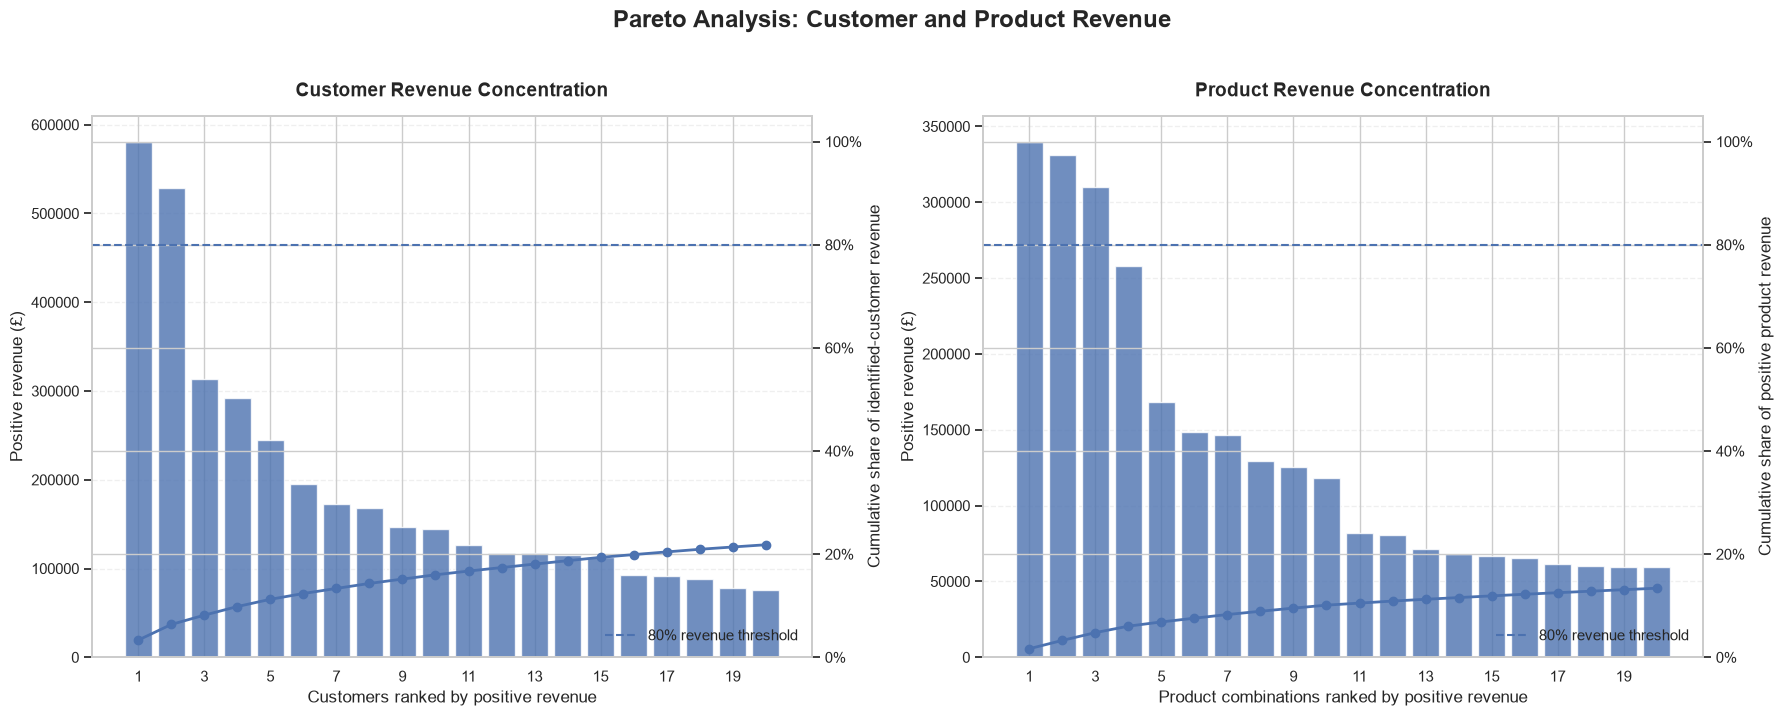


VALIDATION
Customer revenue reconciles: True
Product revenue reconciles: True
Customer cumulative revenue ends at 100%: True
Product cumulative revenue ends at 100%: True
Original dataset row count unchanged: True


In [111]:
# Step 11.1: Advanced Pareto Analysis — Customer and Product Revenue

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# --------------------------------------------------
# 1. Prepare positive-revenue transaction data
# --------------------------------------------------

positive_sales = df_clean.loc[
    df_clean["Revenue"] > 0
].copy()

print("PARETO ANALYSIS: DATA OVERVIEW")
print("=" * 65)
print(f"Positive-revenue transaction lines: {len(positive_sales):,}")
print(
    f"Total positive line revenue: "
    f"£{positive_sales['Revenue'].sum():,.2f}"
)

# --------------------------------------------------
# 2. Customer revenue concentration
# Exclude transactions without an identified customer
# --------------------------------------------------

customer_sales = positive_sales.loc[
    positive_sales["Customer ID"].notna()
].copy()

customer_pareto = (
    customer_sales.groupby("Customer ID", as_index=False)
    .agg(
        Positive_Revenue=("Revenue", "sum"),
        Transaction_Lines=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique")
    )
    .sort_values("Positive_Revenue", ascending=False)
    .reset_index(drop=True)
)

customer_pareto["Cumulative_Revenue"] = (
    customer_pareto["Positive_Revenue"].cumsum()
)

customer_pareto["Cumulative_Revenue_Share"] = (
    customer_pareto["Cumulative_Revenue"]
    / customer_pareto["Positive_Revenue"].sum()
)

customer_pareto["Customer_Rank"] = (
    np.arange(1, len(customer_pareto) + 1)
)

customer_pareto["Cumulative_Customer_Share"] = (
    customer_pareto["Customer_Rank"]
    / len(customer_pareto)
)

customer_80_count = int(
    (customer_pareto["Cumulative_Revenue_Share"] < 0.80).sum()
) + 1

customer_80_count = min(
    customer_80_count, len(customer_pareto)
)

customer_80_share = customer_pareto.loc[
    customer_80_count - 1, "Cumulative_Revenue_Share"
]

# --------------------------------------------------
# 3. Product revenue concentration
# Use StockCode and Description to preserve distinctions
# --------------------------------------------------

product_pareto = (
    positive_sales.groupby(
        ["StockCode", "Description"],
        dropna=False,
        as_index=False
    )
    .agg(
        Positive_Revenue=("Revenue", "sum"),
        Transaction_Lines=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique")
    )
    .sort_values("Positive_Revenue", ascending=False)
    .reset_index(drop=True)
)

product_pareto["Cumulative_Revenue"] = (
    product_pareto["Positive_Revenue"].cumsum()
)

product_pareto["Cumulative_Revenue_Share"] = (
    product_pareto["Cumulative_Revenue"]
    / product_pareto["Positive_Revenue"].sum()
)

product_pareto["Product_Rank"] = (
    np.arange(1, len(product_pareto) + 1)
)

product_pareto["Cumulative_Product_Share"] = (
    product_pareto["Product_Rank"]
    / len(product_pareto)
)

product_80_count = int(
    (product_pareto["Cumulative_Revenue_Share"] < 0.80).sum()
) + 1

product_80_count = min(
    product_80_count, len(product_pareto)
)

product_80_share = product_pareto.loc[
    product_80_count - 1, "Cumulative_Revenue_Share"
]

# --------------------------------------------------
# 4. Print key concentration metrics
# --------------------------------------------------

print("\nCUSTOMER REVENUE CONCENTRATION")
print("=" * 65)
print(f"Customers with identified positive sales: {len(customer_pareto):,}")
print(
    f"Top 10 customers' share of identified positive revenue: "
    f"{customer_pareto.head(10)['Positive_Revenue'].sum() / customer_pareto['Positive_Revenue'].sum():.2%}"
)
print(
    f"Customers needed to reach at least 80% of revenue: "
    f"{customer_80_count:,}"
)
print(f"Revenue share at that point: {customer_80_share:.2%}")
print(
    f"Share of identified customers needed: "
    f"{customer_80_count / len(customer_pareto):.2%}"
)

print("\nPRODUCT REVENUE CONCENTRATION")
print("=" * 65)
print(f"Distinct StockCode-description combinations: {len(product_pareto):,}")
print(
    f"Top 10 product combinations' share of positive revenue: "
    f"{product_pareto.head(10)['Positive_Revenue'].sum() / product_pareto['Positive_Revenue'].sum():.2%}"
)
print(
    f"Product combinations needed to reach at least 80% of revenue: "
    f"{product_80_count:,}"
)
print(f"Revenue share at that point: {product_80_share:.2%}")
print(
    f"Share of product combinations needed: "
    f"{product_80_count / len(product_pareto):.2%}"
)

# --------------------------------------------------
# 5. Create professional Pareto charts
# Display the leading 20 entities; cumulative shares
# are calculated across the full populations.
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Customer Pareto chart
top_customers = customer_pareto.head(20)
x_customer = np.arange(len(top_customers))

axes[0].bar(
    x_customer,
    top_customers["Positive_Revenue"],
    alpha=0.8
)

axes[0].set_title(
    "Customer Revenue Concentration",
    fontsize=14,
    fontweight="bold",
    pad=14
)
axes[0].set_xlabel("Customers ranked by positive revenue")
axes[0].set_ylabel("Positive revenue (£)")
axes[0].set_xticks(
    x_customer[::2],
    labels=[str(i) for i in top_customers["Customer_Rank"].iloc[::2]]
)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

customer_axis2 = axes[0].twinx()
customer_axis2.plot(
    x_customer,
    top_customers["Cumulative_Revenue_Share"] * 100,
    marker="o",
    linewidth=2
)
customer_axis2.axhline(
    80,
    linestyle="--",
    linewidth=1.5,
    label="80% revenue threshold"
)
customer_axis2.set_ylabel("Cumulative share of identified-customer revenue")
customer_axis2.yaxis.set_major_formatter(PercentFormatter(xmax=100))
customer_axis2.set_ylim(0, 105)
customer_axis2.legend(loc="lower right", frameon=False)

# Product Pareto chart
top_products = product_pareto.head(20)
x_product = np.arange(len(top_products))

axes[1].bar(
    x_product,
    top_products["Positive_Revenue"],
    alpha=0.8
)

axes[1].set_title(
    "Product Revenue Concentration",
    fontsize=14,
    fontweight="bold",
    pad=14
)
axes[1].set_xlabel("Product combinations ranked by positive revenue")
axes[1].set_ylabel("Positive revenue (£)")
axes[1].set_xticks(
    x_product[::2],
    labels=[str(i) for i in top_products["Product_Rank"].iloc[::2]]
)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

product_axis2 = axes[1].twinx()
product_axis2.plot(
    x_product,
    top_products["Cumulative_Revenue_Share"] * 100,
    marker="o",
    linewidth=2
)
product_axis2.axhline(
    80,
    linestyle="--",
    linewidth=1.5,
    label="80% revenue threshold"
)
product_axis2.set_ylabel("Cumulative share of positive product revenue")
product_axis2.yaxis.set_major_formatter(PercentFormatter(xmax=100))
product_axis2.set_ylim(0, 105)
product_axis2.legend(loc="lower right", frameon=False)

fig.suptitle(
    "Pareto Analysis: Customer and Product Revenue",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

fig.tight_layout()
plt.show()

# --------------------------------------------------
# 6. Validation
# --------------------------------------------------

print("\nVALIDATION")
print("=" * 65)

print(
    "Customer revenue reconciles:",
    np.isclose(
        customer_pareto["Positive_Revenue"].sum(),
        customer_sales["Revenue"].sum()
    )
)

print(
    "Product revenue reconciles:",
    np.isclose(
        product_pareto["Positive_Revenue"].sum(),
        positive_sales["Revenue"].sum()
    )
)

print(
    "Customer cumulative revenue ends at 100%:",
    np.isclose(
        customer_pareto["Cumulative_Revenue_Share"].iloc[-1],
        1.0
    )
)

print(
    "Product cumulative revenue ends at 100%:",
    np.isclose(
        product_pareto["Cumulative_Revenue_Share"].iloc[-1],
        1.0
    )
)

print(
    "Original dataset row count unchanged:",
    len(df_clean) == 1_044_848
)

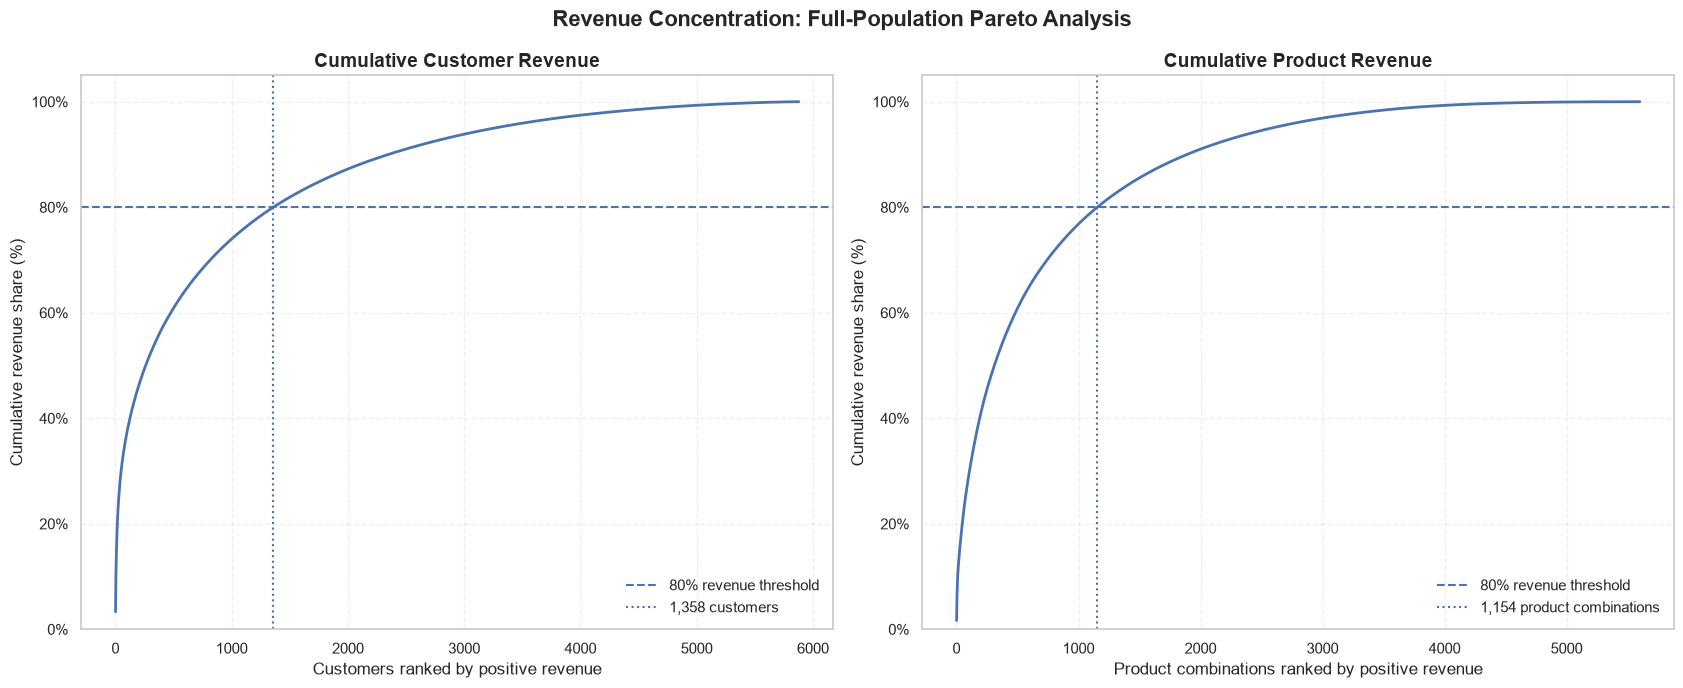

In [112]:
# Step 11.2: Full-Population Pareto Charts

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Customer Pareto
customer_rank = np.arange(1, len(customer_pareto) + 1)

axes[0].plot(
    customer_rank,
    customer_pareto["Cumulative_Revenue_Share"] * 100,
    linewidth=2
)

axes[0].axhline(
    80,
    linestyle="--",
    linewidth=1.5,
    label="80% revenue threshold"
)

axes[0].axvline(
    customer_80_count,
    linestyle=":",
    linewidth=1.5,
    label=f"{customer_80_count:,} customers"
)

axes[0].set_title(
    "Cumulative Customer Revenue",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_xlabel("Customers ranked by positive revenue")
axes[0].set_ylabel("Cumulative revenue share (%)")
axes[0].set_ylim(0, 105)
axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=100))
axes[0].grid(True, linestyle="--", alpha=0.3)
axes[0].legend(frameon=False)

# Product Pareto
product_rank = np.arange(1, len(product_pareto) + 1)

axes[1].plot(
    product_rank,
    product_pareto["Cumulative_Revenue_Share"] * 100,
    linewidth=2
)

axes[1].axhline(
    80,
    linestyle="--",
    linewidth=1.5,
    label="80% revenue threshold"
)

axes[1].axvline(
    product_80_count,
    linestyle=":",
    linewidth=1.5,
    label=f"{product_80_count:,} product combinations"
)

axes[1].set_title(
    "Cumulative Product Revenue",
    fontsize=14,
    fontweight="bold"
)
axes[1].set_xlabel("Product combinations ranked by positive revenue")
axes[1].set_ylabel("Cumulative revenue share (%)")
axes[1].set_ylim(0, 105)
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=100))
axes[1].grid(True, linestyle="--", alpha=0.3)
axes[1].legend(frameon=False)

fig.suptitle(
    "Revenue Concentration: Full-Population Pareto Analysis",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()
plt.show()

REVENUE SEASONALITY — MONTHLY SUMMARY


,Month_Name,Observed_Months,Average_Net_Revenue,Median_Net_Revenue,Minimum_Net_Revenue,Maximum_Net_Revenue
0,Jan,2,592016.58,592016.58,560000.26,624032.89
1,Feb,2,515577.04,515577.04,498062.65,533091.43
2,Mar,2,724557.92,724557.92,683267.08,765848.76
3,Apr,2,541893.78,541893.78,493207.12,590580.43
4,May,2,669328.17,669328.17,615322.83,723333.51
5,Jun,2,685454.86,685454.86,679786.61,691123.12
6,Jul,2,628268.24,628268.24,575236.36,681300.11
7,Aug,2,669728.43,669728.43,656776.34,682680.51
8,Sep,2,936669.03,936669.03,853650.43,1019687.62
9,Oct,2,1057936.51,1057936.51,1045168.35,1070704.67



2010 VS 2011 MONTHLY REVENUE


Year,2010,2011,Month_Name,YoY_Change_Percent
0,624032.89,560000.26,Jan,-10.26
1,533091.43,498062.65,Feb,-6.57
2,765848.76,683267.08,Mar,-10.78
3,590580.43,493207.12,Apr,-16.49
4,615322.83,723333.51,May,17.55
5,679786.61,691123.12,Jun,1.67
6,575236.36,681300.11,Jul,18.44
7,656776.34,682680.51,Aug,3.94
8,853650.43,1019687.62,Sep,19.45
9,1045168.35,1070704.67,Oct,2.44


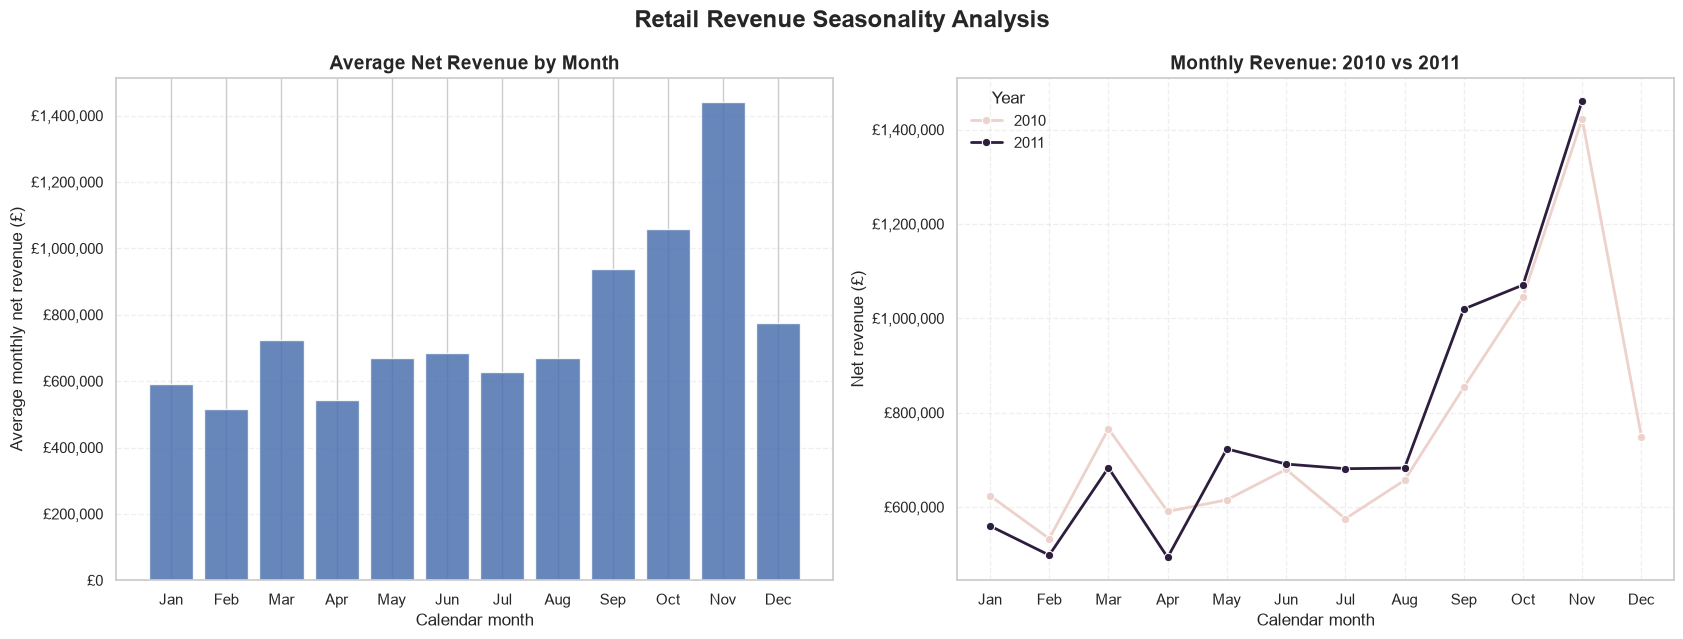


VALIDATION
December 2011 excluded from full-month comparisons: True
Monthly revenue reconciles to source transactions: True
Seasonality monthly totals reconcile: True
Original dataset row count unchanged: True


In [113]:
# Step 11.3: Revenue Seasonality Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# --------------------------------------------------
# 1. Prepare monthly revenue data
# --------------------------------------------------

seasonal_data = df_clean.copy()

seasonal_data["InvoiceDate"] = pd.to_datetime(
    seasonal_data["InvoiceDate"]
)

seasonal_data["Year"] = seasonal_data["InvoiceDate"].dt.year
seasonal_data["Month_Number"] = seasonal_data["InvoiceDate"].dt.month
seasonal_data["Month_Name"] = seasonal_data["InvoiceDate"].dt.strftime("%b")

monthly_seasonality = (
    seasonal_data.groupby(
        ["Year", "Month_Number", "Month_Name"],
        as_index=False
    )
    .agg(
        Net_Revenue=("Revenue", "sum"),
        Positive_Revenue=("Revenue", lambda x: x[x > 0].sum()),
        Negative_Revenue=("Revenue", lambda x: x[x < 0].sum()),
        Unique_Invoices=("Invoice", "nunique"),
        Transaction_Lines=("Invoice", "size")
    )
)

# December 2011 is incomplete: exclude it from full-month comparisons.
complete_months = monthly_seasonality.loc[
    ~(
        (monthly_seasonality["Year"] == 2011)
        & (monthly_seasonality["Month_Number"] == 12)
    )
].copy()

# Keep only months with data in both complete calendar years.
year_comparison = complete_months.loc[
    complete_months["Year"].isin([2010, 2011])
].copy()

month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# --------------------------------------------------
# 2. Compare revenue by month of year
# --------------------------------------------------

seasonal_summary = (
    complete_months.groupby("Month_Number", as_index=False)
    .agg(
        Average_Net_Revenue=("Net_Revenue", "mean"),
        Median_Net_Revenue=("Net_Revenue", "median"),
        Minimum_Net_Revenue=("Net_Revenue", "min"),
        Maximum_Net_Revenue=("Net_Revenue", "max"),
        Observed_Months=("Net_Revenue", "count")
    )
)

seasonal_summary["Month_Name"] = seasonal_summary[
    "Month_Number"
].map(lambda x: month_order[x - 1])

seasonal_summary = seasonal_summary.sort_values("Month_Number")

print("REVENUE SEASONALITY — MONTHLY SUMMARY")
print("=" * 75)

display(
    seasonal_summary[
        [
            "Month_Name",
            "Observed_Months",
            "Average_Net_Revenue",
            "Median_Net_Revenue",
            "Minimum_Net_Revenue",
            "Maximum_Net_Revenue"
        ]
    ].round(2)
)

# --------------------------------------------------
# 3. Year-on-year comparison for common full months
# --------------------------------------------------

year_pivot = year_comparison.pivot(
    index="Month_Number",
    columns="Year",
    values="Net_Revenue"
).reindex(range(1, 13))

year_pivot["Month_Name"] = [
    month_order[i - 1] for i in year_pivot.index
]

if 2010 in year_pivot.columns and 2011 in year_pivot.columns:
    year_pivot["YoY_Change_Percent"] = np.where(
        year_pivot[2010] != 0,
        (year_pivot[2011] - year_pivot[2010])
        / year_pivot[2010] * 100,
        np.nan
    )

print("\n2010 VS 2011 MONTHLY REVENUE")
print("=" * 75)

display(
    year_pivot.reset_index(drop=True).round(2)
)

# --------------------------------------------------
# 4. Professional seasonal visualisation
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

# Panel A: Average revenue by calendar month
axes[0].bar(
    seasonal_summary["Month_Name"],
    seasonal_summary["Average_Net_Revenue"],
    alpha=0.85
)

axes[0].set_title(
    "Average Net Revenue by Month",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_xlabel("Calendar month")
axes[0].set_ylabel("Average monthly net revenue (£)")
axes[0].yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"£{x:,.0f}")
)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

# Panel B: Month-by-year comparison
sns.lineplot(
    data=year_comparison,
    x="Month_Number",
    y="Net_Revenue",
    hue="Year",
    marker="o",
    linewidth=2,
    ax=axes[1]
)

axes[1].set_title(
    "Monthly Revenue: 2010 vs 2011",
    fontsize=14,
    fontweight="bold"
)
axes[1].set_xlabel("Calendar month")
axes[1].set_ylabel("Net revenue (£)")
axes[1].set_xticks(
    range(1, 13),
    month_order
)
axes[1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"£{x:,.0f}")
)
axes[1].grid(True, linestyle="--", alpha=0.3)
axes[1].legend(title="Year", frameon=False)

fig.suptitle(
    "Retail Revenue Seasonality Analysis",
    fontsize=17,
    fontweight="bold"
)

fig.tight_layout()
plt.show()

# --------------------------------------------------
# 5. Validation
# --------------------------------------------------

print("\nVALIDATION")
print("=" * 50)

print(
    "December 2011 excluded from full-month comparisons:",
    not (
        (complete_months["Year"] == 2011)
        & (complete_months["Month_Number"] == 12)
    ).any()
)

print(
    "Monthly revenue reconciles to source transactions:",
    np.isclose(
        monthly_seasonality["Net_Revenue"].sum(),
        df_clean["Revenue"].sum()
    )
)

print(
    "Seasonality monthly totals reconcile:",
    np.isclose(
        complete_months["Net_Revenue"].sum(),
        complete_months.groupby(
            ["Year", "Month_Number"]
        )["Net_Revenue"].sum().sum()
    )
)

print(
    "Original dataset row count unchanged:",
    len(df_clean) == 1_044_848
)

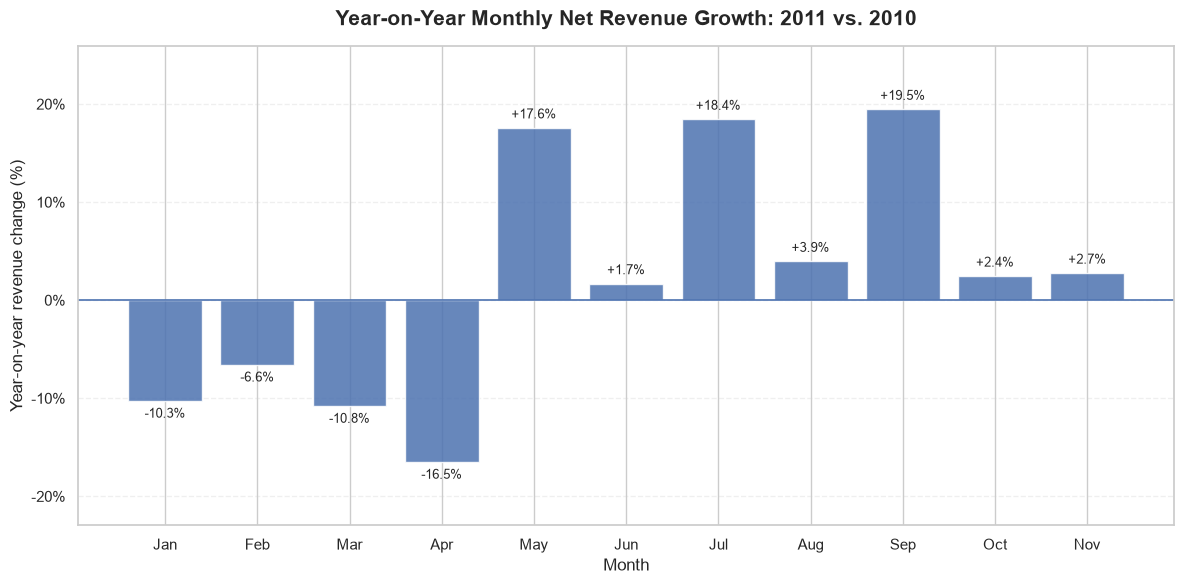

VALIDATION
All displayed growth values are valid: True
December excluded due to incomplete 2011 data: True
Exactly 11 comparable months: True
Growth values match the existing comparison table: True


In [114]:
# Step 11.4: Year-on-Year Revenue Growth Visualisation — Corrected

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Create a fresh DataFrame from the existing year_pivot
growth_data = year_pivot.copy()

# Ensure month numbers are available as a regular column
growth_data = growth_data.reset_index()

# Rename the index column to Month_Number if needed
if "Month_Number" not in growth_data.columns:
    growth_data = growth_data.rename(
        columns={growth_data.columns[0]: "Month_Number"}
    )

# Keep only months with valid year-on-year comparisons
growth_data = growth_data.loc[
    growth_data["YoY_Change_Percent"].notna()
].copy()

# Sort chronologically
growth_data = growth_data.sort_values("Month_Number")

# --------------------------------------------------
# Create the chart
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    growth_data["Month_Name"],
    growth_data["YoY_Change_Percent"],
    alpha=0.85
)

ax.axhline(0, linewidth=1.2)

ax.set_title(
    "Year-on-Year Monthly Net Revenue Growth: 2011 vs. 2010",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Month")
ax.set_ylabel("Year-on-year revenue change (%)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:.0f}%")
)

ax.grid(axis="y", linestyle="--", alpha=0.3)

# Add percentage labels to the bars
for bar, value in zip(
    bars,
    growth_data["YoY_Change_Percent"]
):
    ax.annotate(
        f"{value:+.1f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            value
        ),
        xytext=(0, 5 if value >= 0 else -5),
        textcoords="offset points",
        ha="center",
        va="bottom" if value >= 0 else "top",
        fontsize=9
    )

ax.margins(y=0.18)

fig.tight_layout()
plt.show()

# --------------------------------------------------
# Validation
# --------------------------------------------------

print("VALIDATION")
print("=" * 45)

print(
    "All displayed growth values are valid:",
    growth_data["YoY_Change_Percent"].notna().all()
)

print(
    "December excluded due to incomplete 2011 data:",
    "Dec" not in growth_data["Month_Name"].values
)

print(
    "Exactly 11 comparable months:",
    len(growth_data) == 11
)

print(
    "Growth values match the existing comparison table:",
    np.allclose(
        growth_data["YoY_Change_Percent"].to_numpy(),
        year_pivot.loc[
            growth_data["Month_Number"].to_numpy(),
            "YoY_Change_Percent"
        ].to_numpy()
    )
)

MONTHLY REVENUE VS. INVOICE VOLUME


,Year_Month,Total_Revenue,Unique_Invoices,Net_Revenue_Per_Invoice,Revenue_Growth_Percent,Invoice_Growth_Percent,Growth_Gap_Percentage_Points
2,2010-02,533091.43,1969,270.74,-14.57,20.58,-35.15
5,2010-05,615322.83,2418,254.48,4.19,27.80,-23.61
3,2010-03,765848.76,2367,323.55,43.66,20.21,23.45
17,2011-05,723333.51,2162,334.57,46.66,23.97,22.69
8,2010-08,656776.34,1877,349.91,14.18,-6.94,21.12
6,2010-06,679786.61,2216,306.76,10.48,-8.35,18.83
16,2011-04,493207.12,1744,282.80,-27.82,-12.05,-15.76
21,2011-09,1019687.62,2327,438.20,49.37,33.97,15.40
11,2010-11,1422654.64,3669,387.75,36.12,23.74,12.37
20,2011-08,682680.51,1737,393.02,0.20,-9.86,10.06


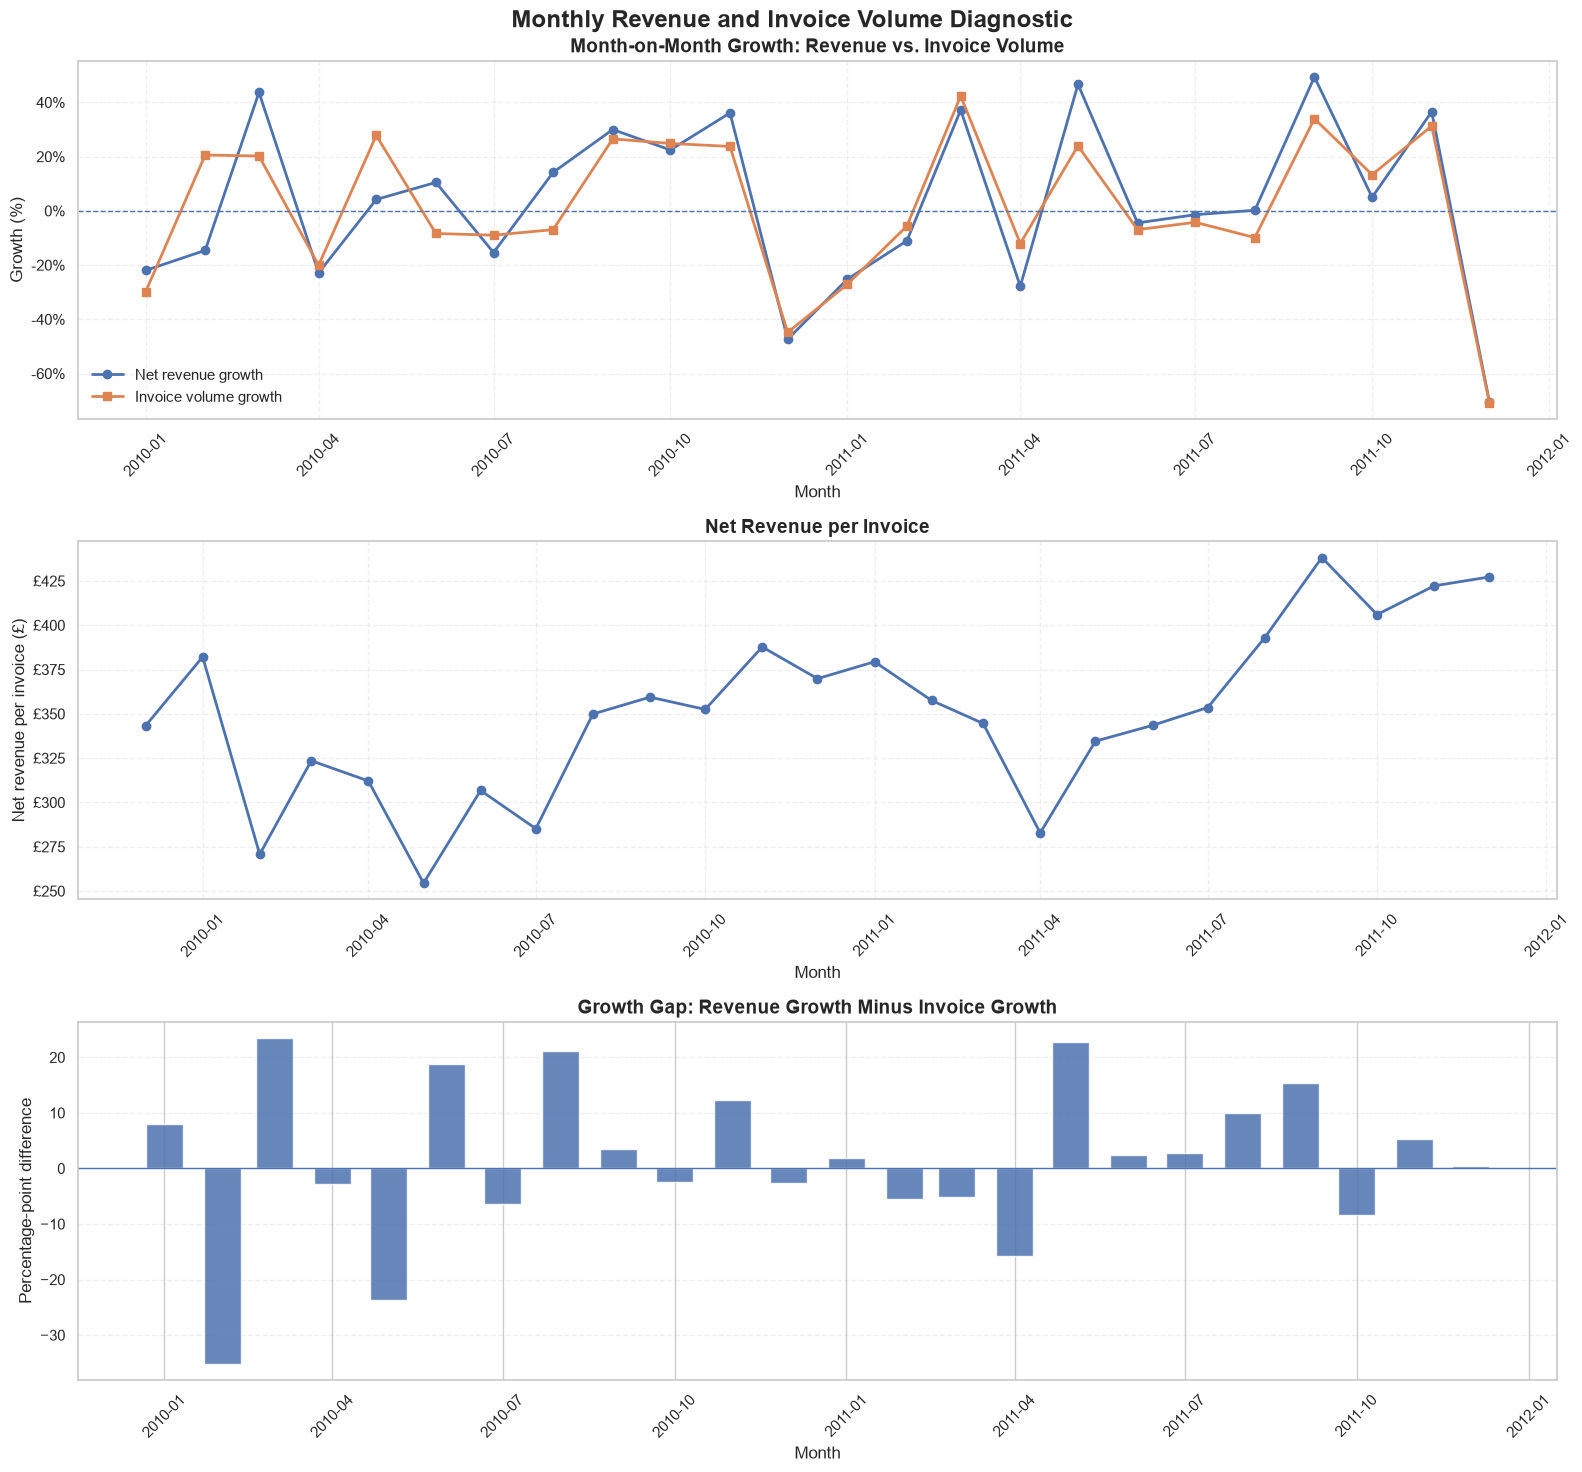


VALIDATION
Monthly revenue reconciles: True
Invoice counts reconcile: True
Revenue per invoice calculated correctly: True
Original dataset row count unchanged: True


In [115]:
# Step 11.5: Monthly Revenue vs. Invoice Volume Diagnostic — Corrected

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# --------------------------------------------------
# 1. Prepare monthly diagnostic data
# --------------------------------------------------

diagnostic = monthly_revenue.copy()

diagnostic["Month_Date"] = pd.to_datetime(
    diagnostic["Year_Month"].astype(str),
    format="%Y-%m",
    errors="coerce"
)

diagnostic = diagnostic.sort_values("Month_Date").reset_index(drop=True)

# Net revenue per invoice
diagnostic["Net_Revenue_Per_Invoice"] = np.where(
    diagnostic["Unique_Invoices"] > 0,
    diagnostic["Total_Revenue"] / diagnostic["Unique_Invoices"],
    np.nan
)

# Month-on-month growth
diagnostic["Revenue_Growth_Percent"] = (
    diagnostic["Total_Revenue"].pct_change() * 100
)

diagnostic["Invoice_Growth_Percent"] = (
    diagnostic["Unique_Invoices"].pct_change() * 100
)

# Difference between revenue growth and invoice growth
diagnostic["Growth_Gap_Percentage_Points"] = (
    diagnostic["Revenue_Growth_Percent"]
    - diagnostic["Invoice_Growth_Percent"]
)

# Flag the final month if it is incomplete
last_date = diagnostic["Month_Date"].max()

diagnostic["Month_Status"] = np.where(
    (diagnostic["Month_Date"].dt.year == last_date.year)
    & (diagnostic["Month_Date"].dt.month == last_date.month)
    & (last_date.day < last_date.days_in_month),
    "Potentially incomplete",
    "Observed"
)

# --------------------------------------------------
# 2. Display the 10 largest growth divergences
# --------------------------------------------------

comparison_data = diagnostic.dropna(
    subset=[
        "Revenue_Growth_Percent",
        "Invoice_Growth_Percent"
    ]
).copy()

comparison_data["Absolute_Growth_Gap"] = (
    comparison_data["Growth_Gap_Percentage_Points"].abs()
)

largest_divergences = (
    comparison_data
    .sort_values("Absolute_Growth_Gap", ascending=False)
    .head(10)
)

print("MONTHLY REVENUE VS. INVOICE VOLUME")
print("=" * 75)

display(
    largest_divergences[
        [
            "Year_Month",
            "Total_Revenue",
            "Unique_Invoices",
            "Net_Revenue_Per_Invoice",
            "Revenue_Growth_Percent",
            "Invoice_Growth_Percent",
            "Growth_Gap_Percentage_Points"
        ]
    ].round(2)
)

# --------------------------------------------------
# 3. Create diagnostic visualisations
# --------------------------------------------------

fig, axes = plt.subplots(3, 1, figsize=(16, 15))

x = diagnostic["Month_Date"]

# Chart A: Revenue growth vs. invoice growth
axes[0].plot(
    x,
    diagnostic["Revenue_Growth_Percent"],
    marker="o",
    linewidth=2,
    label="Net revenue growth"
)

axes[0].plot(
    x,
    diagnostic["Invoice_Growth_Percent"],
    marker="s",
    linewidth=2,
    label="Invoice volume growth"
)

axes[0].axhline(0, linewidth=1, linestyle="--")

axes[0].set_title(
    "Month-on-Month Growth: Revenue vs. Invoice Volume",
    fontsize=14,
    fontweight="bold"
)

axes[0].set_ylabel("Growth (%)")
axes[0].yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:.0f}%")
)
axes[0].grid(True, linestyle="--", alpha=0.3)
axes[0].legend(frameon=False)

# Chart B: Net revenue per invoice
axes[1].plot(
    x,
    diagnostic["Net_Revenue_Per_Invoice"],
    marker="o",
    linewidth=2
)

axes[1].set_title(
    "Net Revenue per Invoice",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_ylabel("Net revenue per invoice (£)")
axes[1].yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"£{value:,.0f}")
)
axes[1].grid(True, linestyle="--", alpha=0.3)

# Chart C: Growth gap
axes[2].bar(
    x,
    diagnostic["Growth_Gap_Percentage_Points"],
    width=20,
    alpha=0.85
)

axes[2].axhline(0, linewidth=1)

axes[2].set_title(
    "Growth Gap: Revenue Growth Minus Invoice Growth",
    fontsize=14,
    fontweight="bold"
)

axes[2].set_ylabel("Percentage-point difference")
axes[2].grid(axis="y", linestyle="--", alpha=0.3)

for ax in axes:
    ax.set_xlabel("Month")
    ax.tick_params(axis="x", rotation=45)

fig.suptitle(
    "Monthly Revenue and Invoice Volume Diagnostic",
    fontsize=17,
    fontweight="bold"
)

fig.tight_layout()
plt.show()

# --------------------------------------------------
# 4. Validation
# --------------------------------------------------

print("\nVALIDATION")
print("=" * 50)

print(
    "Monthly revenue reconciles:",
    np.isclose(
        diagnostic["Total_Revenue"].sum(),
        monthly_revenue["Total_Revenue"].sum()
    )
)

print(
    "Invoice counts reconcile:",
    diagnostic["Unique_Invoices"].equals(
        monthly_revenue.sort_values("Year_Month")
        ["Unique_Invoices"].reset_index(drop=True)
    )
)

print(
    "Revenue per invoice calculated correctly:",
    np.allclose(
        diagnostic["Net_Revenue_Per_Invoice"].to_numpy(),
        (
            diagnostic["Total_Revenue"]
            / diagnostic["Unique_Invoices"]
        ).to_numpy(),
        equal_nan=True
    )
)

print(
    "Original dataset row count unchanged:",
    len(df_clean) == 1_044_848
)

## Targeted quality check

In [116]:
# Step 12.1: Final Data and Analytical Integrity Audit

import numpy as np
import pandas as pd

audit_results = []

def record_check(check_name, passed, details=""):
    audit_results.append({
        "Check": check_name,
        "Status": "PASS" if passed else "REVIEW",
        "Details": details
    })

# --------------------------------------------------
# 1. Dataset integrity
# --------------------------------------------------

record_check(
    "Combined dataset row count",
    len(df_combined) == 1_044_848,
    f"Rows: {len(df_combined):,}"
)

record_check(
    "Working dataset row count",
    len(df_clean) == 1_044_848,
    f"Rows: {len(df_clean):,}"
)

record_check(
    "Expected working columns present",
    all(
        col in df_clean.columns
        for col in [
            "Invoice", "StockCode", "Quantity",
            "InvoiceDate", "Price", "Country", "Revenue"
        ]
    ),
    f"Columns available: {len(df_clean.columns)}"
)

# --------------------------------------------------
# 2. Revenue calculation and reconciliation
# --------------------------------------------------

calculated_revenue = df_clean["Quantity"] * df_clean["Price"]

record_check(
    "Revenue equals Quantity × Price",
    np.allclose(
        df_clean["Revenue"].to_numpy(dtype=float),
        calculated_revenue.to_numpy(dtype=float),
        equal_nan=True
    ),
    "Checked at transaction-line level"
)

net_revenue = df_clean["Revenue"].sum()
positive_revenue = df_clean.loc[
    df_clean["Revenue"] > 0, "Revenue"
].sum()
negative_revenue = df_clean.loc[
    df_clean["Revenue"] < 0, "Revenue"
].sum()

record_check(
    "Positive + negative revenue equals net revenue",
    np.isclose(
        positive_revenue + negative_revenue,
        net_revenue
    ),
    f"Net revenue: £{net_revenue:,.2f}"
)

record_check(
    "No missing revenue values",
    df_clean["Revenue"].notna().all(),
    f"Missing: {df_clean['Revenue'].isna().sum():,}"
)

# --------------------------------------------------
# 3. Monthly revenue reconciliation
# --------------------------------------------------

monthly_total = monthly_revenue["Total_Revenue"].sum()

record_check(
    "Monthly revenue reconciles to transaction data",
    np.isclose(monthly_total, net_revenue),
    f"Monthly: £{monthly_total:,.2f}; "
    f"Transactions: £{net_revenue:,.2f}"
)

record_check(
    "Monthly revenue components reconcile",
    np.isclose(
        monthly_revenue["Positive_Revenue"].sum()
        + monthly_revenue["Negative_Revenue"].sum(),
        monthly_total
    ),
    "Positive and negative monthly components"
)

# --------------------------------------------------
# 4. Country and invoice reconciliation
# --------------------------------------------------

if "country_performance" in globals():
    country_total = country_performance["Net_Line_Revenue"].sum()

    record_check(
        "Country revenue reconciles",
        np.isclose(country_total, net_revenue),
        f"Country total: £{country_total:,.2f}"
    )

if "invoice_analysis" in globals():
    invoice_total = invoice_analysis["Net_Line_Revenue"].sum()

    record_check(
        "Invoice revenue reconciles",
        np.isclose(invoice_total, net_revenue),
        f"Invoice total: £{invoice_total:,.2f}"
    )

    record_check(
        "Invoice IDs are unique in invoice analysis",
        invoice_analysis["Invoice"].is_unique,
        f"Invoice records: {len(invoice_analysis):,}"
    )

# --------------------------------------------------
# 5. Identified-customer reconciliation
# --------------------------------------------------

identified_revenue = df_clean.loc[
    df_clean["Customer ID"].notna(), "Revenue"
].sum()

if "customer_performance" in globals():
    customer_total = customer_performance["Net_Line_Revenue"].sum()

    record_check(
        "Customer revenue reconciles to identified transactions",
        np.isclose(customer_total, identified_revenue),
        f"Customer total: £{customer_total:,.2f}; "
        f"Identified transactions: £{identified_revenue:,.2f}"
    )

    record_check(
        "Customer IDs unique in customer performance",
        customer_performance["Customer ID"].is_unique,
        f"Customers: {len(customer_performance):,}"
    )

# --------------------------------------------------
# 6. Date coverage and incomplete final month
# --------------------------------------------------

dates = pd.to_datetime(df_clean["InvoiceDate"], errors="coerce")

first_date = dates.min()
last_date = dates.max()

record_check(
    "Invoice dates have no missing or invalid values",
    dates.notna().all(),
    f"First: {first_date}; Last: {last_date}"
)

if pd.notna(last_date):
    final_month_complete = last_date.day == last_date.days_in_month

    record_check(
        "Final calendar month completeness identified",
        True,
        f"Last transaction: {last_date}; "
        f"Final month appears "
        f"{'complete by date' if final_month_complete else 'incomplete'}"
    )

# --------------------------------------------------
# 7. Missing customer IDs and negative transactions
# --------------------------------------------------

missing_customer_count = df_clean["Customer ID"].isna().sum()
negative_transaction_count = (df_clean["Revenue"] < 0).sum()

record_check(
    "Missing customer IDs quantified",
    True,
    f"{missing_customer_count:,} rows "
    f"({missing_customer_count / len(df_clean):.2%})"
)

record_check(
    "Negative-revenue transactions quantified",
    True,
    f"{negative_transaction_count:,} rows; "
    f"£{negative_revenue:,.2f}"
)

# --------------------------------------------------
# 8. Display audit results
# --------------------------------------------------

audit_report = pd.DataFrame(audit_results)

print("=" * 75)
print("FINAL DATA AND ANALYTICAL INTEGRITY AUDIT")
print("=" * 75)

display(audit_report)

passed_count = (audit_report["Status"] == "PASS").sum()
review_count = (audit_report["Status"] == "REVIEW").sum()

print("\nAUDIT SUMMARY")
print("=" * 45)
print(f"Checks passed: {passed_count}")
print(f"Items requiring review: {review_count}")
print(f"Total checks: {len(audit_report)}")

if review_count == 0:
    print("\nAll executed integrity checks passed.")
else:
    print("\nReview the flagged checks before finalising the notebook.")

FINAL DATA AND ANALYTICAL INTEGRITY AUDIT


,Check,Status,Details
0,Combined dataset row count,PASS,"Rows: 1,044,848"
1,Working dataset row count,PASS,"Rows: 1,044,848"
2,Expected working columns present,PASS,Columns available: 15
3,Revenue equals Quantity × Price,PASS,Checked at transaction-line level
4,Positive + negative revenue equals net revenue,PASS,"Net revenue: £18,909,762.12"
5,No missing revenue values,PASS,Missing: 0
6,Monthly revenue reconciles to transaction data,PASS,"Monthly: £18,909,762.12; Transactions: £18,909,762.12"
7,Monthly revenue components reconcile,PASS,Positive and negative monthly components
8,Country revenue reconciles,PASS,"Country total: £18,909,762.12"
9,Invoice revenue reconciles,PASS,"Invoice total: £18,909,762.12"



AUDIT SUMMARY
Checks passed: 17
Items requiring review: 0
Total checks: 17

All executed integrity checks passed.


# Retail Revenue & Customer Intelligence
## Final Business Insights and Recommendations

### 1. Executive Summary

This project analyses 1,044,848 transaction records from an online retail dataset covering December 2009 to December 2011. Python and pandas were used to examine revenue trends, customer behaviour, product performance, invoice characteristics, international markets, revenue concentration, and customer segmentation.

The dataset generated net line revenue of £18.91 million, comprising £20.53 million in positive revenue and £1.62 million in negative revenue. The analysis identified significant differences in monthly performance, customer value, product contribution, invoice size, and geographic concentration.

The main business opportunity is to improve revenue quality and customer retention while reducing dependence on a concentrated customer base and understanding the drivers of returns, cancellations, and unusual transactions.

### 2. Key Business Findings

#### Finding 1: Revenue is concentrated among a relatively small group of customers

The customer revenue concentration analysis found that approximately 23.10% of identified customers accounted for 80% of positive customer revenue. The top 10 customers contributed 15.99% of identified positive revenue.

The RFM segmentation also identified 1,275 Champions, generating approximately £11.41 million in net line revenue. This represented around 69.8% of total identified-customer net line revenue.

**Business implication:** Losing a small number of high-value customers could have a material effect on revenue.

**Recommendation:**
- Establish a dedicated retention programme for high-value customers.
- Monitor purchase frequency, recency, and revenue contribution.
- Investigate declining activity among previously high-value customers.
- Develop personalised offers based on historical purchasing behaviour.
- Avoid excessive discounting for customers who are already purchasing regularly.

The revenue contribution of the Champions segment should be monitored alongside its customer count and retention rate.

#### Finding 2: Revenue performance varies considerably across months

November 2011 recorded the highest monthly net line revenue at approximately £1.46 million. April 2011 recorded approximately £493,207, the lowest among the complete months considered.

The monthly analysis also showed that revenue and invoice volume do not always move together. For example, in February 2010, net revenue declined by 14.57% while invoice volume increased by 20.58%. In August 2010, revenue increased by 14.18% even though invoice volume declined by 6.94%.

**Business implication:** Invoice volume alone is not sufficient to explain revenue performance. Changes in product mix, customer mix, transaction values, and negative transactions may also contribute.

**Recommendation:**
- Monitor monthly revenue and invoice volume together.
- Investigate months where the two measures diverge significantly.
- Prepare seasonal inventory and staffing plans using the observed monthly pattern.
- Compare revenue growth with positive-sales revenue and returns separately.
- Avoid treating the incomplete December 2011 period as a full-month comparison.

The two-year history indicates a late-year revenue peak, but a longer observation period would be needed to establish a reliable recurring seasonal pattern.

#### Finding 3: A limited subset of product combinations contributes a substantial share of revenue

The product Pareto analysis found that approximately 20.61% of product combinations accounted for 80% of positive product revenue.

The leading products by net line revenue included the Regency Cake Stand 3 Tier, White Hanging Heart T-Light Holder, Party Bunting, and Jumbo Bag Red Retrospot.

The merchandise-focused analysis also identified products that remained important after provisionally excluding descriptions associated with postage, carriage, and selected adjustments.

**Business implication:** Product availability and merchandising decisions may have an outsized impact when they concern high-contribution products.

**Recommendation:**
- Monitor stock availability for high-revenue products.
- Review product-level revenue, quantities, invoice frequency, and returns together.
- Separate merchandise from postage, fees, and manual adjustments in management reporting.
- Investigate products with frequent negative transactions.
- Avoid discontinuing lower-revenue products solely on revenue rankings; consider margin, demand, strategic value, and customer relationships where those data are available.

The current analysis measures revenue, not product profitability, because product costs and margins have not been established.

#### Finding 4: Large invoices account for a substantial share of revenue

Invoices containing more than 20 transaction lines represented approximately 28.28% of all invoices and contributed about 61.43% of total net line revenue.

Among positive-revenue invoices, the group containing more than 20 lines contributed approximately 56.83% of positive invoice revenue.

The positive-revenue invoice distribution was also skewed: the mean was approximately £512.35, compared with a median of £302.79.

**Business implication:** A relatively small number of larger transactions can materially influence aggregate revenue and average invoice value.

**Recommendation:**
- Track invoice value and transaction-line count as separate measures.
- Identify products and customer groups associated with larger invoices.
- Review large invoices for unusual quantities, cancellations, or manual adjustments.
- Use median invoice value alongside mean invoice value to reduce the risk of misleading conclusions from exceptional transactions.
- Investigate whether larger invoices represent repeat wholesale-style purchases, bulk buying, or other purchasing patterns before changing commercial policy.

#### Finding 5: International markets offer opportunities, but the UK dominates the dataset

The UK contributed approximately £16.04 million, or 84.82%, of total net line revenue. The remaining 42 countries contributed approximately £2.87 million, or 15.18%.

Among international markets, the Netherlands recorded approximately £548,332 in net line revenue, while Germany recorded approximately £412,518. The Netherlands also had the highest net line revenue per invoice among the countries meeting the analysis's minimum threshold of 20 invoices.

**Business implication:** The business is heavily concentrated in one geographic market, while international markets differ in transaction volume and revenue per invoice.

**Recommendation:**
- Maintain a strong focus on the UK customer base.
- Compare international markets using revenue, invoice volume, customer count, and negative-revenue activity.
- Investigate the Netherlands and Australia as potential candidates for deeper market analysis.
- Use minimum sample-size thresholds when comparing average revenue per invoice.
- Assess delivery costs, taxes, fulfilment requirements, and market profitability before investing in international expansion.

Revenue per invoice should not be treated as profit per invoice.

#### Finding 6: Negative revenue is material and requires structured investigation

The dataset contains £1.62 million in negative revenue, offsetting part of the £20.53 million in positive revenue.

The negative-revenue investigation identified manual entries, discounts, samples, fees, and product-related transactions. Some large negative transactions were exact reversals of earlier positive transactions. Other records, including large AMAZONFEE entries, require additional contextual investigation.

**Business implication:** Negative transactions materially affect net revenue and can distort product, customer, country, and monthly comparisons if they are not understood.

**Recommendation:**
- Separate returns, cancellations, fees, discounts, and manual adjustments into clearly defined reporting categories where source data supports reliable classification.
- Investigate high-value negative transactions and their corresponding positive transactions.
- Reconcile unusual manual entries against source invoices and accounting records.
- Track negative revenue as a proportion of positive revenue.
- Preserve original records and document any exclusion rules used in analytical views.

The current classifications are provisional where they rely on text descriptions. They do not establish the precise reason for every negative transaction.

#### Finding 7: Customer identification is incomplete

Customer ID is missing for 235,287 transaction rows, equivalent to 22.52% of the dataset.

Customer-level analyses therefore describe identified customers rather than the complete population of transactions. This limitation is particularly relevant when interpreting customer concentration, customer lifetime patterns, and RFM segments.

**Business implication:** Some customer activity cannot be attributed to a known customer, limiting the completeness of retention and customer-value analysis.

**Recommendation:**
- Improve customer identification at the transaction-capture stage.
- Report the proportion of revenue associated with identified versus unidentified customers.
- Keep unidentified transactions separate from customer-level conclusions.
- Avoid assuming that missing Customer IDs represent unique individuals.
- Consider the impact of missing identification when designing customer retention campaigns.

#### Finding 8: Revenue concentration makes a combined monitoring framework valuable

The customer and product Pareto analyses show that revenue is concentrated among a subset of customers and product combinations. The RFM analysis adds another perspective by identifying customers with different combinations of recency, frequency, and monetary value.

**Business implication:** Monitoring only total revenue can conceal changes in the customers and products generating it.

**Recommendation:**
Create a recurring management scorecard containing:
- Net and positive revenue.
- Negative revenue and its proportion of positive revenue.
- Invoice count and median invoice value.
- Revenue contribution from high-value customers.
- Customer recency and frequency.
- Top product combinations by revenue.
- Revenue by country.
- High-value and unusual transactions.
- Missing customer identification rate.

These measures should be reviewed together rather than interpreted in isolation.

### 3. Recommended Priorities

**Priority 1 — Protect high-value customers**

Monitor Champions and other high-value customers for changes in recency, purchase frequency, and revenue contribution.

**Priority 2 — Improve revenue quality and transaction controls**

Investigate large negative transactions, manual entries, fees, and unusual invoice values. Preserve the original data and document classification assumptions.

**Priority 3 — Strengthen product and inventory decisions**

Use product revenue, quantities, invoice frequency, and return patterns together to identify products requiring attention.

**Priority 4 — Improve geographic and seasonal planning**

Use monthly and country-level analysis to guide further investigation, while accounting for incomplete periods, market concentration, and differences in transaction volume.

**Priority 5 — Improve customer identification**

Reduce the proportion of transactions without a Customer ID where operationally possible, improving the reliability of customer analytics.

### 4. Limitations and Interpretation Boundaries

The findings should be interpreted in light of the following limitations:

1. **Historical data:** The dataset ends on 9 December 2011. Its recency groups do not describe customers' current behaviour.
2. **Revenue is not profit:** Product costs, operating costs, delivery costs, and other expenses are not included in the current revenue calculations.
3. **Returns and adjustments:** Negative transactions influence net line revenue and can affect rankings and averages.
4. **Missing customer identifiers:** Customer-level analysis excludes transactions without a Customer ID.
5. **Provisional classifications:** Description-based categories for fees, adjustments, and other exceptions require business validation.
6. **Limited seasonal history:** Two observed years provide useful descriptive comparisons but are insufficient to establish a robust long-term seasonal pattern.
7. **No causal claims:** The analysis identifies associations and patterns, not proof that a specific factor caused revenue to change.

### 5. Conclusion

The project demonstrates how Python-based analysis can transform a large retail transaction dataset into actionable commercial insights. The strongest findings concern customer revenue concentration, product contribution, invoice-size patterns, geographic dependence, monthly variation, and the financial impact of negative transactions.

The most valuable next steps are to protect high-value customers, investigate unusual negative transactions, improve customer identification, and build a repeatable performance-monitoring framework.

The recommendations should be treated as evidence-based directions for further investigation rather than confirmed financial outcomes. Additional cost, margin, operational, and more recent customer data would be required to quantify profitability and validate the expected impact of specific business actions.